# Computational Reproduction and Dynamical Analysis of Ritchie et al. (2023)

Notebook khảo sát **external forcing**, **frozen-system dynamics** và **Basin Instability** của tilted saddle-node model. Chạy các cell từ trên xuống bằng kernel Python 3. Các hàm tính toán nhận tham số tường minh, để có thể tái sử dụng khi khảo sát time-dependent dynamics.

**Nguồn chính.** Ritchie, P. D. L., Alkhayuon, H., Cox, P. M. & Wieczorek, S. (2023), *Rate-induced tipping in natural and human systems*, *Earth System Dynamics* 14, 669–683. Notebook dựa trên Section 2–4 và Appendix A1–A2. [PDF trong workspace](../paper/23%20Rate-induced%20tipping%20in%20natural%20and%20human%20systems.pdf) · [Bài báo](https://doi.org/10.5194/esd-14-669-2023)

**Đối chiếu mã tác giả.** Script Figure 2 dùng cùng drift và ramp, với thời gian quy tâm $t_{\mathrm{code}}=t-T$. Khối tham số của script cho Figure 2(b,e) khớp với Appendix A2. [Script Figure 2](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Tilted_SN_timeseries_bif_rate_return_tipping_plots_v2.py)

Các mục ghi **Paper gốc** tóm tắt phương pháp và dữ kiện của tác giả. **Suy dẫn bổ sung** và **Thí nghiệm bổ sung** dùng mô hình đó để kiểm tra các kết quả giải tích và hình học. Phạm vi kết thúc ở Module 3.

## Mục lục

| Phần | Modules |
|---|---|
| Nền tảng | 1. External forcing · 2. Frozen dynamics · 3. Basin Instability |
| Conceptual model | 4. Figure 2 · 5. Figure 3 |
| Application models | 6. Plant–Herbivore · 7. AMOC · 8. Power grid |
| Tổng hợp | 9. Cross-model comparison · Final Notebook Validation |
| Kết quả cuối | Summary of Scientific and Methodological Insights |

Mỗi giai đoạn có cell tổng hợp riêng. Cell cuối tích hợp kết quả của toàn bộ case study.

In [1]:
import platform

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
})

# Appendix A2, Figure 2(b,e)
A_paper = 3.2
s_paper = 4.0
lambda_i = -0.5
delta_lambda_paper = 0.4
lambda_f = round(lambda_i + delta_lambda_paper, 12)
T_paper = 500.0
r_paper = (1.0, 3.0)

display(Markdown(f"Python {platform.python_version()} · NumPy {np.__version__} · "
                 f"SciPy {scipy.__version__} · Matplotlib {mpl.__version__}"))

Python 3.11.7 · NumPy 2.4.6 · SciPy 1.17.1 · Matplotlib 3.11.2

## Module 1 — External Forcing Design

### 1.1–1.2. Cấu trúc forcing

**Mục tiêu khoa học.** Tách ba thay đổi khi thiết kế thí nghiệm có đối chứng: mức forcing ban đầu, biên độ dịch chuyển và độ nhanh của profile.

**Paper gốc · Section 3, Appendix A1–A2.** Đặt $u=rt$, $z=u-rT=r(t-T)$ và viết $\lambda(t)=\lambda_-+\Delta\lambda\,a(rt)$, với
$$
a_{\mathrm{ramp}}(rt)=
\begin{cases}
\operatorname{sech}(z),&0\le t\le T,\\
1,&t>T,
\end{cases}
\qquad
a_{\mathrm{return}}(rt)=\operatorname{sech}(z).
$$

- $\lambda_-$ là mức tham chiếu ban đầu. $\Delta\lambda$ là **signed forcing shift** từ $\lambda_-$ tới cực trị tại $T$, nên cực trị có thể là cực tiểu khi $\Delta\lambda<0$.
- $r>0$ có đơn vị time$^{-1}$ và co giãn trục thời gian. $a(rt)$ và $z$ không có đơn vị. $T$ là lúc profile đạt $1$.
- Ramp tăng tới $1$ và giữ mức đó. Return đối xứng quanh $T$ và tiến về $0$ ở đuôi phải. Cả hai có cùng nhánh đi vào peak.

**Suy dẫn bổ sung · Sai số khởi tạo.** Ở $t=0$, sai số tuyệt đối so với $\lambda_-$ là $|\Delta\lambda|\operatorname{sech}(rT)$. Với $\Delta\lambda\ne0$, yêu cầu sai số tương đối theo biên độ không quá $0<\varepsilon<1$ tương đương
$$
\operatorname{sech}(rT)\le\varepsilon
\quad\Longleftrightarrow\quad
T\ge \frac{\operatorname{arcosh}(1/\varepsilon)}{r}.
$$
Khi dùng chung $T$ cho nhiều thí nghiệm, ta chọn theo $r$ nhỏ nhất. Appendix A2 áp dụng mức $a(0)\le10^{-4}$ cho Figure 3. Khi $\Delta\lambda=0$, forcing hằng bằng $\lambda_-$.

### 1.3. Rate parameter và actual forcing rate

**Mục tiêu khoa học.** Tìm đại lượng đo tốc độ thay đổi của forcing tại từng thời điểm và xác định cách thay đổi biên độ ảnh hưởng tới tốc độ đó.

**Suy dẫn bổ sung từ Section 3 và Eq. (A1)–(A2).** Chain rule cho $dz/dt=r$ và $d\operatorname{sech}(z)/dz=-\operatorname{sech}(z)\tanh(z)$, do đó
$$
\dot\lambda_{\mathrm{return}}=-r\Delta\lambda\,\operatorname{sech}(z)\tanh(z),
\qquad
\dot\lambda_{\mathrm{ramp}}=
\begin{cases}
-r\Delta\lambda\,\operatorname{sech}(z)\tanh(z),&t\le T,\\
0,&t>T.
\end{cases}
$$
Tại $T$, $\tanh(0)=0$ nên ramp nối trơn bậc một và return đổi dấu đạo hàm. Khi $\Delta\lambda>0$, tốc độ trước $T$ dương và tốc độ return sau $T$ âm. Tích $\operatorname{sech}(z)\tanh(z)$ phụ thuộc thời điểm, kể cả khi giữ $r$ cố định.

Đặt $w=\tanh(z)$, ta có $(\operatorname{sech}(z)\tanh(z))^2=w^2(1-w^2)$, đạt cực đại $1/4$ tại $w^2=1/2$. Vì vậy, trên profile đầy đủ,
$$
\max_t|\dot\lambda(t)|=\frac{r|\Delta\lambda|}{2},
\qquad
|t-T|=\frac{\operatorname{arctanh}(1/\sqrt{2})}{r}.
$$
Ramp chỉ có cực trị tốc độ trên nhánh đi vào peak nếu thời điểm đó thuộc cửa sổ khảo sát. $1/r$ là forcing timescale, còn $\dot\lambda$ có đơn vị forcing/time. Tăng $r$ làm profile hẹp hơn và tăng độ dốc cực đại. Tăng $|\Delta\lambda|$ cũng tăng độ dốc cực đại nhưng giữ nguyên độ rộng theo thời gian.

### 1.4. Cài đặt và kiểm tra forcing

Ta tính $\operatorname{sech}(z)$ qua $e^{-|z|}$ để tránh overflow khi đuôi profile rất xa peak. Quy ước $t\le T$ khớp với Appendix A1. Các hàm cũng hỗ trợ thời gian âm khi dùng hệ tọa độ quy tâm.

In [2]:
def sech(z):
    """Tính sech cho scalar hoặc NumPy array."""
    exp_abs = np.exp(-np.abs(z))
    return 2.0 * exp_abs / (1.0 + exp_abs**2)


def ramp_profile(t, r, T):
    """Eq. (A1), với peak tại T."""
    t = np.asarray(t, dtype=float)
    return np.where(t <= T, sech(r * (t - T)), 1.0)[()]


def return_profile(t, r, T):
    """Eq. (A2), với peak tại T."""
    t = np.asarray(t, dtype=float)
    return sech(r * (t - T))


FORCING_PROFILES = {"ramp": ramp_profile, "return": return_profile}


def external_forcing(t, lambda_minus, delta_lambda, r, T, profile="ramp"):
    return lambda_minus + delta_lambda * FORCING_PROFILES[profile](t, r, T)


def forcing_derivative(t, delta_lambda, r, T, profile="ramp"):
    if profile not in FORCING_PROFILES:
        raise ValueError(f"Profile không hợp lệ: {profile!r}")
    t = np.asarray(t, dtype=float)
    z = r * (t - T)
    derivative = -r * delta_lambda * sech(z) * np.tanh(z)
    if profile == "ramp":
        derivative = np.where(t <= T, derivative, 0.0)
    return derivative[()]


def minimum_peak_time(r, relative_tolerance=1e-4):
    """Thời gian peak nhỏ nhất với r > 0 và 0 < relative_tolerance < 1."""
    return np.arccosh(1.0 / relative_tolerance) / r

In [3]:
r_values = (0.5, 1.0, 2.0)
T_demo = np.ceil(minimum_peak_time(min(r_values)))
t_demo = np.linspace(0.0, T_demo + 12.0, 1401)
t_check = T_demo + np.array([-2.0, -0.7, 0.0, 0.6, 2.0])
h = 1e-5
t_peak_rate = T_demo - np.arctanh(1.0 / np.sqrt(2.0))

for profile in FORCING_PROFILES:
    for shift in (delta_lambda_paper, -delta_lambda_paper, 0.0):
        numerical_derivative = (
            external_forcing(t_check + h, lambda_i, shift, 1.0, T_demo, profile)
            - external_forcing(t_check - h, lambda_i, shift, 1.0, T_demo, profile)
        ) / (2.0 * h)
        np.testing.assert_allclose(
            numerical_derivative, forcing_derivative(t_check, shift, 1.0, T_demo, profile),
            atol=1.1e-6, rtol=1e-7,
        )
    assert np.isscalar(external_forcing(T_demo, lambda_i, 0.4, 1.0, T_demo, profile))
    assert forcing_derivative(T_demo, 0.4, 1.0, T_demo, profile) == 0.0
    np.testing.assert_allclose(
        forcing_derivative(t_peak_rate, 0.4, 1.0, T_demo, profile), 0.2,
    )

assert ramp_profile(0, min(r_values), T_demo) <= 1e-4
assert ramp_profile(T_demo + 1, 1, T_demo) == 1.0
np.testing.assert_allclose(return_profile(T_demo + 1, 1, T_demo),
                           return_profile(T_demo - 1, 1, T_demo))
# Đối chiếu Eq. (A1) với thời gian quy tâm trong script Figure 2.
t_centered = np.array([-9.0, -0.6, 0.0, 0.7, 8.0])
for r in r_paper:
    a_centered = np.where(t_centered <= 0, 1 / np.cosh(r * t_centered), 1)
    np.testing.assert_allclose(
        external_forcing(t_centered + T_paper, lambda_i, delta_lambda_paper, r, T_paper),
        lambda_i + delta_lambda_paper * a_centered, atol=1e-13, rtol=0,
    )
a_initial_max = ramp_profile(0, min(r_values), T_demo)
display(Markdown(f"Với sweep minh họa, $T={T_demo:g}$ và $a(0)$ lớn nhất "
                 f"bằng {a_initial_max:.3e}. Đã kiểm tra đạo hàm, peak và mốc thời gian quy tâm."))

Với sweep minh họa, $T=20$ và $a(0)$ lớn nhất bằng 9.080e-05. Đã kiểm tra đạo hàm, peak và mốc thời gian quy tâm.

Sai phân trung tâm kiểm tra đạo hàm ở hai phía của peak, tại điểm nối và cho cả shift âm. Khởi tạo gần $\lambda_-$ nhất khi $r$ lớn hơn, với $T$ giữ cố định.

### 1.5. Thí nghiệm 1 — Ảnh hưởng của rate parameter

**Thí nghiệm bổ sung.** Giữ $\lambda_-=-0.5$ và $\Delta\lambda=0.4$. Thay $r$ để kiểm tra xem profile có cùng cực trị nhưng độ rộng và độ dốc khác nhau hay không. Đường chấm đứng đánh dấu $T$.

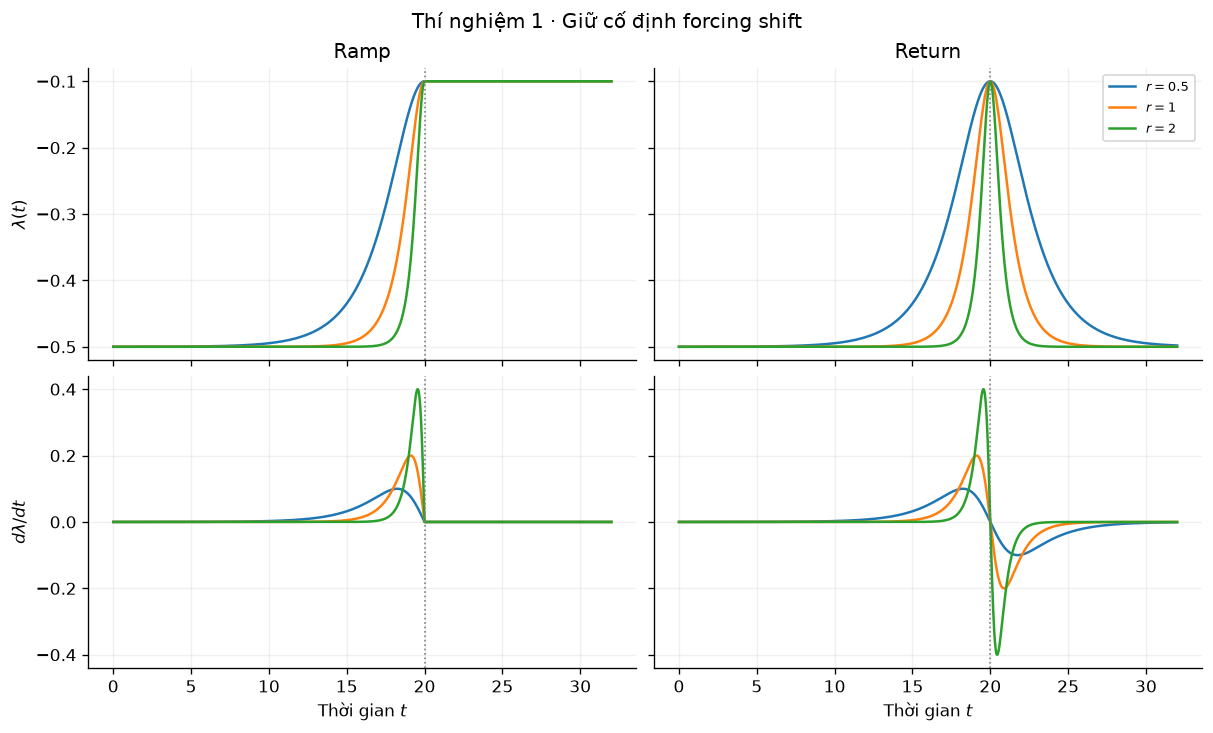

In [4]:
def plot_forcing_sweep(t, lambda_minus, T, cases, title):
    """Mỗi case gồm (nhãn, delta_lambda, r)."""
    fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey="row",
                             layout="constrained")
    for col, profile in enumerate(FORCING_PROFILES):
        axes[0, col].set_title(profile.capitalize())
        for label, shift, rate in cases:
            axes[0, col].plot(t, external_forcing(t, lambda_minus, shift, rate, T, profile),
                              label=label)
            axes[1, col].plot(t, forcing_derivative(t, shift, rate, T, profile), label=label)
        axes[1, col].set_xlabel("Thời gian $t$")
        for ax in axes[:, col]:
            ax.axvline(T, color="0.5", linestyle=":", linewidth=1)
            ax.grid(alpha=0.18)
    axes[0, 0].set_ylabel(r"$\lambda(t)$")
    axes[1, 0].set_ylabel(r"$d\lambda/dt$")
    axes[0, 1].legend(loc="upper right")
    fig.suptitle(title)
    plt.show()


plot_forcing_sweep(t_demo, lambda_i, T_demo,
                   [(f"$r={r:g}$", delta_lambda_paper, r) for r in r_values],
                   "Thí nghiệm 1 · Giữ cố định forcing shift")

*Hình 1.1.* Hai cột so sánh ramp và return, hai hàng biểu diễn forcing level và actual forcing rate. Khi $r$ tăng từ $0.5$ tới $2$, độ dốc cực đại tăng bốn lần (từ $0.10$ tới $0.40$), trong khi mức tại peak giữ ở $-0.1$. Ramp giữ mức mới và return có thêm nhánh tốc độ âm.

### Thí nghiệm 2 — Ảnh hưởng của forcing magnitude

**Thí nghiệm bổ sung.** Giữ $r=1$ để xem việc tăng $\Delta\lambda$ thay đổi biên độ của forcing và đạo hàm thế nào khi forcing timescale giữ nguyên.

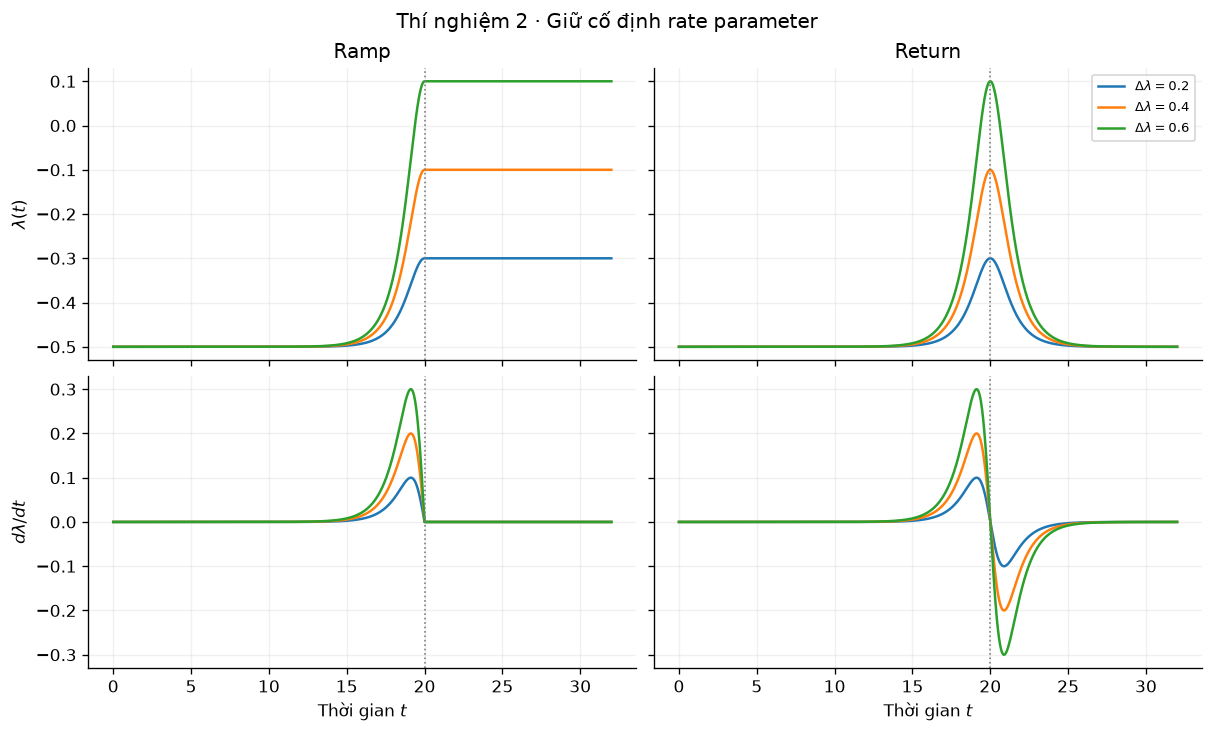

In [5]:
shift_values = (0.2, 0.4, 0.6)
plot_forcing_sweep(t_demo, lambda_i, T_demo,
                   [(rf"$\Delta\lambda={shift:g}$", shift, 1.0) for shift in shift_values],
                   "Thí nghiệm 2 · Giữ cố định rate parameter")

*Hình 1.2.* Các mức tại peak lần lượt là $-0.3$, $-0.1$ và $0.1$. Độ dốc cực đại tăng từ $0.10$ lên $0.30$ và thời điểm đạt độ dốc cực đại giữ nguyên. Với $\Delta\lambda=0.6$, forcing level tự nó vượt $0$ trong một khoảng thời gian. Hệ quả đối với $x(t)$ cần được xác định bằng phương trình động lực.

### Thí nghiệm 3 — Ramp và return với cùng tham số

**Thí nghiệm bổ sung.** Chồng hai profiles ở cùng $r=1$ và $\Delta\lambda=0.4$ để cô lập hiệu ứng thay đổi forcing sau peak.

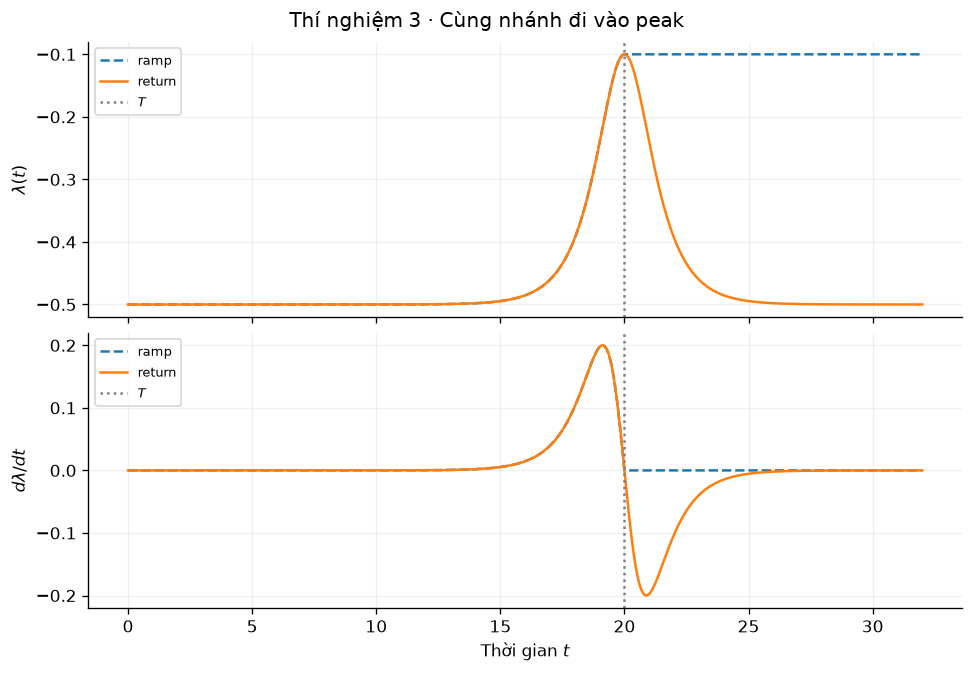

In [6]:
fig, (ax_level, ax_rate) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                                      layout="constrained")
for profile, linestyle in (("ramp", "--"), ("return", "-")):
    ax_level.plot(t_demo, external_forcing(t_demo, lambda_i, 0.4, 1.0, T_demo, profile),
                  linestyle=linestyle, label=profile)
    ax_rate.plot(t_demo, forcing_derivative(t_demo, 0.4, 1.0, T_demo, profile),
                 linestyle=linestyle, label=profile)
for ax in (ax_level, ax_rate):
    ax.axvline(T_demo, color="0.5", linestyle=":", label="$T$")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.18)
ax_level.set_ylabel(r"$\lambda(t)$")
ax_rate.set(xlabel="Thời gian $t$", ylabel=r"$d\lambda/dt$")
fig.suptitle("Thí nghiệm 3 · Cùng nhánh đi vào peak")
plt.show()

*Hình 1.3.* Trước $T$ hai forcing trùng nhau. Sau $T$, ramp tạo **permanent forcing shift**, còn return tạo **transient forcing impulse** và trở về $\lambda_-$ theo giới hạn $t\to\infty$.

### 1.6. Kết luận

Giữ $\Delta\lambda$ và profile cố định khi muốn cô lập tác động của $r$. Thay $\Delta\lambda$ tại $r$ cố định thay đổi cả forcing level lẫn độ dốc, còn đổi ramp sang return thay đổi lịch sử forcing sau peak. Kiểm soát $a(0)$ giúp các thí nghiệm chia sẻ cùng mức forcing ban đầu trong độ chính xác đã chọn.

## Module 2 — Tilted Saddle-Node Model and Intrinsic Dynamics

### 2.1–2.2. Từ normal form tới conceptual model

**Mục tiêu khoa học.** Xác định các thành phần tạo ra một trạng thái thay thế và một threshold có thể dịch chuyển trước khi nghiên cứu forcing theo thời gian.

**Paper gốc · Section 4, Appendix A2.** Với saddle-node normal form $\dot x=x^2+\lambda$, hai equilibria $\pm\sqrt{-\lambda}$ tồn tại khi $\lambda<0$. Đạo hàm $2x$ cho thấy nhánh âm hút và nhánh dương đẩy. Chúng gặp nhau tại $(\lambda,x)=(0,0)$ rồi biến mất khi $\lambda>0$.

Mô hình của tác giả đóng băng forcing tại một giá trị $\lambda$ để xét
$$
\dot x=f(x,\lambda)=-x\big[(x-A-s\lambda)^2+\lambda\big].
\tag{A3}
$$

- Nhân tử $-x$ tạo equilibrium $x=0$ ở mọi $\lambda$ và giữ hai nửa trục bất biến. Ở phía $x>0$ nó đảo dấu của quadratic drift, nên vai trò ổn định của hai nghiệm kế thừa từ normal form thay đổi.
- $m=A+s\lambda$ dịch tâm của hai nghiệm từ quadratic factor. $A$ là tọa độ $x$ của fold, tách fold khỏi $x=0$ một khoảng $|A|$. $s$ là tilt parameter và điều khiển mức dịch của tâm theo $\lambda$.
- $\lambda$ quyết định cả khoảng cách $2\sqrt{-\lambda}$ giữa hai nghiệm quadratic khi $\lambda<0$ và vị trí tâm khi $s\ne0$.

Một fold có thể làm mất base state, tạo điều kiện cho **B-tipping** nếu hệ theo nhánh tới fold. Tilt có thể làm basin boundary đi qua vị trí base state ban đầu khi cả hai attractors vẫn tồn tại, tạo điều kiện cho **R-tipping**. Các giá trị $A=3.2$, $s=4$ dưới đây lấy từ Appendix A2.

### 2.3. Equilibrium branches

**Mục tiêu khoa học.** Tìm toàn bộ nghiệm thực của frozen vector field để tách sự dịch chuyển của equilibria khỏi chuyển động của trạng thái theo thời gian.

**Suy dẫn bổ sung từ Eq. (A3).** Đặt $m=A+s\lambda$. Từ $-x[(x-m)^2+\lambda]=0$, ta có hai khả năng:
$$
x=0 \quad\Longrightarrow\quad x_0^*=0,
\qquad
(x-m)^2=-\lambda
\quad\Longrightarrow\quad
x_\pm^*=A+s\lambda\pm\sqrt{-\lambda}.
$$
$x_0^*$ luôn tồn tại. Hai nghiệm quadratic thực phân biệt khi $\lambda<0$, trùng nhau tại $x=A$ khi $\lambda=0$, và vắng mặt khi $\lambda>0$. Với $\lambda<0$, một nghiệm quadratic vẫn có thể trùng $x_0^*$.

Một equilibrium branch là tập các nghiệm $f(x^*(\lambda),\lambda)=0$ khi thay tham số giữa các frozen systems. Một trajectory $x(t)$ được xác định từ initial condition và ODE. Với forcing biến thiên, nghiệm tức thời $x^*(\lambda(t))$ nói chung dịch chuyển với vận tốc khác $0$ trong khi $f$ trên branch bằng $0$. Khả năng bám theo nhánh vì vậy là một câu hỏi động lực.

### 2.4. Jacobian, stability và basin boundary

**Mục tiêu khoa học.** Xác định attractors, repellers và những điểm cần phân tích phi tuyến.

**Suy dẫn bổ sung.** Product rule cho
$$
J(x,\lambda)=-[(x-m)^2+\lambda]-2x(x-m).
$$
Thay các nghiệm vào, với $q=\sqrt{-\lambda}>0$ khi $\lambda<0$,
$$
J_0=-(m^2+\lambda),\qquad
J_+=-2q x_+^*,\qquad
J_-=2q x_-^*.
$$

| Nhánh | Asymptotically stable ($J<0$) | Unstable ($J>0$) |
|---|---|---|
| $x_0^*$ | $m^2+\lambda>0$ | $m^2+\lambda<0$ |
| $x_+^*$ với $\lambda<0$ | $x_+^*>0$ | $x_+^*<0$ |
| $x_-^*$ với $\lambda<0$ | $x_-^*<0$ | $x_-^*>0$ |

Khi $J=0$, tuyến tính hóa để ngỏ kết luận. Tại fold $\lambda=0$, $A>0$, dấu của $-x(x-A)^2$ gần $x=A$ luôn âm ở hai phía, nên fold hút từ bên phải và đẩy từ bên trái (**semistable**). Tại $\lambda<0$ và $m^2+\lambda=0$, biểu thức $f=2mx^2-x^3$ cho thấy nghiệm kép $x=0$ cũng hút một phía và đẩy phía kia ($m\ne0$).

Với ba nghiệm thực phân biệt, leading term $-x^3$ cho dấu $+, -, +, -$ trên bốn khoảng từ trái sang phải. Hai nghiệm ngoài hút và nghiệm giữa đẩy, tạo **bistability** trên $\mathbb R$. Tính duy nhất của nghiệm ODE ngăn hai trajectories đi xuyên qua một equilibrium. Do đó, nghiệm giữa phân cách hai basins. Trong miền $m>q>0$, thứ tự là $x_0^*<x_-^*<x_+^*$, với alternative state $x_0^*$, basin boundary $x_-^*$ và base state $x_+^*$. Nếu $|m|<q$, $x_0^*$ là nghiệm giữa và đổi vai trò thành basin boundary.

### 2.5. Cài đặt frozen dynamics

**Mục tiêu kiểm tra.** Đối chiếu roots và Jacobian cài đặt với phương trình, kể cả trong dải có đổi stability. Hàm branches trả về dictionary theo nhãn, dùng NaN cho nghiệm không thực và giữ nhãn tại điểm trùng nhau. Hàm liệt kê equilibria gộp các nhãn trùng để mỗi điểm chỉ có một marker. Phân loại theo $J$ dùng một tolerance số cho điểm nonhyperbolic.

In [7]:
def vector_field(x, lam, A, s):
    x = np.asarray(x, dtype=float)
    displacement = x - A - s * np.asarray(lam, dtype=float)
    return -x * (displacement**2 + lam)


def equilibrium_branches(lam, A, s):
    """Nhánh có nhãn dùng cho cả một lambda và lưới lambda."""
    lam = np.asarray(lam, dtype=float)
    center = A + s * lam
    q = np.where(lam <= 0, np.sqrt(np.maximum(-lam, 0)), np.nan)
    return {"0": np.zeros_like(lam)[()], "+": center + q, "-": center - q}


def jacobian(x, lam, A, s):
    x = np.asarray(x, dtype=float)
    displacement = x - A - s * np.asarray(lam, dtype=float)
    return -(displacement**2 + lam) - 2.0 * x * displacement


def classify_stability(x, lam, A, s, tol=1e-10):
    J = jacobian(x, lam, A, s)
    return np.select(
        [~np.isfinite(J), J < -tol, J > tol],
        ["nonexistent", "stable", "unstable"],
        default="nonhyperbolic",
    )[()]


def frozen_equilibria(lam, A, s, tol=1e-10):
    """Danh sách (nhãn nhánh, x*, J, stability), sắp theo x* tại một lambda."""
    points = []
    for branch, x in equilibrium_branches(lam, A, s).items():
        if np.isfinite(x) and not any(abs(x - point[1]) <= tol for point in points):
            points.append((branch, x, jacobian(x, lam, A, s),
                           classify_stability(x, lam, A, s, tol)))
    return sorted(points, key=lambda point: point[1])

In [8]:
lambda_grid_test = np.linspace(-1.35, 0.15, 101)
for tilt in (-4, -2, 0, 2, 4):
    for values in equilibrium_branches(lambda_grid_test, A_paper, tilt).values():
        exists = np.isfinite(values)
        np.testing.assert_allclose(
            vector_field(values[exists], lambda_grid_test[exists], A_paper, tilt),
            0.0, atol=2e-13,
        )
x_check = np.array([-0.8, 0.0, 0.4, 1.5, 3.6])
fd_jacobian = (vector_field(x_check + h, -0.3, A_paper, s_paper)
               - vector_field(x_check - h, -0.3, A_paper, s_paper)) / (2.0 * h)
np.testing.assert_allclose(jacobian(x_check, -0.3, A_paper, s_paper),
                           fd_jacobian, rtol=1e-8, atol=1e-8)
assert len(frozen_equilibria(0.0, A_paper, s_paper)) == 2
assert len(frozen_equilibria(0.1, A_paper, s_paper)) == 1
assert classify_stability(A_paper, 0.0, A_paper, s_paper) == "nonhyperbolic"
assert classify_stability(0.0, -0.8, A_paper, s_paper) == "unstable"
negative_branches = equilibrium_branches(-1.3, A_paper, s_paper)
assert classify_stability(negative_branches["+"], -1.3, A_paper, s_paper) == "unstable"
assert classify_stability(negative_branches["-"], -1.3, A_paper, s_paper) == "stable"
display(Markdown("Đã kiểm tra residual của các branches, Jacobian, stability ngoài miền "
                 "hai nhánh dương và số nghiệm tại/sau fold."))

Đã kiểm tra residual của các branches, Jacobian, stability ngoài miền hai nhánh dương và số nghiệm tại/sau fold.

Việc kiểm tra trên cả nhánh dương, nhánh âm, điểm trùng tại fold và miền $\lambda>0$ giúp giữ diễn giải stability nhất quán với nghiệm thực của vector field.

### 2.6. Vector fields và phase lines

**Thí nghiệm bổ sung.** Với $A=3.2$, $s=4$, xác định các zeros và chiều dòng chảy ở từng mức $\lambda$. Mũi tên được tính từ dấu $f$ ở trung điểm của mỗi khoảng giữa các nghiệm. Marker nonhyperbolic tại $\lambda=0$ giúp phân biệt nghiệm tiếp xúc trục với một zero-crossing có đổi dấu.

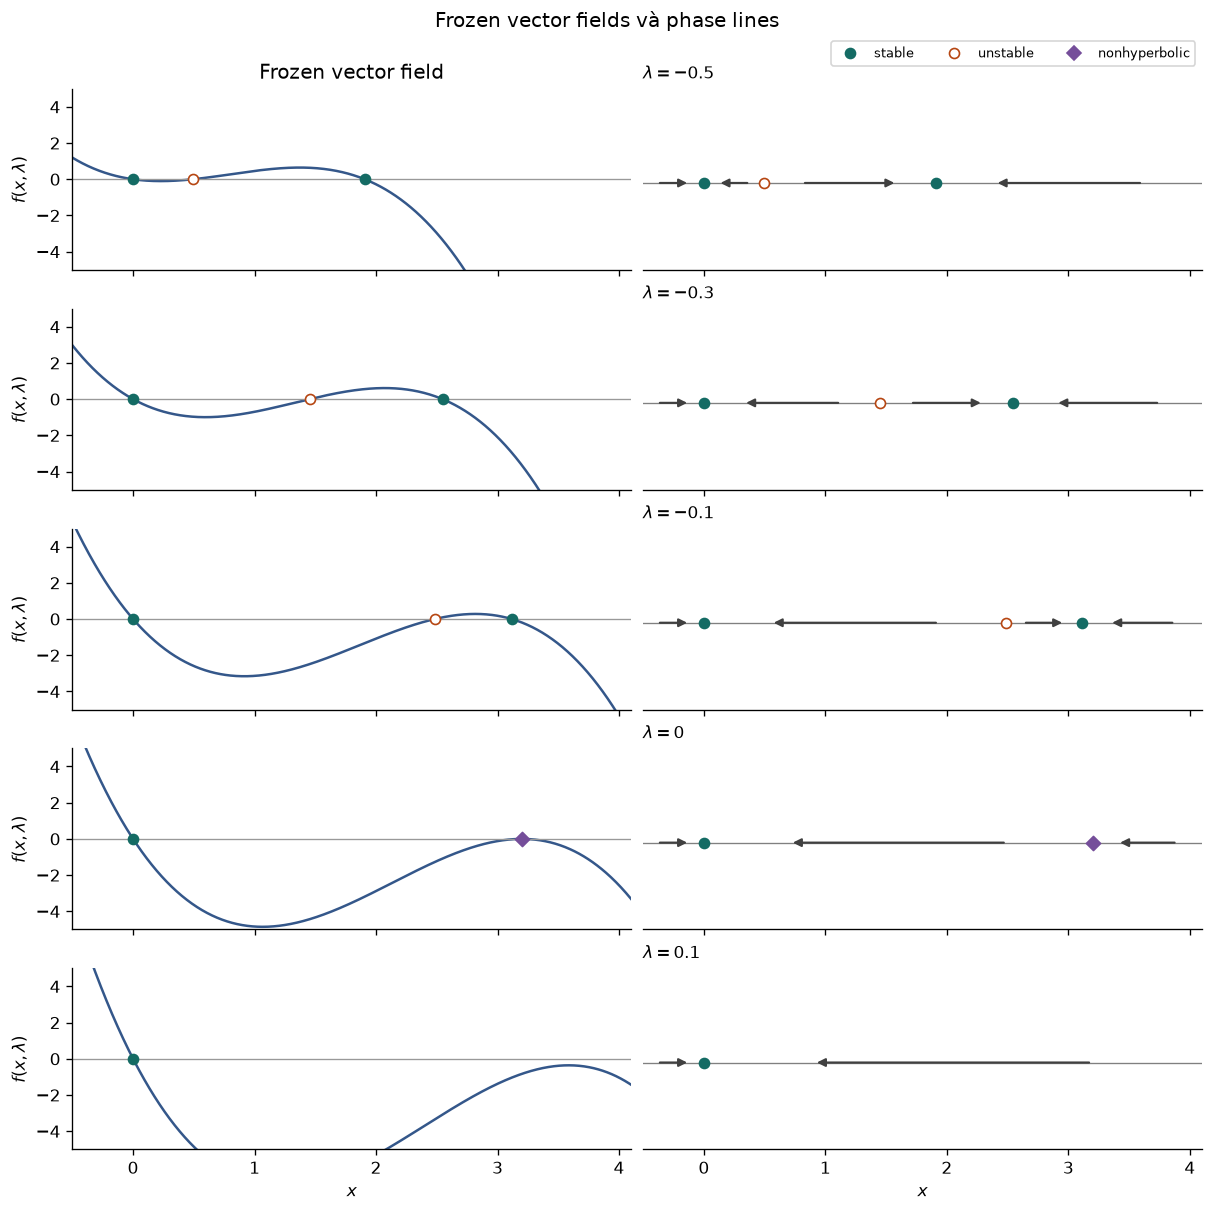

In [9]:
STABILITY_STYLE = {
    "stable": {"marker": "o", "facecolors": "#146b64", "edgecolors": "#146b64"},
    "unstable": {"marker": "o", "facecolors": "white", "edgecolors": "#b64612"},
    "nonhyperbolic": {"marker": "D", "facecolors": "#754e9a", "edgecolors": "#754e9a"},
}

stability_legend = [
    Line2D([], [], marker=style["marker"], linestyle="none", label=label,
           markerfacecolor=style["facecolors"], markeredgecolor=style["edgecolors"])
    for label, style in STABILITY_STYLE.items()
]


def mark_equilibria(ax, points):
    for _, x, _, stability in points:
        ax.scatter(x, 0, s=36, zorder=5, **STABILITY_STYLE[stability])


def plot_phase_line(ax, points, x_limits, lam, A, s):
    ax.axhline(0, color="0.5", linewidth=0.8)
    bounds = [x_limits[0]] + [x for _, x, _, _ in points
                             if x_limits[0] < x < x_limits[1]] + [x_limits[1]]
    for left, right in zip(bounds, bounds[1:]):
        midpoint = (left + right) / 2.0
        direction = np.sign(vector_field(midpoint, lam, A, s))
        half_arrow = (right - left) * 0.28
        ax.annotate("", xy=(midpoint + direction * half_arrow, 0),
                    xytext=(midpoint - direction * half_arrow, 0),
                    arrowprops={"arrowstyle": "-|>", "color": "0.25", "lw": 1.3})
    mark_equilibria(ax, points)
    ax.set(xlim=x_limits, ylim=(-0.35, 0.38), yticks=[])
    ax.spines["left"].set_visible(False)


frozen_levels = (-0.5, -0.3, -0.1, 0.0, 0.1)
x_limits = (-0.5, 4.1)
x_plot = np.linspace(*x_limits, 1001)
fig, axes = plt.subplots(5, 2, figsize=(10, 10), sharex=True, layout="constrained")
for row, lam in enumerate(frozen_levels):
    ax_field, ax_phase = axes[row]
    points = frozen_equilibria(lam, A_paper, s_paper)
    ax_field.plot(x_plot, vector_field(x_plot, lam, A_paper, s_paper), color="#34578a")
    ax_field.axhline(0, color="0.6", linewidth=0.8)
    mark_equilibria(ax_field, points)
    ax_field.set_ylabel(r"$f(x,\lambda)$")
    # Giữ vùng quanh f=0 dễ đọc khi |f| lớn ở hai đầu.
    ax_field.set_ylim(-5, 5)
    plot_phase_line(ax_phase, points, x_limits, lam, A_paper, s_paper)
    ax_phase.set_title(rf"$\lambda={lam:g}$", loc="left", fontsize=10)
axes[0, 0].set_title("Frozen vector field")
axes[0, 1].legend(handles=stability_legend, loc="upper right", ncol=3,
                  bbox_to_anchor=(1, 1.3))
axes[-1, 0].set_xlabel("$x$")
axes[-1, 1].set_xlabel("$x$")
fig.suptitle("Frozen vector fields và phase lines")
plt.show()

*Hình 2.1.* Mỗi hàng dùng cùng $\lambda$ cho vector field và phase line. Cột trái phóng đại vùng $|f|\le5$. Tại các mức âm đã chọn, $x_-^*$ là nghiệm đẩy giữa hai attractors. Ở $\lambda=0$, tiếp xúc tại $x=A$ cho hai mũi tên cùng hướng sang trái quanh fold. Ở $\lambda=0.1$, mọi hướng trên phase line đều dẫn về $x=0$.

### Trajectories với forcing cố định

**Thí nghiệm bổ sung.** Tích phân ODE tự trị để kiểm tra dự đoán của phase line. Chọn các initial conditions ở hai phía threshold tại mỗi mức âm, hai phía của nghiệm kép tại fold và ở cả hai phía của $0$ khi $\lambda>0$. Bổ sung nghiệm bắt đầu ngay tại equilibrium để kiểm tra tính dừng.

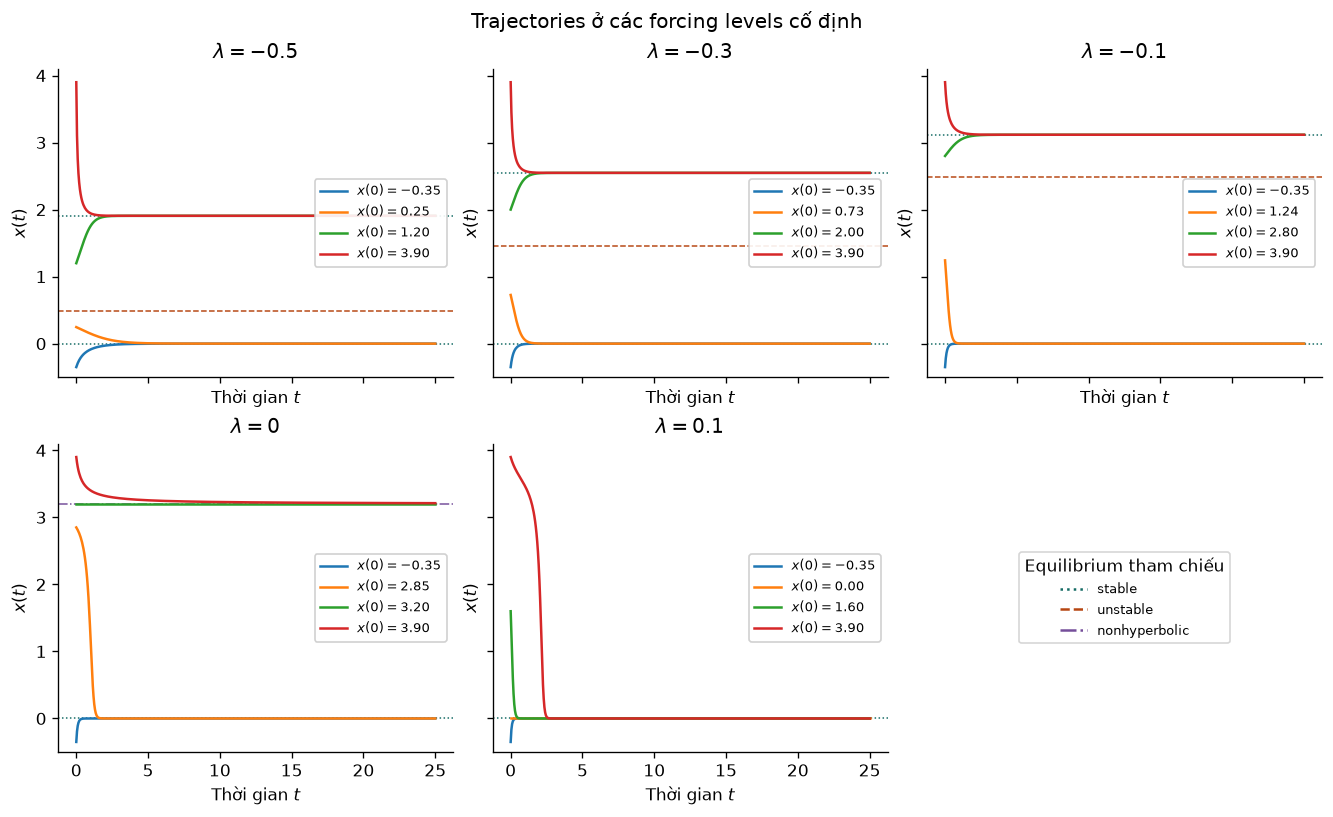

In [10]:
def integrate_frozen(x_initial, lam, A, s, t_eval):
    """Tích phân tại một forcing level cố định."""
    solution = solve_ivp(
        lambda t, x: vector_field(x, lam, A, s),
        (t_eval[0], t_eval[-1]), [x_initial], t_eval=t_eval,
        rtol=1e-9, atol=1e-11,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution.y[0]


FROZEN_REFERENCE_STYLE = {
    "stable": ":",
    "unstable": "--",
    "nonhyperbolic": "-.",
}
t_frozen = np.linspace(0, 25, 501)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.7), sharex=True, sharey=True,
                         layout="constrained")
for ax, lam in zip(axes.flat, frozen_levels):
    branches = equilibrium_branches(lam, A_paper, s_paper)
    if lam < 0:
        threshold = branches["-"]
        initial_values = [-0.35, threshold / 2, (threshold + branches["+"]) / 2, 3.9]
    elif lam == 0:
        initial_values = [-0.35, A_paper - 0.35, A_paper, 3.9]
    else:
        initial_values = [-0.35, 0.0, 1.6, 3.9]

    for _, x, _, stability in frozen_equilibria(lam, A_paper, s_paper):
        ax.axhline(x, linestyle=FROZEN_REFERENCE_STYLE[stability],
                   color=STABILITY_STYLE[stability]["edgecolors"], linewidth=0.9)
    for x_initial in initial_values:
        trajectory = integrate_frozen(x_initial, lam, A_paper, s_paper, t_frozen)
        ax.plot(t_frozen, trajectory, label=rf"$x(0)={x_initial:.2f}$")
        if lam < 0:
            expected = branches["+"] if x_initial > threshold else 0.0
            np.testing.assert_allclose(trajectory[-1], expected, atol=1e-5)
        if lam > 0:
            np.testing.assert_allclose(trajectory[-1], 0.0, atol=1e-5)
        if lam == 0 and x_initial == A_paper:
            np.testing.assert_allclose(trajectory, A_paper, atol=1e-12)
    ax.set(title=rf"$\lambda={lam:g}$", xlabel="Thời gian $t$", ylabel="$x(t)$")
    ax.legend(loc="center right", framealpha=0.9)

axes[1, 2].axis("off")
reference_legend = [
    Line2D([], [], color=STABILITY_STYLE[status]["edgecolors"],
           linestyle=linestyle, label=status)
    for status, linestyle in FROZEN_REFERENCE_STYLE.items()
]
axes[1, 2].legend(handles=reference_legend, loc="center", title="Equilibrium tham chiếu")
axes[0, 0].set_ylim(-0.5, 4.1)
fig.suptitle("Trajectories ở các forcing levels cố định")
plt.show()

*Hình 2.2.* Với $\lambda<0$ trong thí nghiệm, trajectories kết thúc gần $0$ hoặc $x_+^*$ theo basin chứa initial condition. Tại fold, $x(0)>A$ tiến chậm về $A$, còn $0<x(0)<A$ đi về $0$. Trajectory ở đúng $A$ đứng yên. Sự tiến chậm từ bên phải phù hợp với $J=0$ và drift bậc hai gần fold.

### 2.7. Bifurcation diagram

**Thí nghiệm bổ sung.** Theo dõi equilibrium branches khi thay forcing để xem base state mất ở đâu. Một nhánh có thể đổi stability trong miền khảo sát, nên ta chia trục $\lambda$ tại $\lambda=0$ và tại các nghiệm âm của
$$
(A+s\lambda)^2+\lambda=0.
$$
Các nghiệm âm là vị trí một nhánh quadratic gặp $x_0^*$. Với các nghiệm đơn theo $\lambda$ trong sweep này, hai nhánh cắt nhau và trao đổi stability (**transcritical bifurcation**). Trên mỗi khoảng giữa các điểm đó, dấu $J$ tại trung điểm quyết định kiểu nét của cả đoạn. Cách chia khoảng này vẽ được các đoạn tới đúng các điểm bifurcation.

In [11]:
BRANCH_COLORS = {"0": "#697581", "+": "#146b64", "-": "#b64612"}


def zero_branch_crossings(A, s):
    """Các lambda âm tại đó một nghiệm quadratic gặp x=0."""
    roots = np.roots([s**2, 2 * A * s + 1, A**2])
    return np.unique(sorted(root.real for root in roots
                            if abs(root.imag) < 1e-12 and root.real < 0))


def plot_bifurcation(ax, A, s, lambda_limits):
    lam_min, lam_max = lambda_limits
    crossings = [lam for lam in zero_branch_crossings(A, s) if lam_min < lam < lam_max]
    splits = sorted([lam_min, lam_max, *crossings]
                    + ([0.0] if lam_min < 0 < lam_max else []))

    for left, right in zip(splits, splits[1:]):
        midpoint = (left + right) / 2
        lam_grid = np.linspace(left, right, 301)
        mid_branches = equilibrium_branches(midpoint, A, s)
        for branch, values in equilibrium_branches(lam_grid, A, s).items():
            status = classify_stability(mid_branches[branch], midpoint, A, s, tol=0)
            if status in ("stable", "unstable"):
                ax.plot(lam_grid, values, color=BRANCH_COLORS[branch], linewidth=1.8,
                        linestyle="-" if status == "stable" else "--")

    if lam_min <= 0 <= lam_max:
        ax.scatter(0, A, marker="D", color="#754e9a", s=36, zorder=5)
    if crossings:
        ax.scatter(crossings, np.zeros(len(crossings)), marker="X", color="#3e3348",
                   s=45, zorder=5)
    ax.set(xlim=lambda_limits, xlabel=r"Forcing level $\lambda$", ylabel="$x^*$")
    ax.grid(alpha=0.18)


bifurcation_legend = [
    Line2D([], [], color=BRANCH_COLORS["0"], label=r"$x_0^*$ · Alternative trong miền paper"),
    Line2D([], [], color=BRANCH_COLORS["+"], label=r"$x_+^*$ · Base trong miền paper"),
    Line2D([], [], color=BRANCH_COLORS["-"], label=r"$x_-^*$"),
    Line2D([], [], color="0.25", linestyle="-", label="Stable"),
    Line2D([], [], color="0.25", linestyle="--", label="Unstable"),
    Line2D([], [], color="#754e9a", marker="D", linestyle="none", label="Fold"),
    Line2D([], [], color="#3e3348", marker="X", linestyle="none", label="Transcritical"),
]

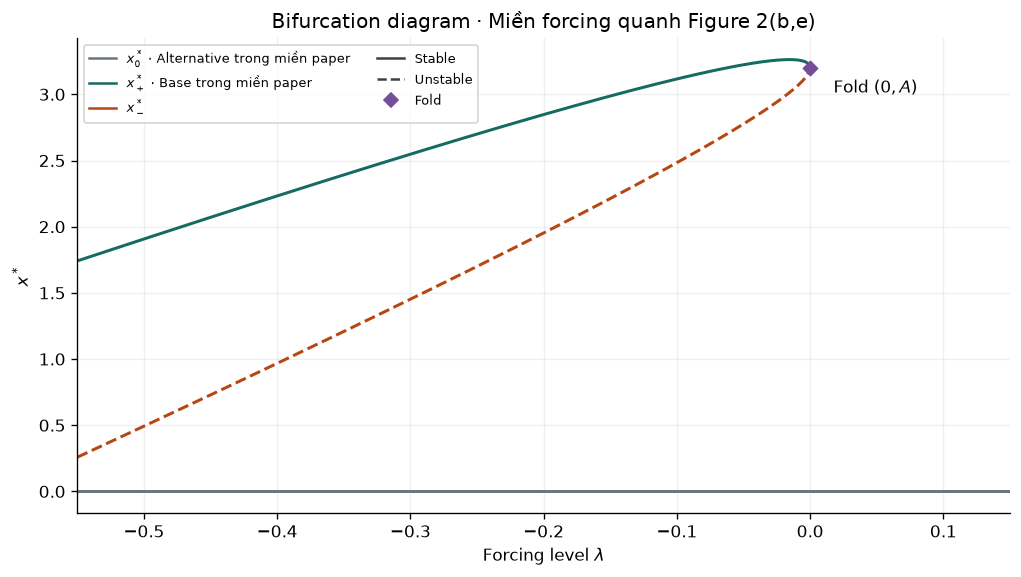

In [12]:
fig, ax = plt.subplots(figsize=(8.4, 4.7), layout="constrained")
plot_bifurcation(ax, A_paper, s_paper, (-0.55, 0.15))
ax.set_title("Bifurcation diagram · Miền forcing quanh Figure 2(b,e)")
ax.annotate(r"Fold $(0,A)$", (0, A_paper), xytext=(14, -15), textcoords="offset points")
ax.legend(handles=bifurcation_legend[:-1], loc="upper left", ncol=2)
plt.show()

*Hình 2.3.* Trong miền vẽ, base state $x_+^*$ và threshold $x_-^*$ gặp nhau tại $(0,3.2)$. Vượt $\lambda=0$, cả hai nhánh biến mất và $x=0$ là attractor duy nhất. Khi tiến tới fold từ trái, $J_+\to0^-$ và tốc độ phục hồi tuyến tính về base state giảm.

### 2.8. Ảnh hưởng của tilt parameter

**Thí nghiệm bổ sung.** So sánh $s\in\{-4,-2,0,2,4\}$ với cùng $A$, cùng trục forcing và state. Dải mở rộng $[-1.35,0.15]$ cho thấy những giao điểm có thể nằm ngoài dải forcing của Figure 2(b,e). Ta kiểm tra dấu $J$ hai phía của mỗi giao điểm âm trong dải.

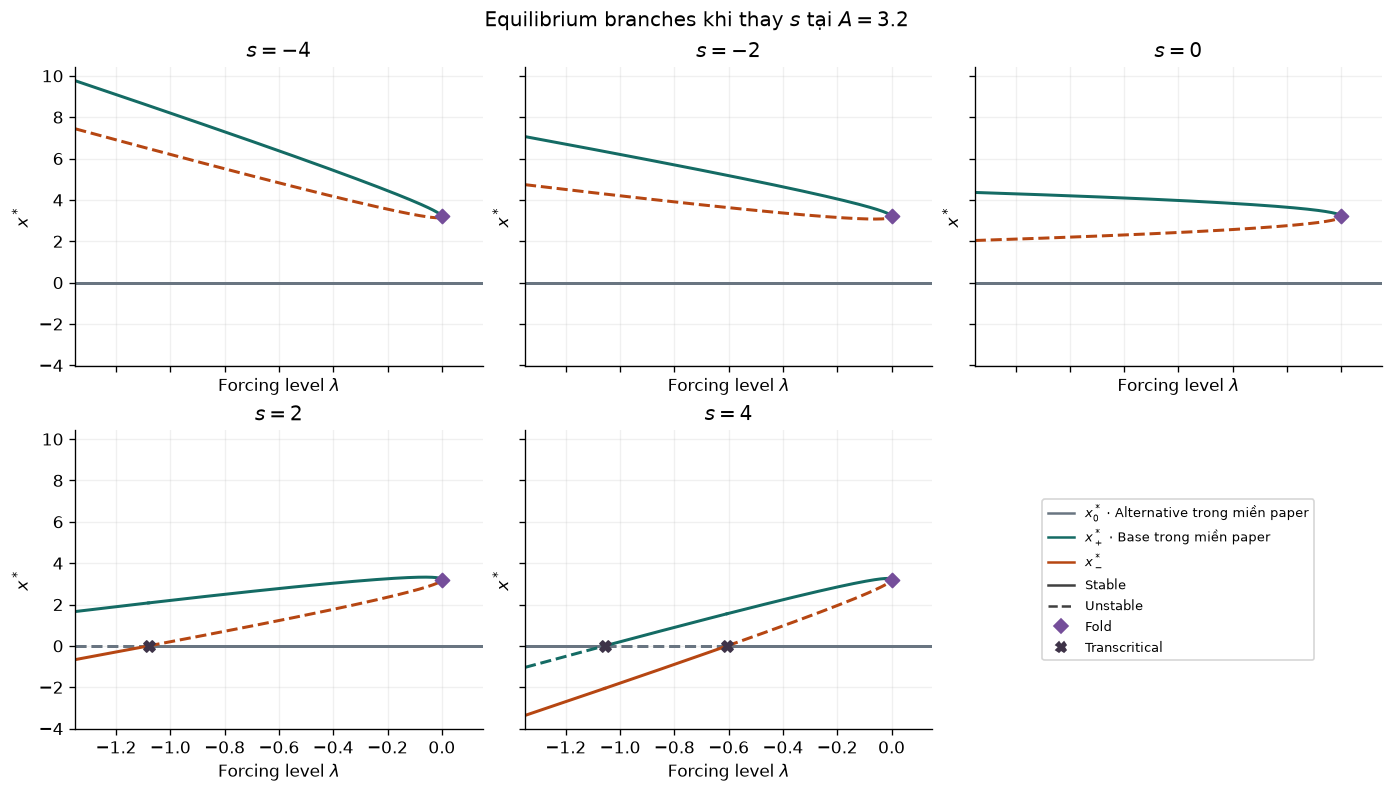

| $s$ | Nhánh gặp $x_0^*$ | $\lambda$ |
|---:|:---:|---:|
| 2 | $x_-^*$ | -1.080310 |
| 4 | $x_+^*$ | -1.057030 |
| 4 | $x_-^*$ | -0.605470 |

In [13]:
tilt_values = (-4, -2, 0, 2, 4)
tilt_lambda_limits = (-1.35, 0.15)
fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.5), sharex=True, sharey=True,
                         layout="constrained")
crossing_rows = ["| $s$ | Nhánh gặp $x_0^*$ | " + r"$\lambda$ |",
                 "|---:|:---:|---:|"]

for ax, tilt in zip(axes.flat, tilt_values):
    plot_bifurcation(ax, A_paper, tilt, tilt_lambda_limits)
    ax.set_title(f"$s={tilt:g}$")
    for lam in zero_branch_crossings(A_paper, tilt):
        if not tilt_lambda_limits[0] < lam < tilt_lambda_limits[1]:
            continue
        branches = equilibrium_branches(lam, A_paper, tilt)
        branch = min(("+", "-"), key=lambda label: abs(branches[label]))
        assert abs(branches[branch]) < 1e-10
        side_lams = np.array([lam - 1e-4, lam + 1e-4])
        crossing_states = equilibrium_branches(side_lams, A_paper, tilt)[branch]
        j_zero = jacobian(0.0, side_lams, A_paper, tilt)
        j_branch = jacobian(crossing_states, side_lams, A_paper, tilt)
        assert j_zero[0] * j_zero[1] < 0
        assert np.all(j_zero * j_branch < 0)
        crossing_rows.append(f"| {tilt:g} | $x_{branch}^*$ | {lam:.6f} |")

axes[1, 2].axis("off")
axes[1, 2].legend(handles=bifurcation_legend, loc="center")
fig.suptitle(r"Equilibrium branches khi thay $s$ tại $A=3.2$")
plt.show()
display(Markdown("\n".join(crossing_rows)))

*Hình 2.4.* Tilt dịch hai nhánh quadratic cùng một lượng $s\lambda$ so với $s=0$ tại mỗi $\lambda$ và giữ nguyên khoảng cách $2\sqrt{-\lambda}$ giữa chúng. Với các mức $\lambda<0$, tăng $s$ kéo các nhánh xuống, mạnh hơn ở phía xa fold. Tại một mức $\lambda$ ban đầu cố định, vị trí base state có thể giảm nhanh hơn vị trí threshold tại mức forcing cuối, tạo điều kiện cho Basin Instability.

Fold tại $\lambda=0$ và $x=A$ giữ nguyên cho cả năm giá trị $s$. Bảng liệt kê các **transcritical bifurcations** trong dải hình: $s=2$ có một giao với $x_-^*$, $s=4$ có một giao với mỗi nhánh quadratic. Tại các giao điểm, hai nhánh tồn tại ở cả hai phía và trao đổi stability. Tại fold, hai nhánh quadratic kết thúc. Một equilibrium dịch chuyển vẫn là nghiệm của frozen system ở mức forcing mới trong khi equilibrium đã mất không còn nghiệm tương ứng.

### 2.9. Kết luận

Cấu trúc tích của vector field sinh ra các equilibrium branches và xác định stability thông qua thứ tự nghiệm. Thứ tự đó xác định basins và threshold. Mất nhánh ổn định tại fold tạo cơ chế B-tipping, còn threshold dịch chuyển qua vị trí base state ban đầu khi nhánh vẫn hút là hình học dẫn tới khả năng R-tipping.

## Module 3 — Threshold Instability and Basin Instability

### 3.1–3.2. Tiêu chuẩn hình học

**Mục tiêu khoa học.** Chẩn đoán susceptibility to R-tipping từ hai frozen systems trước khi chọn một lịch sử forcing hay khảo sát rate parameter.

**Paper gốc · Section 2 và Figure 2(e).** Basin of attraction của attractor là tập initial conditions hội tụ về attractor đó trong hệ tự trị. Basin boundary phân cách các basins. Với một **regular threshold** phân chia hai kiểu đáp ứng, **Threshold Instability** xảy ra khi thay forcing làm threshold đi qua vị trí base state ban đầu. Khi threshold là basin boundary giữa hai attractors, trường hợp này là **Basin Instability** (BI).

Ký hiệu $x_s^*(\lambda)$ là stable base state. Phép kiểm tra cơ bản là
$$
x_s^*(\lambda_i)\notin\mathcal B_{\lambda_f}\!\left(x_s^*(\lambda_f)\right).
$$
Trong miền $0=x_0^*<x_u^*=x_-^*<x_s^*=x_+^*$ của mô hình, basin của base state ở $\lambda_f$ là $(x_u^*(\lambda_f),\infty)$, còn basin của $0$ là $(-\infty,x_u^*(\lambda_f))$. Notebook gọi
$$
x_s^*(\lambda_i)<x_u^*(\lambda_f)
$$
là **BI nghiêm ngặt**, tức vị trí ban đầu nằm trong basin của alternative state ở mức forcing cuối. Tại dấu bằng, vị trí ban đầu nằm trên threshold, cũng nằm ngoài basin mở của base state, và frozen trajectory khởi tạo chính xác tại đó đứng yên. Ta dùng dấu bằng để xác định ranh giới BI.

Ta chỉ lấy vị trí base state từ hệ ở $\lambda_i$ rồi đặt nó trên phase line của hệ ở $\lambda_f$. Với forcing biến thiên liên tục, vị trí thực của hệ lúc đến $\lambda_f$ còn phụ thuộc profile và $r$. BI báo hiệu khả năng R-tipping, còn R-tipping đối với một forcing cụ thể cần được xác định từ dynamics theo thời gian.

### 3.3. Điều kiện đại số

**Mục tiêu khoa học.** Viết phép so sánh basin dưới dạng bất đẳng thức trực tiếp theo tilt và forcing shift.

**Suy dẫn bổ sung từ Eq. (A3).** Thay $x_s^*(\lambda_i)=x_+^*(\lambda_i)$ và $x_u^*(\lambda_f)=x_-^*(\lambda_f)$ vào tiêu chuẩn nghiêm ngặt:
$$
A+s\lambda_i+\sqrt{-\lambda_i}
<
A+s\lambda_f-\sqrt{-\lambda_f}.
$$
Triệt tiêu $A$ và gom các số hạng cho
$$
s(\lambda_f-\lambda_i)>\sqrt{-\lambda_i}+\sqrt{-\lambda_f}.
$$
Tích $s(\lambda_f-\lambda_i)$ đo dịch chuyển của tâm hai branches. Vế phải là tổng offset của base state ban đầu và threshold cuối quanh hai tâm tương ứng. $A$ triệt tiêu khỏi hiệu vị trí nhưng vẫn quyết định miền hợp lệ: ở cả hai forcing levels cần $\lambda<0$ và $A+s\lambda>\sqrt{-\lambda}$ để có đúng thứ tự và stability của ba equilibria. Với forcing tăng và dải giữa hai mức này, $A+s\lambda-\sqrt{-\lambda}>0$ cũng cần được kiểm tra nếu muốn khẳng định hình học đó trên cả đoạn. Trong ví dụ chính $s=4$, hàm này tăng theo $\lambda<0$ nên kiểm tra tại $\lambda_i$ đủ cho cả đoạn.

### 3.4. Kiểm chứng với tham số Figure 2(b,e)

**Thí nghiệm bổ sung.** Dùng $A=3.2$, $s=4$, $\lambda_i=-0.5$ và $\Delta\lambda=0.4$, nên $\lambda_f=-0.1$. Appendix A2 dùng $T=500$ và $r=1,3$ cho time-dependent Figure 2(b,e). Phép kiểm tra hình học ở đây chỉ cần hai forcing levels. Bảng liệt kê từng nghiệm, Jacobian, stability và basin của từng attractor. Nghiệm đẩy phân chia hai basins.

In [14]:
def has_positive_bistability(lam, A, s):
    """Miền 0 < x_-^* < x_+^* với ba equilibria hyperbolic."""
    lam = np.asarray(lam, dtype=float)
    lower_branch = equilibrium_branches(lam, A, s)["-"]
    return (lam < 0.0) & (lower_branch > 0.0)


def basin_instability_gap(lam_initial, lam_final, A, s):
    """Tính x_-^*(lambda_f) - x_+^*(lambda_i); NaN ngoài miền áp dụng."""
    initial_base = equilibrium_branches(lam_initial, A, s)["+"]
    final_threshold = equilibrium_branches(lam_final, A, s)["-"]
    valid = (has_positive_bistability(lam_initial, A, s)
             & has_positive_bistability(lam_final, A, s))
    return np.where(valid, final_threshold - initial_base, np.nan)[()]


initial_branches = equilibrium_branches(lambda_i, A_paper, s_paper)
final_branches = equilibrium_branches(lambda_f, A_paper, s_paper)
initial_base = initial_branches["+"]
final_threshold = final_branches["-"]
bi_gap = basin_instability_gap(lambda_i, lambda_f, A_paper, s_paper)

rows = [
    r"| Frozen system | $\lambda$ | Branch | $x^*$ | $J$ | Stability | Basin |",
    "|:---|---:|:---:|---:|---:|:---|:---|",
]
for name, lam in (("Ban đầu", lambda_i), ("Cuối", lambda_f)):
    assert has_positive_bistability(lam, A_paper, s_paper)
    points = frozen_equilibria(lam, A_paper, s_paper)
    assert [point[3] for point in points] == ["stable", "unstable", "stable"]
    threshold = equilibrium_branches(lam, A_paper, s_paper)["-"]
    basins = {"0": rf"$(-\infty,{threshold:.6f})$", "+": rf"$({threshold:.6f},\infty)$"}
    for branch, x, J, stability in points:
        basin = basins.get(branch, "Basin boundary")
        rows.append(f"| {name} | {lam:g} | $x_{branch}^*$ | {x:.6f} | {J:.6f} "
                    f"| {stability} | {basin} |")

display(Markdown("\n".join(rows)))
algebraic_gap = (s_paper * (lambda_f - lambda_i) - np.sqrt(-lambda_i)
                 - np.sqrt(-lambda_f))
np.testing.assert_allclose(bi_gap, algebraic_gap, atol=1e-14)
assert bi_gap > 0.0
display(Markdown(rf"BI gap $=x_-^*(\lambda_f)-x_+^*(\lambda_i)={bi_gap:+.9f}>0$. "
                 "Initial base state thuộc basin cuối của $x=0$."))

| Frozen system | $\lambda$ | Branch | $x^*$ | $J$ | Stability | Basin |
|:---|---:|:---:|---:|---:|:---|:---|
| Ban đầu | -0.5 | $x_0^*$ | 0.000000 | -0.940000 | stable | $(-\infty,0.492893)$ |
| Ban đầu | -0.5 | $x_-^*$ | 0.492893 | 0.697056 | unstable | Basin boundary |
| Ban đầu | -0.5 | $x_+^*$ | 1.907107 | -2.697056 | stable | $(0.492893,\infty)$ |
| Cuối | -0.1 | $x_0^*$ | 0.000000 | -7.740000 | stable | $(-\infty,2.483772)$ |
| Cuối | -0.1 | $x_-^*$ | 2.483772 | 1.570875 | unstable | Basin boundary |
| Cuối | -0.1 | $x_+^*$ | 3.116228 | -1.970875 | stable | $(2.483772,\infty)$ |

BI gap $=x_-^*(\lambda_f)-x_+^*(\lambda_i)=+0.576665453>0$. Initial base state thuộc basin cuối của $x=0$.

Threshold dịch từ khoảng $0.493$ lên $2.484$. Vị trí ban đầu $x_s^*(\lambda_i)\approx 1.907$ nằm bên phải threshold ban đầu và bên trái threshold cuối. Khi đóng băng forcing tại $\lambda_f$, vị trí đó thuộc basin của $x=0$, dù base state cuối vẫn ổn định.

### 3.5. Figures A–B — Hai frozen phase lines

**Thí nghiệm bổ sung.** Đặt hai phase lines trên cùng state-space range để nhìn trực tiếp việc threshold đi qua vị trí ban đầu. Màu nền biểu diễn basins, còn mũi tên lấy từ dấu của vector field.

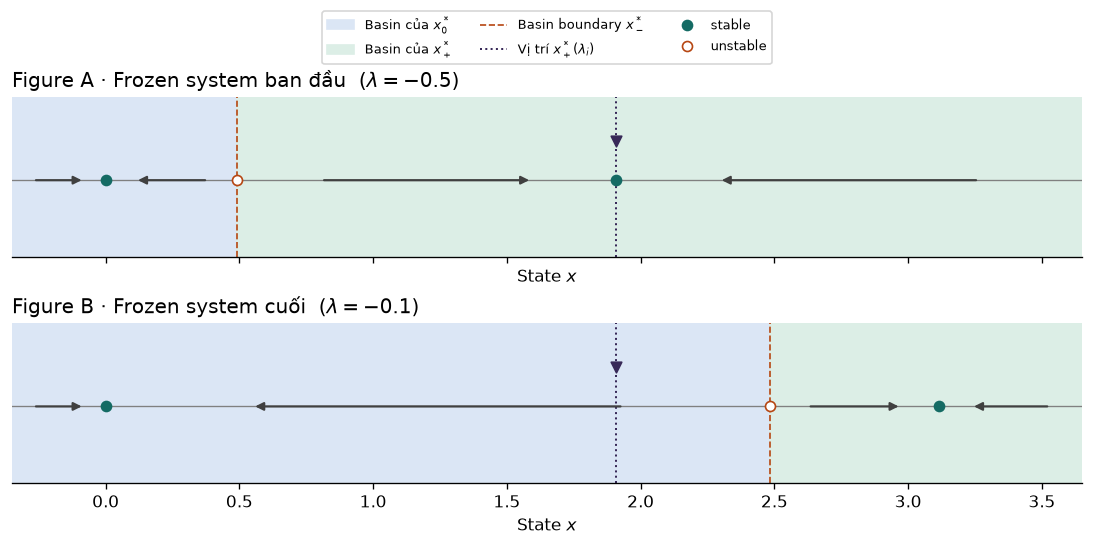

In [15]:
def plot_positive_basins(ax, lam, x_limits, A, s):
    if not has_positive_bistability(lam, A, s):
        raise ValueError("Phase line này cần 0 < x_-^* < x_+^*.")
    threshold = equilibrium_branches(lam, A, s)["-"]
    ax.axvspan(x_limits[0], threshold, color="#dbe6f5", label=r"Basin của $x_0^*$")
    ax.axvspan(threshold, x_limits[1], color="#dceee6", label=r"Basin của $x_+^*$")
    ax.axvline(threshold, color="#b64612", linestyle="--", linewidth=1,
               label=r"Basin boundary $x_-^*$")
    plot_phase_line(ax, frozen_equilibria(lam, A, s), x_limits, lam, A, s)


fig, axes = plt.subplots(2, 1, figsize=(9, 4.4), sharex=True, layout="constrained")
bi_x_limits = (-0.35, 3.65)

for ax, lam, title in zip(axes, (lambda_i, lambda_f),
                          ("Figure A · Frozen system ban đầu", "Figure B · Frozen system cuối")):
    plot_positive_basins(ax, lam, bi_x_limits, A_paper, s_paper)
    ax.axvline(initial_base, color="#382958", linestyle=":", linewidth=1.2,
               label=r"Vị trí $x_+^*(\lambda_i)$")
    ax.scatter(initial_base, 0.18, marker="v", color="#382958", s=40, zorder=6)
    ax.set_title(rf"{title}  $(\lambda={lam:g})$", loc="left")
    ax.set_xlabel("State $x$")

handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles + stability_legend[:2],
               labels + [handle.get_label() for handle in stability_legend[:2]],
               ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.58))
plt.show()

*Figures A–B.* Mũi tên tím hướng xuống đánh dấu cùng tọa độ $x_s^*(\lambda_i)$ ở cả hai hình. Tọa độ đó đổi từ vùng xanh lá (basin của base state) sang vùng xanh lam (basin của alternative equilibrium) khi threshold dịch sang phải.

### 3.6. Basin Instability boundary và fold

**Mục tiêu khoa học.** Tìm forcing shift nhỏ nhất tại ranh giới BI và so sánh với forcing shift cần để đến fold.

**Suy dẫn bổ sung.** Giữ $A=3.2$, $s=4$ và $\lambda_i=-0.5$. Xét tăng forcing từ $\lambda_i$ về $0$. Đặt $q_i=\sqrt{-\lambda_i}$ và $q=\sqrt{-\lambda}$, với $0<q\le q_i$. Phương trình $x_u^*(\lambda)=x_s^*(\lambda_i)$ tương đương
$$
s(q_i^2-q^2)=q_i+q
\quad\Longleftrightarrow\quad
s(q_i-q)=1,
$$
vì $q_i+q>0$. Với $s>0$ và $q_i>1/s$, nghiệm nằm trong $(\lambda_i,0)$:
$$
\lambda_{\mathrm{BI}}=-\left(q_i-\frac1s\right)^2,\qquad
\Delta\lambda_{\mathrm{BI}}=\lambda_{\mathrm{BI}}-\lambda_i.
$$
Trên đoạn này, $dx_-^*/d\lambda=s+1/(2\sqrt{-\lambda})>0$. Ta kiểm chứng nghiệm duy nhất bằng Brent root-finding, với residual từ chính các equilibrium branches. Đầu phải của bracket là điểm fold và chỉ dùng như giới hạn liên tục của nhánh $x_-^*$.

In [16]:
lambda_fold = 0.0
q_i = np.sqrt(-lambda_i)
assert s_paper > 0 and q_i > 1.0 / s_paper
lambda_bi_analytic = -(q_i - 1.0 / s_paper)**2


def boundary_residual(lam):
    return equilibrium_branches(lam, A_paper, s_paper)["-"] - initial_base


lambda_bi = brentq(boundary_residual, lambda_i, lambda_fold, xtol=1e-14)
delta_lambda_bi = lambda_bi - lambda_i
np.testing.assert_allclose(lambda_bi, lambda_bi_analytic, atol=1e-13)
assert abs(boundary_residual(lambda_bi)) < 1e-12
assert lambda_i < lambda_bi < lambda_f < lambda_fold
assert basin_instability_gap(lambda_i, (lambda_i + lambda_bi) / 2, A_paper, s_paper) < 0
assert basin_instability_gap(lambda_i, (lambda_bi + lambda_fold) / 2, A_paper, s_paper) > 0

display(Markdown(
    "| Boundary | Forcing level | Shift từ mức ban đầu |\n"
    "|:---|---:|---:|\n"
    f"| Basin Instability (giải tích) | {lambda_bi_analytic:.9f} | "
    f"{lambda_bi_analytic - lambda_i:.9f} |\n"
    f"| Basin Instability (Brent) | {lambda_bi:.9f} | {delta_lambda_bi:.9f} |\n"
    f"| Fold | {lambda_fold:.9f} | {lambda_fold - lambda_i:.9f} |"
))
display(Markdown(f"Residual tại nghiệm Brent bằng {boundary_residual(lambda_bi):+.2e}."))

| Boundary | Forcing level | Shift từ mức ban đầu |
|:---|---:|---:|
| Basin Instability (giải tích) | -0.208946609 | 0.291053391 |
| Basin Instability (Brent) | -0.208946609 | 0.291053391 |
| Fold | 0.000000000 | 0.500000000 |

Residual tại nghiệm Brent bằng +0.00e+00.

Mức cuối $\lambda_f=-0.1$ nằm giữa ranh giới BI và fold. Trong khoảng mở $(\lambda_{\mathrm{BI}},0)$, base state vẫn hút trong từng frozen system và vị trí base state ban đầu thuộc basin của $0$. Đây là miền để khảo sát R-tipping mà forcing chưa đi qua fold. Tại $\lambda_{\mathrm{BI}}$ có tiếp xúc threshold, còn tại $0$ hai nhánh quadratic hợp nhất và điều kiện bistability của phép kiểm tra chấm dứt.

### Figure C — Basin Instability trên bifurcation diagram

**Thí nghiệm bổ sung.** Đặt mức ban đầu, mức cuối và đường ngang qua initial base state lên cùng bifurcation diagram. Giao với nhánh unstable kiểm tra trực quan vị trí của ranh giới BI.

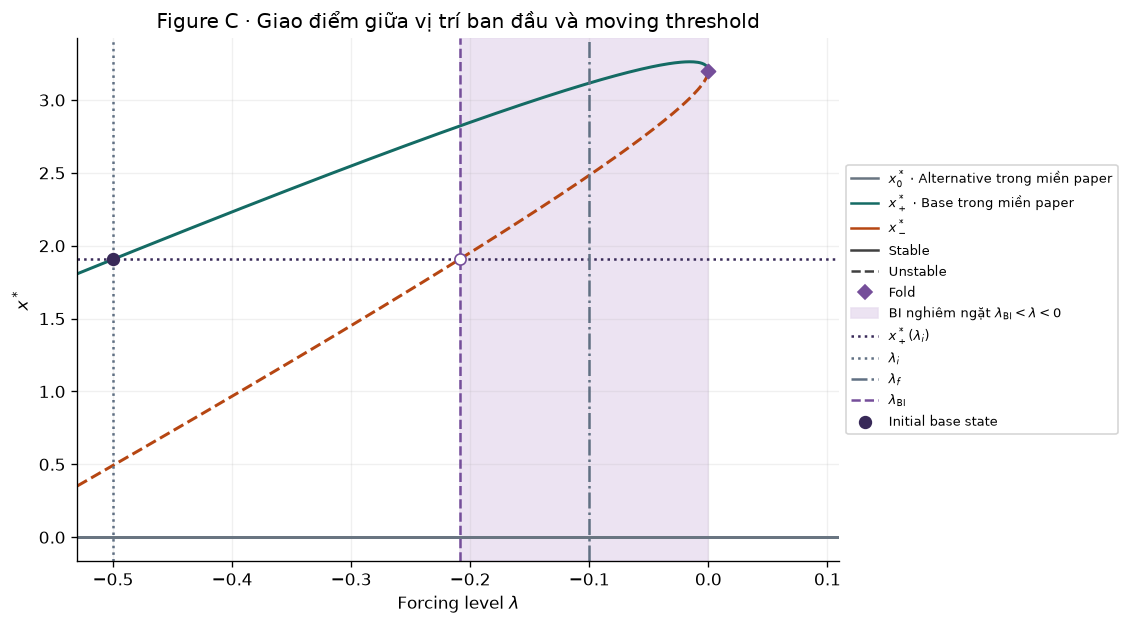

In [17]:
fig, ax = plt.subplots(figsize=(9.3, 5.1), layout="constrained")
ax.axvspan(lambda_bi, lambda_fold, color="#e8ddef", alpha=0.8,
           label=r"BI nghiêm ngặt $\lambda_{\mathrm{BI}} < \lambda < 0$")
plot_bifurcation(ax, A_paper, s_paper, (-0.53, 0.11))
ax.axhline(initial_base, color="#382958", linestyle=":", label=r"$x_+^*(\lambda_i)$")
ax.axvline(lambda_i, color="#607083", linestyle=":", label=r"$\lambda_i$")
ax.axvline(lambda_f, color="#607083", linestyle="-.", label=r"$\lambda_f$")
ax.axvline(lambda_bi, color="#754e9a", linestyle="--", label=r"$\lambda_{\mathrm{BI}}$")
ax.scatter(lambda_i, initial_base, color="#382958", zorder=6, s=49,
           label="Initial base state")
ax.scatter(lambda_bi, initial_base, facecolors="white", edgecolors="#754e9a",
           zorder=6, s=45)
ax.set_title("Figure C · Giao điểm giữa vị trí ban đầu và moving threshold")
handles, labels = ax.get_legend_handles_labels()
ax.legend(bifurcation_legend[:-1] + handles,
          [handle.get_label() for handle in bifurcation_legend[:-1]] + labels,
          loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

*Figure C.* Vòng tròn rỗng là giao của đường ngang $x=x_s^*(\lambda_i)$ với $x_-^*(\lambda)$. Phần tô tím thể hiện các forcing levels còn bistability mà threshold đã vượt vị trí ban đầu. Điểm fold ở cạnh phải của vùng tô.

### 3.7. Critical tilt với forcing levels cố định

**Mục tiêu khoa học.** Xác định tilt nhỏ nhất làm threshold cuối vượt vị trí ban đầu, rồi kiểm tra miền tilt nơi hai equilibrium branches vẫn có vai trò giả định.

**Suy dẫn bổ sung.** Với $\Delta\lambda=\lambda_f-\lambda_i>0$,
$$
s_{\mathrm{crit}}=
\frac{\sqrt{-\lambda_i}+\sqrt{-\lambda_f}}{\lambda_f-\lambda_i}.
$$
Điều kiện $A+s\lambda>\sqrt{-\lambda}$ tại mỗi endpoint $\lambda<0$ tương đương $s<(A-\sqrt{-\lambda})/(-\lambda)$. Ta lấy cận nhỏ hơn ở hai đầu để xác định miền áp dụng của phép thử endpoint. Ở dấu bằng với cận trên, một nghiệm gặp $x=0$ và mất tính hyperbolic. Dải sweep minh họa đi qua cả $s_{\mathrm{crit}}$ và cận trên. Với $s\ge0$, $x_-^*$ tăng trên toàn đoạn nên cận ở $\lambda_i$ chi phối. Với $s<0$, $s\lambda>0$ và $A>\sqrt{-\lambda}$ trên toàn đoạn của ví dụ, nên miền bistability cũng được duy trì giữa hai mức.

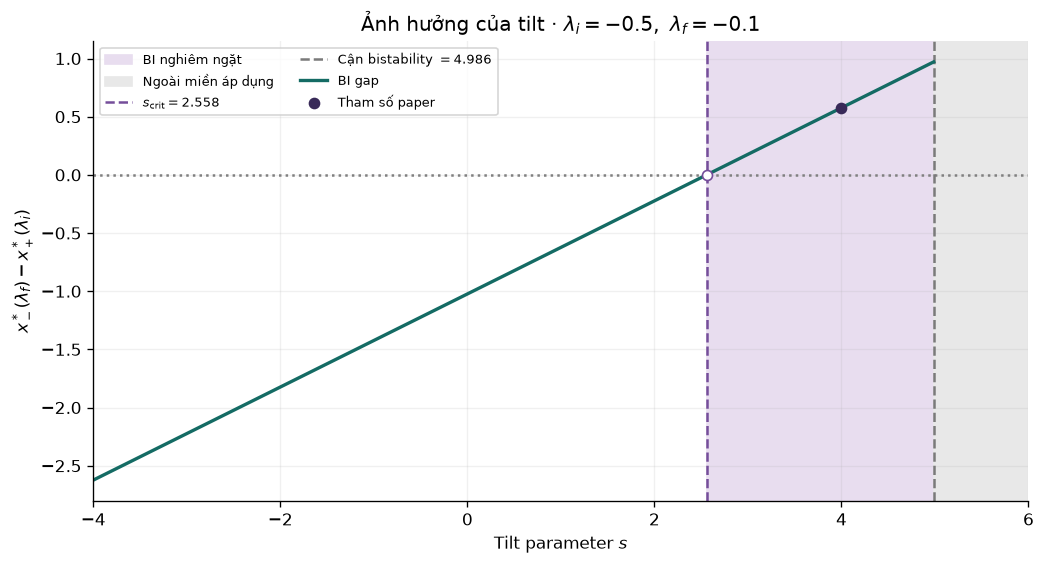

Critical tilt $s_{\mathrm{crit}}=2.558336368$. Cận trên của miền áp dụng bằng 4.985786438.

In [18]:
delta_lambda = lambda_f - lambda_i
assert delta_lambda > 0
s_crit = (np.sqrt(-lambda_i) + np.sqrt(-lambda_f)) / delta_lambda
s_upper = min((A_paper - np.sqrt(-lam)) / (-lam) for lam in (lambda_i, lambda_f))
assert s_crit < s_upper
np.testing.assert_allclose(
    basin_instability_gap(lambda_i, lambda_f, A_paper, s_crit), 0.0, atol=1e-14,
)
np.testing.assert_allclose(
    basin_instability_gap(lambda_i, lambda_f, A_paper, [-4, 0, s_paper]),
    delta_lambda * (np.array([-4, 0, s_paper]) - s_crit), atol=1e-14,
)

s_limits = (-4.0, 6.0)
s_grid = np.unique(np.r_[np.linspace(*s_limits, 601), s_crit, s_upper - 1e-9])
tilt_gaps = basin_instability_gap(lambda_i, lambda_f, A_paper, s_grid)
assert np.isnan(tilt_gaps[s_grid > s_upper]).all()

fig, ax = plt.subplots(figsize=(8.6, 4.6), layout="constrained")
ax.axvspan(s_crit, s_upper, color="#e8ddef", label="BI nghiêm ngặt")
ax.axvspan(s_upper, s_limits[1], color="0.91", label="Ngoài miền áp dụng")
ax.axhline(0.0, color="0.5", linestyle=":")
ax.axvline(s_crit, color="#754e9a", linestyle="--", label=rf"$s_{{\mathrm{{crit}}}}={s_crit:.3f}$")
ax.axvline(s_upper, color="0.48", linestyle="--", label=rf"Cận bistability $={s_upper:.3f}$")
ax.plot(s_grid, tilt_gaps, color="#146b64", linewidth=2, label="BI gap")
ax.scatter(s_paper, bi_gap, color="#382958", zorder=5, label="Tham số paper")
ax.scatter(s_crit, 0.0, facecolors="white", edgecolors="#754e9a", zorder=5)
ax.set(xlim=s_limits, xlabel="Tilt parameter $s$",
       ylabel=r"$x_-^*(\lambda_f)-x_+^*(\lambda_i)$",
       title=rf"Ảnh hưởng của tilt · $\lambda_i={lambda_i:g},\ \lambda_f={lambda_f:g}$")
ax.legend(loc="upper left", ncol=2)
ax.grid(alpha=0.18)
plt.show()

display(Markdown(rf"Critical tilt $s_{{\mathrm{{crit}}}}={s_crit:.9f}$. "
                 f"Cận trên của miền áp dụng bằng {s_upper:.9f}."))

*Hình 3.4.* Gap tăng tuyến tính với $s$, với slope $\lambda_f-\lambda_i=0.4$. Trong miền áp dụng của phép thử endpoint, BI nghiêm ngặt xảy ra khi $2.558336<s<4.985786$ (các cận hiển thị làm tròn). $s=4$ thuộc miền đó. Vùng xám bắt đầu khi giả định $x_-^*(\lambda_i)>0$ không còn đúng, nên đường gap chấm dứt ở biên này.

### 3.8. Kết luận

Tilt làm khoảng cách từ initial base state tới final threshold đổi dấu. Frozen-system analysis xác định được dấu này mà chưa cần tích phân ODE có forcing động. $s$ thay đổi hình học của equilibria và basins, còn $r$ điều khiển tốc độ dịch dọc theo forcing path. Phép kiểm tra BI xác định **susceptibility to R-tipping**. Một forcing cụ thể có dẫn tới tipping hay không còn phụ thuộc quỹ đạo theo thời gian.

### Giả định, giới hạn và các kiểm chứng

- **Giả định.** Mô hình scalar, xác định, $x\in\mathbb R$. Các kết luận BI dùng base state ban đầu đúng tại $x_+^*(\lambda_i)$ và thứ tự $0<x_-^*<x_+^*$ ở các mức forcing so sánh. Figures A–C kiểm tra shift tăng trong nhánh bistability của ví dụ chính. Dấu bằng tại threshold được xử lý như trường hợp biên.
- **Phần suy dẫn bổ sung.** Sai số tại $t=0$, đạo hàm forcing và độ dốc cực đại, branches và Jacobian, phân tích phase line và các giao điểm transcritical, bất đẳng thức BI, công thức $\lambda_{\mathrm{BI}}$ và critical tilt được suy ra từ mô hình. Cấu hình sweep và initial conditions của frozen trajectories được chọn để minh họa.
- **Kiểm chứng trong notebook.** Sai phân trung tâm đối chiếu hai đạo hàm, residual xác nhận equilibrium branches, dấu $J$ kiểm tra trao đổi stability, tích phân frozen ODE kiểm tra các attractors và Brent root-finding đối chiếu nghiệm BI giải tích. Tham số Figure 2(b,e) được đối chiếu với Appendix A2 và script gốc.
- **Chưa kiểm chứng trong giai đoạn này.** Critical rate, tracking, tipping và return tipping với forcing phụ thuộc thời gian thuộc giai đoạn tiếp theo. Các hình ở đây chỉ tái tạo thành phần forcing và hình học của conceptual model trong phạm vi Modules 1–3.

## Tóm tắt kết quả

- **External forcing.** Ramp giữ mức mới, return về mức ban đầu. Cả hai có $\max_t|\dot\lambda|=r|\Delta\lambda|/2$ trên profile đầy đủ.
- **Frozen dynamics.** Tilt dịch các nhánh equilibrium. Fold vẫn ở $\lambda=0$. Phase lines và trajectories xác nhận hai basins trong miền bistability khảo sát.
- **Basin Instability.** Với $A=3.2$, $s=4$ và $\lambda_i=-0.5$, ranh giới là $\lambda_{\mathrm{BI}}\approx-0.208947$ ($\Delta\lambda_{\mathrm{BI}}\approx0.291053$). Mức cuối $\lambda_f=-0.1$ nằm trong miền BI trước fold. Critical tilt cho cặp forcing levels này là $s_{\mathrm{crit}}\approx2.558336$.

## Module 4 — Numerical Mechanism Verification · Figure 2

### 4.1–4.2. Phương trình non-autonomous

**Mục tiêu.** Kiểm chứng ba cơ chế bằng cùng một mô hình, từ mất base state ở fold đến mất tracking dù base state vẫn tồn tại. Figure 2 và Appendix A2 cung cấp tham số. Ta dùng lại forcing profiles, vector field, equilibrium branches và phép kiểm tra Basin Instability từ Modules 1–3. [Paper gốc](https://doi.org/10.5194/esd-14-669-2023) · [Script Figure 2](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Tilted_SN_timeseries_bif_rate_return_tipping_plots_v2.py)

$$
\frac{dx}{dt}=f\bigl(x,\lambda(t)\bigr)
=-x\bigl[(x-A-s\lambda(t))^2+\lambda(t)\bigr],
\qquad
\lambda(t)=\lambda_-+\Delta\lambda\,a(rt).
$$

Ở mỗi thời điểm, **instantaneous equilibrium** là nghiệm của frozen vector field tại $\lambda(t)$. **Actual trajectory** là nghiệm của ODE non-autonomous với initial condition $x(0)=x_+^*(\lambda_-)$. Nó có thể lệch khỏi nhánh equilibrium, đặc biệt khi forcing nhanh hoặc lực hút yếu gần fold.

**Phương pháp số.** Tích phân theo $\tau=t-T$, với peak tại $\tau=0$. Figure 2 dùng $T=500$. Trong sweep, chọn $T$ theo $r$ để kiểm soát $a(0)$. Hàm solve_ivp với LSODA tự chuyển giữa phương pháp nonstiff và stiff. Jacobian từ Module 2 hỗ trợ đoạn stiff. Dùng tolerance tương đối $10^{-8}$, tuyệt đối $10^{-10}$ và giới hạn bước $\Delta t\le 0.5/r$ trong phần forcing thay đổi để solver lấy đủ mẫu qua cả impulse rất ngắn. Ca B-tipping dùng tolerance tương đối $10^{-9}$ và tuyệt đối $10^{-11}$ vì sai số tích lũy qua đoạn drift chậm có thể dịch thời điểm giảm nhanh. Tích phân riêng hai phía của peak và tiếp tục ít nhất 60 đơn vị thời gian sau khi ramp đạt plateau hoặc sau khi đuôi return giảm xuống $10^{-8}$ của biên độ. Phần đuôi vẫn dùng forcing đúng công thức. Dense output dùng để lấy mẫu khi vẽ hoặc tìm event.

Các kiểm tra bên dưới chạy lại trajectories với tolerance, bước cực đại và thời gian thư giãn chặt hơn. Phép phân loại dựa trên asymptotic equilibria được giải thích ở §5.4.

In [19]:
def forcing_limit(lambda_minus, delta_lambda, profile):
    """Mức forcing tiệm cận của ramp hoặc return."""
    if profile not in FORCING_PROFILES:
        raise ValueError(f"Profile không hợp lệ: {profile!r}")
    return lambda_minus + delta_lambda if profile == "ramp" else lambda_minus


def solve_forced(A, s, lambda_minus, delta_lambda, r, profile="ramp", *,
                 T=None, initial_tail=1e-4, return_tail=1e-8, relax_time=60.0,
                 rtol=1e-8, atol=1e-10, rate_step=0.5, dense_output=False):
    """Giải Eq. (A3) theo thời gian quy tâm tau=t-T, với x(-T)=x_+*(lambda_minus)."""
    if not np.isfinite(r) or r <= 0 or (T is not None and T <= 0) or relax_time <= 0:
        raise ValueError("Cần r, T và relax_time dương.")
    T = minimum_peak_time(r, initial_tail) if T is None else T
    lam_final = forcing_limit(lambda_minus, delta_lambda, profile)
    x_initial = equilibrium_branches(lambda_minus, A, s)["+"]
    if not has_positive_bistability(lambda_minus, A, s):
        raise ValueError("Initial base state phải nằm trên nhánh hút dương của mô hình.")

    def drift(tau, x):
        lam = external_forcing(tau, lambda_minus, delta_lambda, r, 0.0, profile)
        return vector_field(x, lam, A, s)

    def drift_jacobian(tau, x):
        lam = external_forcing(tau, lambda_minus, delta_lambda, r, 0.0, profile)
        return np.array([[jacobian(x[0], lam, A, s)]])

    tail_end = minimum_peak_time(r, return_tail) if profile == "return" else 0.0
    segments = [(-T, 0.0, rate_step / r)]
    if profile == "return":
        segments.append((0.0, tail_end, rate_step / r))
    segments.append((tail_end, tail_end + relax_time, np.inf))

    solutions = []
    state = [x_initial]
    for start, end, max_step in segments:
        sol = solve_ivp(drift, (start, end), state, method="LSODA", jac=drift_jacobian,
                        max_step=max_step, rtol=rtol, atol=atol, dense_output=dense_output)
        if not sol.success:
            raise RuntimeError(sol.message)
        solutions.append(sol)
        state = sol.y[:, -1]

    lam_end = external_forcing(solutions[-1].t[-1], lambda_minus, delta_lambda, r, 0.0,
                               profile)
    return {
        "segments": solutions, "T": T, "x_initial": x_initial, "x_peak": solutions[0].y[0, -1],
        "x_end": state[0], "lam_end": lam_end, "lam_final": lam_final,
    }


def sample_forced(run, tau):
    """Lấy giá trị trajectory từ dense output tại các thời điểm quy tâm đã chọn."""
    tau = np.asarray(tau, dtype=float)
    if (np.any(tau < -run["T"]) or np.any(tau > run["segments"][-1].t[-1])
            or any(sol.sol is None for sol in run["segments"])):
        raise ValueError("Cần dense output và thời điểm nằm trong integration interval.")
    states = np.empty_like(tau)
    for sol in run["segments"]:
        mask = (tau >= sol.t[0]) & (tau <= sol.t[-1])
        if np.any(mask):
            states[mask] = sol.sol(tau[mask])[0]
    return states[()]


def classify_tipping_outcome(run, A, s, *, state_tol=1e-5, forcing_tol=1e-7):
    """Phân loại trong miền có alternative x=0 và base x_+ (khi còn tồn tại)."""
    x = run["x_end"]
    lam = run["lam_final"]
    if abs(run["lam_end"] - lam) > forcing_tol:
        return "unresolved"
    if classify_stability(0.0, lam, A, s) != "stable":
        return "unresolved"
    if abs(x) <= state_tol:
        return "tipping"

    branches = equilibrium_branches(lam, A, s)
    base = branches["+"]
    threshold = branches["-"]
    if has_positive_bistability(lam, A, s):
        tol = min(state_tol * max(1.0, abs(base)), (base - threshold) / 4)
        if abs(x - base) <= tol:
            return "tracking"
    if lam == 0.0 and run["lam_end"] == lam and A > 0 and x > A + state_tol:
        # Với ramp dừng tại fold, x>A bất biến và tiến một phía về A.
        return "tracking"
    return "unresolved"


def evaluate_forcing(A, s, lambda_minus, shift, r, profile, *, dense_output=False,
                     relax_time=60.0, extend_relaxation=True, **solver_options):
    run = solve_forced(A, s, lambda_minus, shift, r, profile, dense_output=dense_output,
                       relax_time=relax_time, **solver_options)
    outcome = classify_tipping_outcome(run, A, s)
    if outcome == "unresolved" and extend_relaxation:
        run = solve_forced(A, s, lambda_minus, shift, r, profile,
                           dense_output=dense_output, relax_time=4 * relax_time,
                           **solver_options)
        outcome = classify_tipping_outcome(run, A, s)
    return outcome, run

### 4.3. B-tipping · Figure 2(a,d)

**Original reproduction.** Kiểm tra hệ có chuyển về alternative state sau một ramp chậm vượt fold hay không. Dùng $A=3.2$, $s=4$, $\lambda_-=-0.5$, $\Delta\lambda=0.505$, $r=0.05$ và $T=500$ của Appendix A2.

**Additional experiment.** Đo khoảng trễ giữa lần đầu $\lambda=0$ và lúc $x(t)$ giảm tới $A/2$, điểm giữa tọa độ fold $A$ và alternative state $0$. $A/2$ chỉ dùng để định thời điểm chuyển trạng thái trên đồ thị. Long-term outcome được kiểm tra riêng bằng convergence.

In [20]:
shift_b = 0.505
r_b = 0.05
label_b, run_b = evaluate_forcing(
    A_paper, s_paper, lambda_i, shift_b, r_b, "ramp",
    T=T_paper, relax_time=100.0, rtol=1e-9, atol=1e-11, dense_output=True,
)
assert label_b == "tipping"
tau_fold_b = -np.arccosh(shift_b / -lambda_i) / r_b
tau_transition_b = brentq(
    lambda tau: sample_forced(run_b, tau) - A_paper / 2.0, tau_fold_b, 100.0,
)
assert tau_fold_b < tau_transition_b
x_at_fold_b = sample_forced(run_b, tau_fold_b)
np.testing.assert_allclose(
    external_forcing(tau_fold_b, lambda_i, shift_b, r_b, 0.0), 0.0, atol=1e-14,
)
display(Markdown(
    f"Fold crossing tại $t={T_paper + tau_fold_b:.3f}$ với $x={x_at_fold_b:.4f}$. "
    f"Hệ đi qua $x=A/2$ tại $t={T_paper + tau_transition_b:.3f}$, "
    f"muộn hơn {tau_transition_b - tau_fold_b:.3f} đơn vị thời gian. "
    f"Cuối tích phân, $x={run_b['x_end']:.2e}$."
))

Fold crossing tại $t=497.174$ với $x=3.2508$. Hệ đi qua $x=A/2$ tại $t=506.695$, muộn hơn 9.522 đơn vị thời gian. Cuối tích phân, $x=-9.64e-25$.

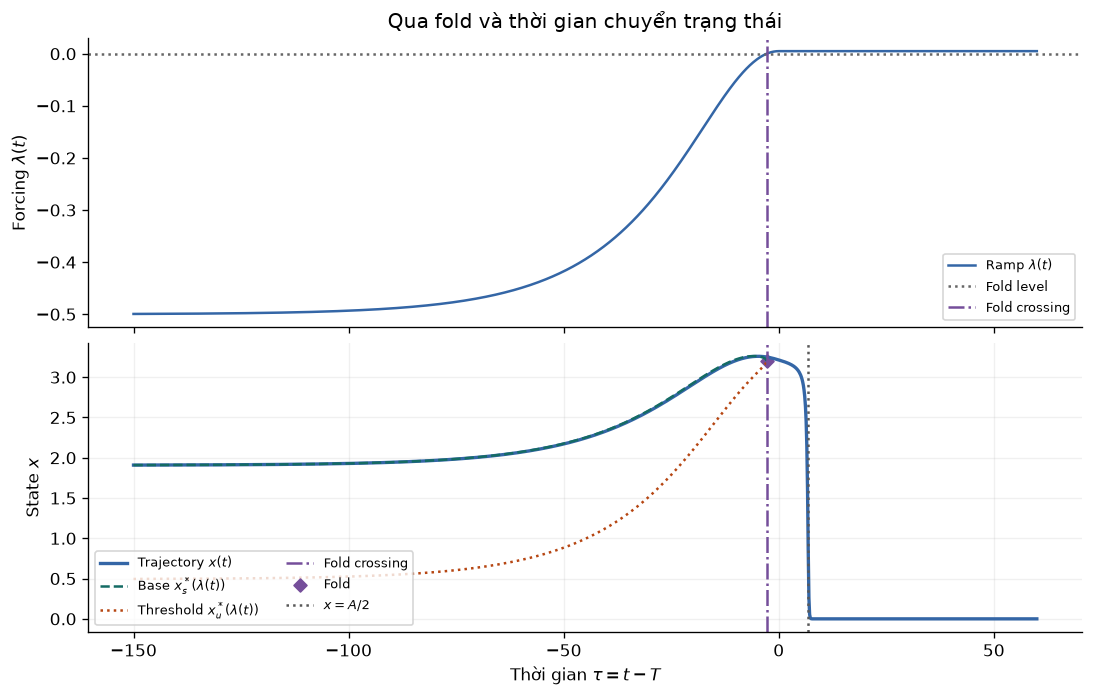

In [21]:
def instantaneous_branches(lam, A, s):
    """Các nhánh hút và đẩy trong miền bistability dương của ví dụ."""
    points = equilibrium_branches(lam, A, s)
    bistable = has_positive_bistability(lam, A, s)
    return np.where(bistable, points["+"], np.nan), np.where(bistable, points["-"], np.nan)


def plot_state_and_branches(ax, tau, x, base, threshold):
    ax.plot(tau, x, color="#3466a6", linewidth=2.0, label=r"Trajectory $x(t)$")
    ax.plot(tau, base, color="#146b64", linestyle="--", label=r"Base $x_s^*(\lambda(t))$")
    ax.plot(tau, threshold, color="#b64612", linestyle=":", label=r"Threshold $x_u^*(\lambda(t))$")
    ax.set(xlabel=r"Thời gian $\tau=t-T$", ylabel="State $x$")
    ax.grid(alpha=0.18)


tau_b = np.unique(np.r_[np.linspace(-150, 60, 1301), tau_fold_b, tau_transition_b])
lam_b = external_forcing(tau_b, lambda_i, shift_b, r_b, 0.0)
x_b = sample_forced(run_b, tau_b)
base_b, threshold_b = instantaneous_branches(lam_b, A_paper, s_paper)

fig, (ax_force, ax_state) = plt.subplots(2, 1, figsize=(9, 5.7), sharex=True,
                                         layout="constrained")
ax_force.plot(tau_b, lam_b, color="#3466a6", label=r"Ramp $\lambda(t)$")
ax_force.axhline(0, color="0.4", linestyle=":", label="Fold level")
plot_state_and_branches(ax_state, tau_b, x_b, base_b, threshold_b)
for ax in (ax_force, ax_state):
    ax.axvline(tau_fold_b, color="#754e9a", linestyle="-.", label="Fold crossing")
ax_state.scatter(tau_fold_b, A_paper, marker="D", c="#754e9a", s=30, label="Fold")
ax_state.axvline(tau_transition_b, color="0.35", linestyle=":", label=r"$x=A/2$")
ax_force.set(ylabel=r"Forcing $\lambda(t)$", title="Qua fold và thời gian chuyển trạng thái")
ax_force.legend(loc="lower right")
ax_state.legend(loc="lower left", ncol=2)
plt.show()

*Hình 4.1 · Additional experiment.* Hệ theo nhánh hút trong phần đầu của ramp, khi tốc độ phục hồi còn đủ lớn. Hai nhánh gặp nhau tại fold và biến mất sau crossing. Drift gần vị trí fold vẫn nhỏ, nên $x(t)$ lưu lại gần đó trong một khoảng thời gian rồi mới giảm nhanh. Ramp giữ $\lambda=0.005$ sau peak. Ở mức này $x=0$ là attractor duy nhất và trajectory hội tụ về đó.

### 4.4. R-tipping · Figure 2(b,e)

**Original reproduction.** Cố định $\lambda_-=-0.5$, $\Delta\lambda=0.4$, $A=3.2$, $s=4$, $T=500$ và initial condition. So sánh $r=1$ với $r=3$. Cả hai ramps dừng ở $\lambda_f=-0.1$, trong vùng BI của Module 3, nên base state tồn tại suốt thí nghiệm.

**Additional experiment.** Đo $e(t)=x(t)-x_s^*(\lambda(t))$ và $d(t)=x(t)-x_u^*(\lambda(t))$. Sai số $e<0$ cho thấy state thấp hơn moving base, và $|e|$ đo độ lệch. Khi $d<0$, state nằm phía basin của $0$ trong frozen system tại thời điểm đó. Basin boundary tiếp tục di chuyển trong hệ non-autonomous, nên dấu $d$ được đọc cùng với convergence dài hạn.

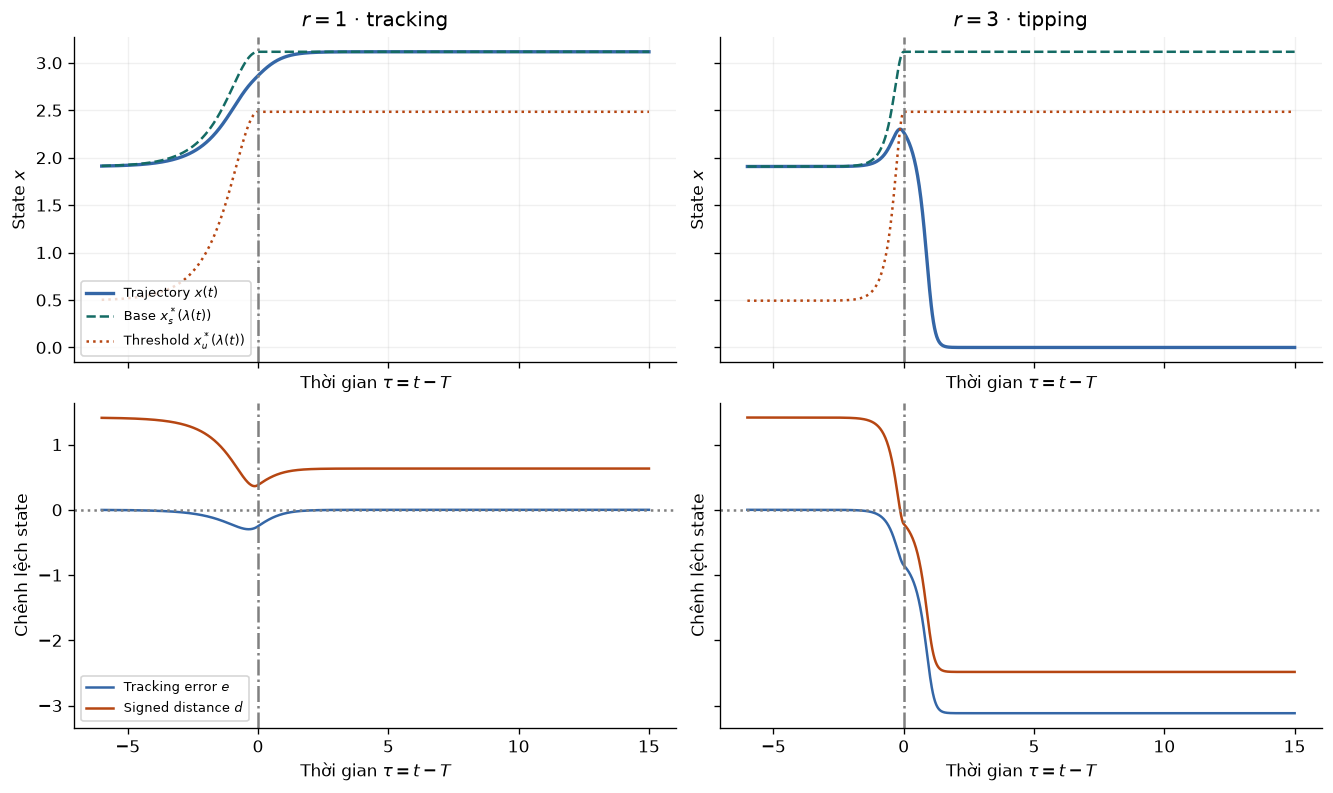

| $r$ | $\min e(t)$ | $\min d(t)$ | $x(T)$ | Outcome |
|---:|---:|---:|---:|:---|
| 1 | -0.2974 | 0.3632 | 2.8646 | tracking |
| 3 | -3.1162 | -2.4838 | 2.2665 | tipping |

In [22]:
def simulate_rate_cases(A, s, lambda_minus, shift, rates, *, T, relax_time=100.0):
    return {
        rate: evaluate_forcing(A, s, lambda_minus, shift, rate, "ramp", T=T,
                               relax_time=relax_time, dense_output=True)
        for rate in rates
    }


r_cases = simulate_rate_cases(A_paper, s_paper, lambda_i, delta_lambda_paper,
                              r_paper, T=T_paper)
tau_short = np.linspace(-6, 15, 1001)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, sharey="row",
                         layout="constrained")
r_rows = [r"| $r$ | $\min e(t)$ | $\min d(t)$ | $x(T)$ | Outcome |",
          "|---:|---:|---:|---:|:---|"]
for col, (rate, (outcome, run)) in enumerate(r_cases.items()):
    lam = external_forcing(tau_short, lambda_i, delta_lambda_paper, rate, 0.0)
    x = sample_forced(run, tau_short)
    moving_base, moving_threshold = instantaneous_branches(lam, A_paper, s_paper)
    error, distance = x - moving_base, x - moving_threshold
    plot_state_and_branches(axes[0, col], tau_short, x, moving_base, moving_threshold)
    axes[0, col].set_title(f"$r={rate:g}$ · {outcome}")
    axes[1, col].plot(tau_short, error, color="#3466a6", label=r"Tracking error $e$")
    axes[1, col].plot(tau_short, distance, color="#b64612", label=r"Signed distance $d$")
    axes[1, col].axhline(0.0, color="0.5", linestyle=":")
    axes[1, col].set(xlabel=r"Thời gian $\tau=t-T$", ylabel="Chênh lệch state")
    for ax in axes[:, col]:
        ax.axvline(0.0, color="0.5", linestyle="-.")
    r_rows.append(
        f"| {rate:g} | {error.min():.4f} | {distance.min():.4f} "
        f"| {run['x_peak']:.4f} | {outcome} |"
    )
axes[0, 0].legend(loc="lower left")
axes[1, 0].legend(loc="lower left")
plt.show()
display(Markdown("\n".join(r_rows)))
assert [case[0] for case in r_cases.values()] == ["tracking", "tipping"]

*Hình 4.2 · Additional experiment.* Ramp chậm giữ trajectory trên threshold và hội tụ về base state cuối. Ramp nhanh cho $e<0$ lớn về độ lớn, $d$ đổi sang âm, rồi state hội tụ về $0$ khi forcing cố định ở plateau. Cùng geometry BI cho phép hai outcomes vì lịch sử forcing quyết định vị trí của hệ lúc threshold dịch chuyển.

### 4.5. Return tipping · Figure 2(c,f)

**Original reproduction.** Dùng $A=1.5$, $s=-4$, $\lambda_-=-0.1$, $\Delta\lambda=-0.4$ và $T=500$ với $r=1,3$. Đây là **ramp giảm** bắt đầu gần fold và dịch ra xa tới $-0.5$. Đổi dấu $s$ làm tâm $A+s\lambda$ tăng khi $\lambda$ giảm. Threshold cũng dịch sang phải trên đoạn đang xét, đủ để initial base state rơi sang bên basin của $0$ tại mức cuối. Trước khi tích phân, kiểm tra điều đó từ các frozen equilibria.

In [23]:
A_reverse, s_reverse = 1.5, -4.0
lambda_reverse_start = lambda_f
shift_reverse = -delta_lambda_paper
lambda_reverse_end = lambda_reverse_start + shift_reverse
reverse_gap = basin_instability_gap(
    lambda_reverse_start, lambda_reverse_end, A_reverse, s_reverse,
)
lambda_bi_reverse = brentq(
    lambda lam: basin_instability_gap(lambda_reverse_start, lam, A_reverse, s_reverse),
    lambda_reverse_end, lambda_reverse_start,
)

reverse_rows = [r"| $\lambda$ | Nhánh | $x^*$ | $J$ | Stability |",
                "|---:|:---:|---:|---:|:---|"]
for lam in (lambda_reverse_start, lambda_reverse_end):
    points = frozen_equilibria(lam, A_reverse, s_reverse)
    assert [point[3] for point in points] == ["stable", "unstable", "stable"]
    for branch, x, J, stability in points:
        reverse_rows.append(f"| {lam:.1f} | $x_{branch}^*$ | {x:.6f} | {J:.6f} | {stability} |")
assert reverse_gap > 0
display(Markdown("\n".join(reverse_rows)))
display(Markdown(f"BI gap cuối bằng {reverse_gap:.6f}. "
                 rf"Threshold trùng initial base state tại $\lambda={lambda_bi_reverse:.6f}$."))

| $\lambda$ | Nhánh | $x^*$ | $J$ | Stability |
|---:|:---:|---:|---:|:---|
| -0.1 | $x_0^*$ | 0.000000 | -3.510000 | stable |
| -0.1 | $x_-^*$ | 1.583772 | 1.001666 | unstable |
| -0.1 | $x_+^*$ | 2.216228 | -1.401666 | stable |
| -0.5 | $x_0^*$ | 0.000000 | -11.750000 | stable |
| -0.5 | $x_-^*$ | 2.792893 | 3.949747 | unstable |
| -0.5 | $x_+^*$ | 4.207107 | -5.949747 | stable |

BI gap cuối bằng 0.576665. Threshold trùng initial base state tại $\lambda=-0.320614$.

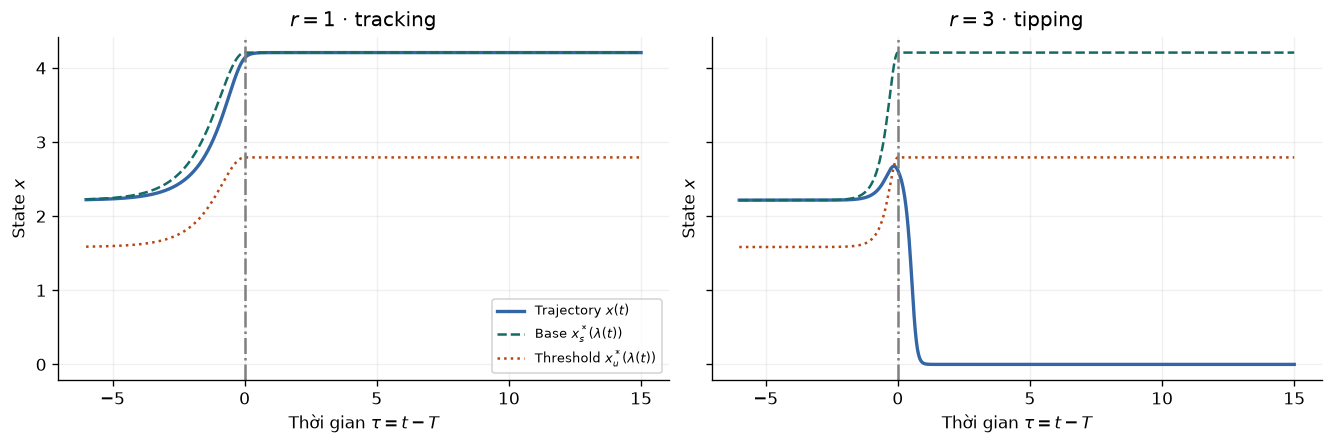

In [24]:
reverse_cases = simulate_rate_cases(A_reverse, s_reverse, lambda_reverse_start,
                                    shift_reverse, r_paper, T=T_paper)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, (rate, (outcome, run)) in zip(axes, reverse_cases.items()):
    lam = external_forcing(tau_short, lambda_reverse_start, shift_reverse, rate, 0.0)
    x = sample_forced(run, tau_short)
    moving_base, moving_threshold = instantaneous_branches(lam, A_reverse, s_reverse)
    plot_state_and_branches(ax, tau_short, x, moving_base, moving_threshold)
    ax.axvline(0.0, color="0.5", linestyle="-.")
    ax.set_title(f"$r={rate:g}$ · {outcome}")
axes[0].legend(loc="lower right")
plt.show()
assert [case[0] for case in reverse_cases.values()] == ["tracking", "tipping"]

*Hình 4.3 · Additional experiment.* Khi $\lambda$ giảm từ $-0.1$ đến $-0.5$, khoảng cách tới fold lớn dần và base state vẫn hút. Ramp chậm đủ thời gian để state tăng cùng base state. Ramp nhanh làm threshold tăng vượt state, sau đó trajectory hội tụ về $0$. Đây là **R-tipping khi đảo chiều forcing**. Symmetric return impulse ở Module 5 có cả nhánh đi và nhánh về.

### 4.6. Figure 2 · Sáu panels

**Original reproduction với đúng tham số.** Hàng trên đối chiếu các forcing histories. Hàng dưới đặt actual trajectories lên các frozen branches. Vùng xám là **endpoint Basin Instability** so với initial base state của từng cột. Cột đầu tiếp tục qua fold dù vùng BI chỉ kết thúc ở fold. Cột thứ ba theo chiều giảm $\lambda$.

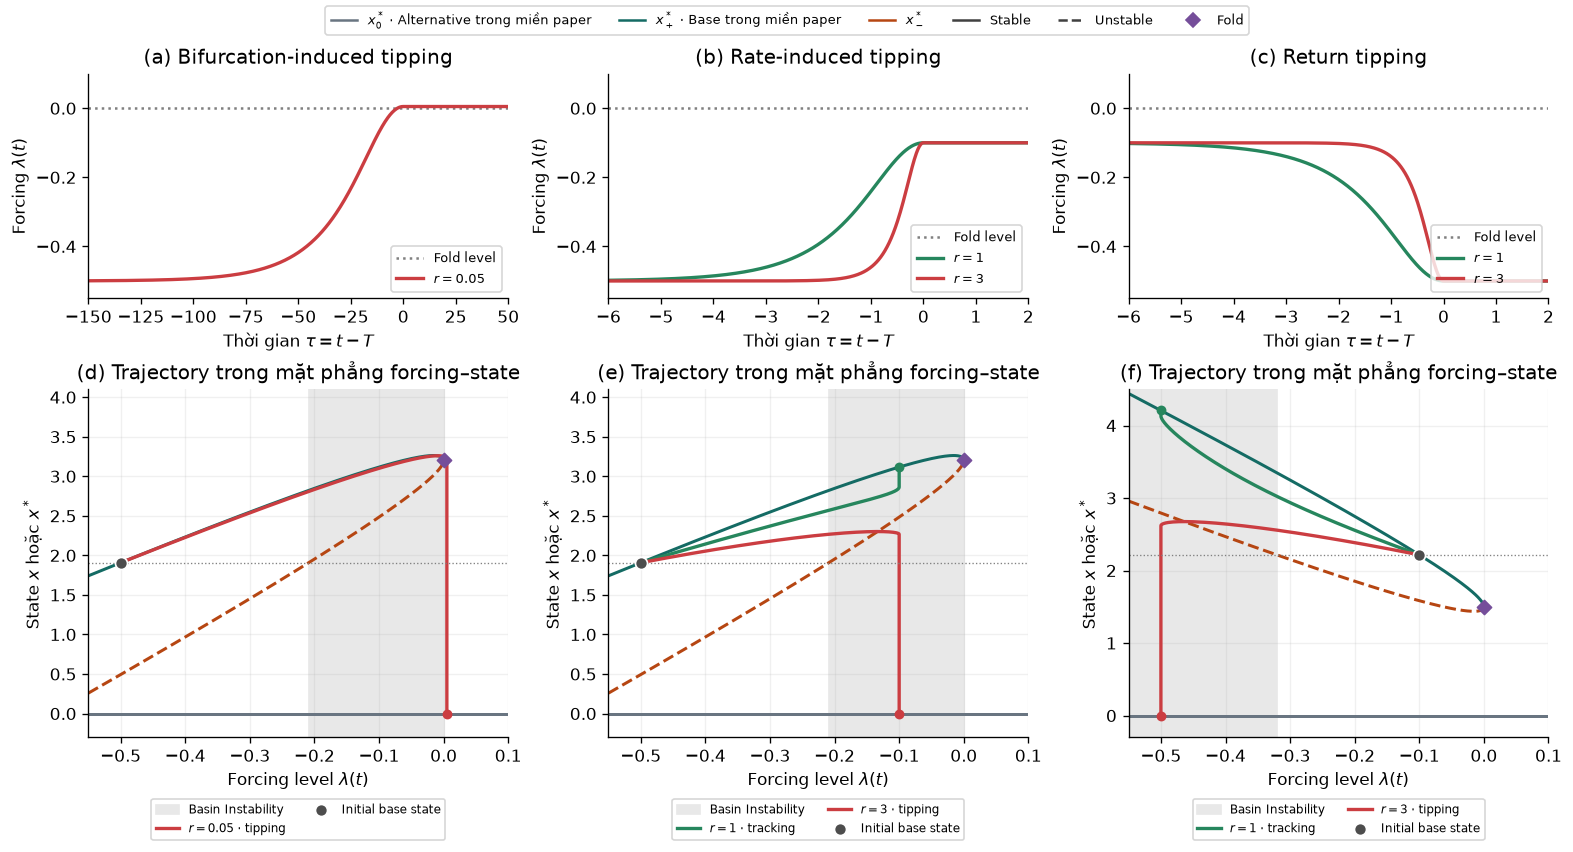

In [25]:
# Mỗi cột gồm tham số mô hình, forcing, cửa sổ hiển thị và kết quả ODE.
figure2_columns = [
    (A_paper, s_paper, lambda_i, shift_b, (-150, 50), (lambda_bi, 0),
     {r_b: (label_b, run_b)}, "Bifurcation-induced tipping"),
    (A_paper, s_paper, lambda_i, delta_lambda_paper, (-6, 2), (lambda_bi, 0),
     r_cases, "Rate-induced tipping"),
    (A_reverse, s_reverse, lambda_reverse_start, shift_reverse, (-6, 2),
     (-0.55, lambda_bi_reverse), reverse_cases, "Return tipping"),
]
outcome_colors = {"tracking": "#26865d", "tipping": "#cb3d41"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.0), height_ratios=(1, 1.55),
                         layout="constrained")
for col, (A, s, lam_initial, shift, time_limits, bi_limits, cases, title) in enumerate(figure2_columns):
    ax_forcing, ax_state = axes[:, col]
    ax_forcing.axhline(0.0, color="0.5", linestyle=":", label="Fold level")
    ax_state.axvspan(*bi_limits, color="0.91", label="Basin Instability")
    plot_bifurcation(ax_state, A, s, (-0.55, 0.10))
    ax_state.set(xlabel=r"Forcing level $\lambda(t)$", ylabel=r"State $x$ hoặc $x^*$",
                 ylim=(-0.3, 4.5 if col == 2 else 4.1))
    for rate, (outcome, run) in cases.items():
        color = outcome_colors[outcome]
        tau_forcing = np.linspace(*time_limits, 601)
        ax_forcing.plot(
            tau_forcing, external_forcing(tau_forcing, lam_initial, shift, rate, 0.0),
            color=color, linewidth=2, label=f"$r={rate:g}$",
        )
        tau_path = np.unique(np.r_[np.linspace(-T_paper, 100, 1201),
                                   np.linspace(*time_limits, 1001), 0.0])
        x_path = sample_forced(run, tau_path)
        lam_path = external_forcing(tau_path, lam_initial, shift, rate, 0.0)
        ax_state.plot(lam_path, x_path, color=color, linewidth=2.0,
                      label=f"$r={rate:g}$ · {outcome}")
        ax_state.scatter(lam_path[-1], x_path[-1], color=color, s=24, zorder=6)
    ax_state.scatter(lam_initial, run["x_initial"], color="0.3", edgecolors="white", s=52,
                     zorder=7, label="Initial base state")
    ax_state.axhline(run["x_initial"], linewidth=0.8, color="0.5", linestyle=":")
    ax_forcing.set(title=f"({chr(97 + col)}) {title}", xlim=time_limits, ylim=(-0.55, 0.10),
                   xlabel=r"Thời gian $\tau=t-T$", ylabel=r"Forcing $\lambda(t)$")
    ax_forcing.legend(loc="lower right")
    ax_state.set_title(f"({chr(100 + col)}) Trajectory trong mặt phẳng forcing–state")
    ax_state.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=7, ncol=2)

fig.legend(handles=bifurcation_legend[:-1], ncol=6, loc="outside upper center")
plt.show()

*Figure 2 tái tạo.* Các cặp (a,d), (b,e) và (c,f) cho cùng outcomes và cùng thứ tự cơ chế với bài báo. Đường liền/đứt của equilibrium thể hiện stability, chấm tím chỉ fold, màu đỏ/xanh biểu diễn trajectories tipping/tracking. Trục có giá trị số và vùng BI lấy từ nghiệm phương trình threshold, thay cho việc dò giao điểm trên lưới của script gốc. Mã gốc tích phân Euler với $\Delta t=0.01$. Notebook dùng LSODA và kiểm tra sai khác phương pháp ở §4.7. [Paper, Figure 2](../paper/23%20Rate-induced%20tipping%20in%20natural%20and%20human%20systems.pdf#page=4) · [Script Figure 2](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Tilted_SN_timeseries_bif_rate_return_tipping_plots_v2.py)

### 4.7. Kiểm tra convergence và tổng hợp Figure 2

**Mục tiêu.** So sánh outcomes và trajectories khi thay tolerance, giới hạn bước và post-peak horizon. Thêm một phép đối chiếu Euler theo cấu hình Figure 2(e), trên lưới thời gian của script.

In [26]:
tight_solver = {"rtol": 1e-10, "atol": 1e-12, "rate_step": 0.25}

def check_run_convergence(standard, config, rate, profile, tau_check, *, T=None):
    """So outcome và max trajectory difference ở các mốc tau_check."""
    outcome, run = standard
    tight_outcome, tight_run = evaluate_forcing(
        *config, rate, profile, T=T, relax_time=150, initial_tail=1e-8,
        dense_output=True, **tight_solver,
    )
    error = np.max(np.abs(sample_forced(run, tau_check) - sample_forced(tight_run, tau_check)))
    assert outcome == tight_outcome and outcome != "unresolved"
    return error


summary4 = [r"| Panel | $\Delta\lambda$ | $r$ | Hướng | Vượt fold | BI ở đích | Outcome | Cơ chế |",
            "|:---:|---:|---:|:---|:---:|:---:|:---|:---|"]
figure2_errors = []
for col, (A, s, lam_initial, shift, time_limits, _, cases, title) in enumerate(figure2_columns):
    lam_end = forcing_limit(lam_initial, shift, "ramp")
    bi_end = basin_instability_gap(lam_initial, lam_end, A, s)
    bi_label = "— (mất base)" if np.isnan(bi_end) else ("Có" if bi_end > 0 else "Không")
    for rate, (outcome, run) in cases.items():
        error = check_run_convergence((outcome, run), (A, s, lam_initial, shift),
                                      rate, "ramp", np.linspace(*time_limits, 401), T=T_paper)
        figure2_errors.append(error)
        mechanism = title if outcome == "tipping" else "Tracking"
        direction = "Tăng" if shift > 0 else "Giảm"
        crosses_fold = lam_initial < 0 < lam_end
        summary4.append(f"| {chr(100 + col)} | {shift:+.3f} | {rate:g} | {direction} "
                        f"| {'Có' if crosses_fold else 'Không'} | {bi_label} "
                        f"| {outcome} | {mechanism} |")
assert max(figure2_errors) < 2e-5
display(Markdown("\n".join(summary4)))
display(Markdown(f"Sai khác lớn nhất khi siết solver trên các cửa sổ Figure 2 là "
                 f"{max(figure2_errors):.2e} theo state. Cả năm outcomes trùng nhau."))

| Panel | $\Delta\lambda$ | $r$ | Hướng | Vượt fold | BI ở đích | Outcome | Cơ chế |
|:---:|---:|---:|:---|:---:|:---:|:---|:---|
| d | +0.505 | 0.05 | Tăng | Có | — (mất base) | tipping | Bifurcation-induced tipping |
| e | +0.400 | 1 | Tăng | Không | Có | tracking | Tracking |
| e | +0.400 | 3 | Tăng | Không | Có | tipping | Rate-induced tipping |
| f | -0.400 | 1 | Giảm | Không | Có | tracking | Tracking |
| f | -0.400 | 3 | Giảm | Không | Có | tipping | Return tipping |

Sai khác lớn nhất khi siết solver trên các cửa sổ Figure 2 là 4.02e-06 theo state. Cả năm outcomes trùng nhau.

In [27]:
def forward_euler_reference(lam, x_initial, A, s, dt):
    """Đối chiếu với bước cố định dùng trong các scripts của tác giả."""
    x = np.empty_like(lam)
    x[0] = x_initial
    for k, forcing_level in enumerate(lam[:-1]):
        x[k + 1] = x[k] + dt * vector_field(x[k], forcing_level, A, s)
    return x


tau_euler = np.linspace(-T_paper, 100, 60_001)
lam_euler = external_forcing(tau_euler, lambda_i, delta_lambda_paper, 3.0, 0.0)
x_euler = forward_euler_reference(lam_euler, r_cases[3.0][1]["x_initial"],
                                  A_paper, s_paper, 0.01)
display_mask = (tau_euler >= -6) & (tau_euler <= 2)
euler_difference = np.max(np.abs(
    x_euler[display_mask] - sample_forced(r_cases[3.0][1], tau_euler[display_mask]),
))
euler_run = {"x_end": x_euler[-1], "lam_end": lam_euler[-1], "lam_final": lambda_f}
assert classify_tipping_outcome(euler_run, A_paper, s_paper) == r_cases[3.0][0]
display(Markdown(f"Figure 2(e), $r=3$. Euler và LSODA cho cùng outcome. "
                 f"Max sai khác state trên cửa sổ vẽ $[-6,2]$ là {euler_difference:.3e}."))

Figure 2(e), $r=3$. Euler và LSODA cho cùng outcome. Max sai khác state trên cửa sổ vẽ $[-6,2]$ là 6.388e-02.

Figure 2 cho thấy hai đường dẫn đến cùng alternative state. Vượt fold vĩnh viễn xóa base state (d). Trong hai ramps còn lại, tilt và hướng forcing cho BI, còn rate quyết định quỹ đạo có giữ được tracking hay rơi vào basin của $0$ (e,f).

## Module 5 — Systematic Parameter Exploration · Figure 3

### 5.1–5.2. External forcing · Figure 3(a)

**Mục tiêu.** So sánh một permanent ramp với một symmetric return impulse có cùng nhánh đi vào peak, rồi xác định những vùng tracking và tipping trong mặt phẳng $(\Delta\lambda,r)$.

**Original reproduction.** Appendix A2 cho $A=3.2$, $s=4$, $\lambda_-=-0.5$ và $r\in\{0.5,0.9,1.7\}$. Script Figure 3 xác nhận $\Delta\lambda=0.48$, $\lambda_{\mathrm{peak}}=-0.02$, mốc bắt đầu $\tau=-500$ và cửa sổ vẽ $[-10,10]$. Dùng $T=500$ như script. Ở rate nhỏ nhất, $a(0)=\operatorname{sech}(250)\ll10^{-4}$. Khi quét lưới, dùng $T=\operatorname{arcosh}(10^4)/r$ để đạt cùng độ chính xác khởi tạo với thời gian tích phân phù hợp cho từng $r$. [Script Figure 3](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Tilted_SN_plotting_time_series_critical_boundaries_regions_v3.py)

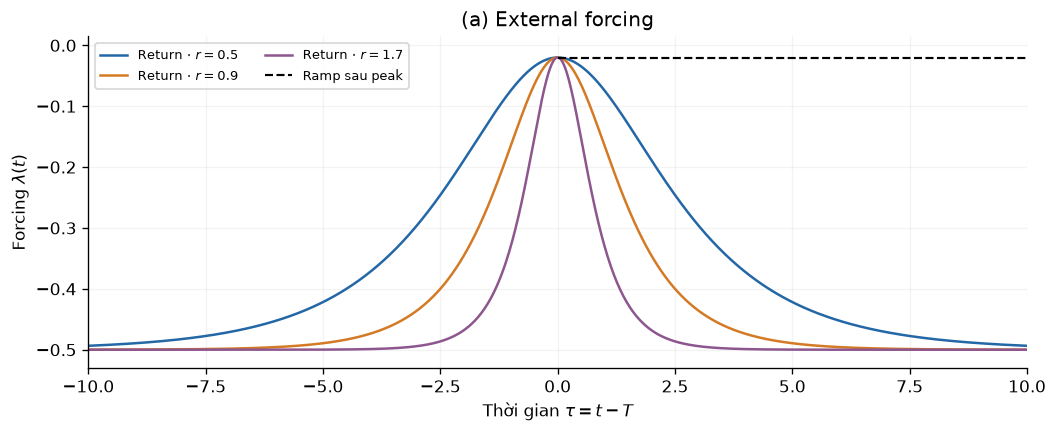

In [28]:
figure3_shift = 0.48
figure3_rates = (0.5, 0.9, 1.7)
figure3_colors = ("#2467a6", "#d47a24", "#8e568e")
figure3_T = 500.0
tau3 = np.linspace(-10.0, 10.0, 1201)
profiles = ("ramp", "return")

assert return_profile(0.0, min(figure3_rates), figure3_T) <= 1e-4
np.testing.assert_allclose(forcing_limit(lambda_i, figure3_shift, "ramp"), -0.02)
np.testing.assert_allclose(forcing_limit(lambda_i, figure3_shift, "return"), -0.5)

for rate in figure3_rates:
    left = tau3 <= 0
    ramp = external_forcing(tau3[left], lambda_i, figure3_shift, rate, 0, "ramp")
    pulse = external_forcing(tau3[left], lambda_i, figure3_shift, rate, 0, "return")
    np.testing.assert_array_equal(ramp, pulse)


def plot_figure3_forcing(ax):
    for rate, color in zip(figure3_rates, figure3_colors):
        pulse = external_forcing(tau3, lambda_i, figure3_shift, rate, 0, "return")
        ax.plot(tau3, pulse, color=color, label=f"Return · $r={rate:g}$")
    after_peak = tau3 >= 0
    ramp = external_forcing(tau3[after_peak], lambda_i, figure3_shift, figure3_rates[0], 0)
    ax.plot(tau3[after_peak], ramp, "k--", linewidth=1.3, label="Ramp sau peak")
    ax.set(xlim=(-10, 10), ylim=(-0.53, 0.015), ylabel=r"Forcing $\lambda(t)$",
           xlabel=r"Thời gian $\tau=t-T$", title="(a) External forcing")
    ax.legend(loc="upper left", ncol=2)
    ax.grid(alpha=0.15)


fig, ax = plt.subplots(figsize=(8.7, 3.5), layout="constrained")
plot_figure3_forcing(ax)
plt.show()

*Figure 3(a).* Sáu histories có cùng peak và đều ở dưới fold. Với từng $r$, ramp và return chỉ tách sau peak. Tăng $r$ làm nhánh đi vào và nhánh trở về dốc hơn, đồng thời rút ngắn thời gian ở mức forcing cao của return.

### 5.3. System responses · Figure 3(b)

**Original reproduction.** Giải cả sáu ODE và phân loại theo attractor cuối. Cửa sổ vẽ dùng đúng $[-10,10]$ của script. Tích phân kéo dài qua cửa sổ đó để kiểm tra convergence. Chạy thêm bộ tolerance chặt cho cả sáu trajectory.

In [29]:
figure3_config = (A_paper, s_paper, lambda_i, figure3_shift)
figure3_runs = {}
figure3_errors = []
for rate in figure3_rates:
    for profile in profiles:
        case = evaluate_forcing(*figure3_config, rate, profile,
                                T=figure3_T, dense_output=True)
        figure3_runs[rate, profile] = case
        figure3_errors.append(
            check_run_convergence(case, figure3_config, rate, profile, tau3, T=figure3_T)
        )
    assert abs(figure3_runs[rate, "ramp"][1]["x_peak"]
               - figure3_runs[rate, "return"][1]["x_peak"]) < 1e-12

observed_figure3 = [tuple(figure3_runs[rate, profile][0] for profile in profiles)
                    for rate in figure3_rates]
assert observed_figure3 == [("tracking", "tracking"), ("tipping", "tracking"),
                            ("tipping", "tipping")]
assert max(figure3_errors) < 2e-5

rows3 = [r"| $r$ | Ramp | Return | $x(T)$ chung | $x_{\mathrm{end}}$ ramp | $x_{\mathrm{end}}$ return |",
         "|---:|:---|:---|---:|---:|---:|"]
for rate in figure3_rates:
    label_ramp, run_ramp = figure3_runs[rate, "ramp"]
    label_return, run_return = figure3_runs[rate, "return"]
    rows3.append(f"| {rate:g} | {label_ramp} | {label_return} | {run_ramp['x_peak']:.6f} "
                 f"| {run_ramp['x_end']:.6g} | {run_return['x_end']:.6g} |")
display(Markdown("\n".join(rows3)))
display(Markdown(f"Max sai khác state giữa hai cấu hình solver là {max(figure3_errors):.2e}."))

| $r$ | Ramp | Return | $x(T)$ chung | $x_{\mathrm{end}}$ ramp | $x_{\mathrm{end}}$ return |
|---:|:---|:---|---:|---:|---:|
| 0.5 | tracking | tracking | 3.105954 | 3.26142 | 1.90711 |
| 0.9 | tipping | tracking | 2.763083 | -6.02384e-21 | 1.90711 |
| 1.7 | tipping | tipping | 2.208486 | -5.63645e-21 | -2.77268e-15 |

Max sai khác state giữa hai cấu hình solver là 1.05e-06.

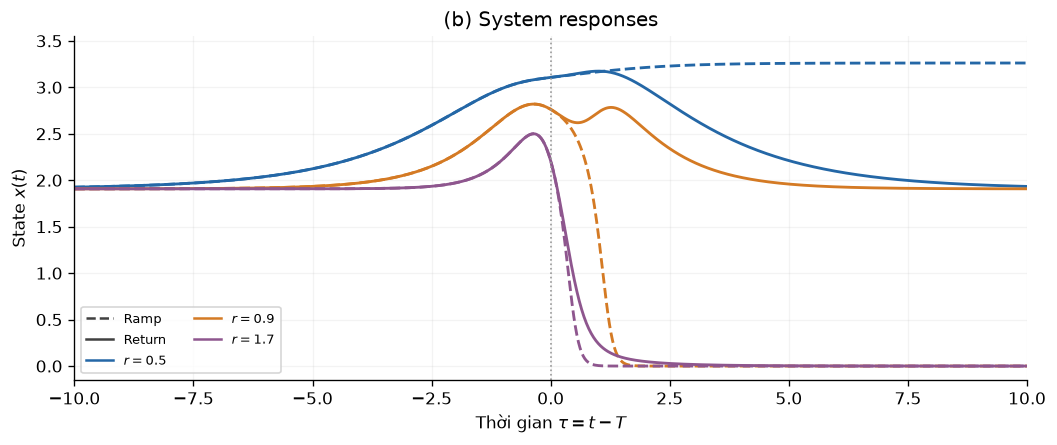

In [30]:
def plot_figure3_responses(ax):
    for rate, color in zip(figure3_rates, figure3_colors):
        for profile, linestyle in (("ramp", "--"), ("return", "-")):
            _, run = figure3_runs[rate, profile]
            ax.plot(tau3, sample_forced(run, tau3), linestyle=linestyle, color=color, linewidth=1.7)
    ax.axvline(0.0, color="0.6", linestyle=":", linewidth=1)
    ax.set(xlim=(-10, 10), ylim=(-0.15, 3.55), title="(b) System responses",
           xlabel=r"Thời gian $\tau=t-T$", ylabel="State $x(t)$")
    ax.legend(handles=[
        Line2D([], [], color="0.25", linestyle="--", label="Ramp"),
        Line2D([], [], color="0.25", linestyle="-", label="Return"),
        *[Line2D([], [], color=color, label=f"$r={rate:g}$")
          for rate, color in zip(figure3_rates, figure3_colors)],
    ], loc="lower left", ncol=2)
    ax.grid(alpha=0.15)


fig, ax = plt.subplots(figsize=(8.7, 3.6), layout="constrained")
plot_figure3_responses(ax)
plt.show()

*Figure 3(b).* Ở $r=0.5$, cả hai trajectories theo nhánh hút tương ứng và về base state cuối của profile. Ở $r=0.9$, ramp giữ threshold cao sau peak, còn return đưa threshold trở xuống đủ sớm để state hồi phục. Ở $r=1.7$, state tụt sâu hơn ở peak và cả hai profiles cuối cùng hội tụ về $0$. Cả ba kết quả đều được xác định từ ODE trước khi so với paper.

**Đối chiếu số Figure 3(b).** Với $r=0.9$, đo chênh lệch state giữa LSODA và Euler với $\Delta t=0.001$ trên cửa sổ hiển thị của tác giả. Kiểm tra cả ramp và return, vì hai profiles cho outcome khác nhau tại rate này.

In [31]:
tau_euler3 = np.linspace(-figure3_T, 10.0, 510_001)
mask_euler3 = tau_euler3 >= -10.0
euler_errors3 = {}
for profile in profiles:
    outcome, run = figure3_runs[0.9, profile]
    lam = external_forcing(tau_euler3, lambda_i, figure3_shift, 0.9, 0.0, profile)
    x_euler3 = forward_euler_reference(lam, run["x_initial"], A_paper, s_paper, 0.001)
    euler_errors3[profile] = np.max(np.abs(
        x_euler3[mask_euler3] - sample_forced(run, tau_euler3[mask_euler3]),
    ))
display(Markdown(
    f"Sai khác Euler–LSODA lớn nhất theo state là {euler_errors3['ramp']:.3e} "
    f"cho ramp và {euler_errors3['return']:.3e} cho return. "
    "Outcome được xác định từ tích phân qua cửa sổ so sánh."
))

Sai khác Euler–LSODA lớn nhất theo state là 1.457e-02 cho ramp và 1.646e-03 cho return. Outcome được xác định từ tích phân qua cửa sổ so sánh.

### 5.4. Định nghĩa numerical outcomes

**Mục tiêu.** Gán outcome theo trạng thái tiệm cận tương ứng với profile, kể cả khi hai trajectories tạm đi qua cùng một vùng state space.

- Ramp dừng ở $\lambda_\infty=\lambda_-+\Delta\lambda$. Return tiến về $\lambda_\infty=\lambda_-$.
- **Tracking.** Forcing cuối đủ gần $\lambda_\infty$ và state nằm trong tolerance của stable base $x_+^*(\lambda_\infty)$. Tolerance theo state là $10^{-5}\max(1,|x_+^*|)$, chặn trên bằng một phần tư độ cách basin boundary để tránh gán nhầm near-threshold state.
- **Tipping.** Sai khác forcing không quá $10^{-7}$ và state cách stable alternative equilibrium $0$ không quá $10^{-5}$. Nếu ramp vượt fold, $0$ là đích duy nhất và phép thử vẫn yêu cầu đủ gần $0$.
- **Unresolved.** Chưa vào lân cận một attractor thích hợp hoặc forcing chưa đủ gần asymptotic level. Nếu cần, thời gian thư giãn tăng từ 60 lên 240. Với ramp dừng đúng fold, $x>A$ hội tụ một phía về $A$ theo $\dot x=-x(x-A)^2$. Phân loại tracking khi state nằm trên phía đó với biên số $10^{-5}$.

Trong miền tham số ở đây, $x=0$ cách threshold dương khi còn bistability. Sai số âm cỡ tolerance quanh $0$ có thể xuất hiện trong tích phân số và được đánh giá bằng khoảng cách tới equilibrium. Tolerance này dùng để kiểm tra convergence đến đích, và mọi điểm chưa kết luận được được giữ lại trong lưới.

In [32]:
last_branches = equilibrium_branches(lambda_f, A_paper, s_paper)
final_test = {"lam_end": lambda_f, "lam_final": lambda_f}
for x_end, expected in ((last_branches["+"], "tracking"), (0.0, "tipping"),
                        (last_branches["-"], "unresolved")):
    assert classify_tipping_outcome({**final_test, "x_end": x_end}, A_paper, s_paper) == expected
assert classify_tipping_outcome(
    {**final_test, "lam_end": lambda_f + 0.01, "x_end": 0.0}, A_paper, s_paper,
) == "unresolved"
assert classify_tipping_outcome(run_b, A_paper, s_paper) == "tipping"
display(Markdown("Đã kiểm tra classifier tại hai attractors, đúng threshold, khi forcing "
                 "chưa ổn định và sau khi base state đã biến mất."))

Đã kiểm tra classifier tại hai attractors, đúng threshold, khi forcing chưa ổn định và sau khi base state đã biến mất.

### 5.5. Coarse grid và lưới Figure 3(c)

**Approximate reproduction.** Mã vẽ Figure 3(c) lấy boundary arrays từ các file MAT, nội suy theo $r$, và đặt trục hiển thị $\Delta\lambda\in[0.25,0.60]$, $r\in[0.1,50]$. Script bisection công bố là ví dụ theo forcing magnitude tại một $r$ cố định, với $A=3$ và $\lambda_-=-0.4$ khác Figure 3. Notebook tính lại boundaries từ Eq. (A3) với đúng tham số của Figure 3. [Script vẽ](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Tilted_SN_plotting_time_series_critical_boundaries_regions_v3.py) · [Script bisection](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Tilted_SN_bisection.py) · [Kho dữ liệu tác giả](https://zenodo.org/records/7920243)

Lấy $\Delta\lambda$ cách đều tuyến tính và $r$ cách đều trên log scale. Với mỗi ô, tạo hai profiles, giải ODE, phân loại theo §5.4 và lưu outcome cùng $x(T)$ và state cuối. Chạy coarse grid $15\times17$ trước, sau đó tính lưới $71\times65$ có chứa toàn bộ coarse points. Kết quả lưu trong hai file NPZ dưới results/ritchie_2023, với khóa theo lưới, tham số và nội dung các hàm tính toán. Khi sửa cell vẽ, có thể đọc lại lưới đã tính.

In [33]:
from hashlib import sha256
from inspect import getsource
from pathlib import Path
from tempfile import NamedTemporaryFile

OUTCOME_CODES = {"unresolved": -1, "tracking": 0, "tipping": 1}
CODE_TO_OUTCOME = {value: key for key, value in OUTCOME_CODES.items()}
sweep_settings = {"initial_tail": 1e-4, "return_tail": 1e-8, "relax_time": 60.0,
                  "rtol": 1e-8, "atol": 1e-10, "rate_step": 0.5}
sweep_system = (A_paper, s_paper, lambda_i)
shift_grid = np.linspace(0.25, 0.60, 71)
rate_grid = np.geomspace(0.1, 50.0, 65)
coarse_shifts, coarse_rates = shift_grid[::5], rate_grid[::4]

notebook_cwd = Path.cwd()
results_root = notebook_cwd.parent if notebook_cwd.name == "Replication_Research" else notebook_cwd
sweep_cache_dir = results_root / "results" / "ritchie_2023"


def solve_parameter_grid(shifts, rates, system, settings, *, seed=None):
    """Lưới (profile, rate, shift), lưu outcome, state tại peak và state cuối."""
    shape = (len(profiles), len(rates), len(shifts))
    grid = {
        "outcomes": np.full(shape, -2, dtype=np.int8),
        "x_peak": np.full(shape, np.nan),
        "x_end": np.full(shape, np.nan),
    }
    if seed is not None:
        seed_shifts, seed_rates, seed_grid = seed
        seed_indices = np.ix_(range(len(profiles)), np.searchsorted(rates, seed_rates),
                              np.searchsorted(shifts, seed_shifts))
        for name, values in grid.items():
            values[seed_indices] = seed_grid[name]

    for p, i, j in np.argwhere(grid["outcomes"] == -2):
        outcome, run = evaluate_forcing(*system, shifts[j], rates[i], profiles[p], **settings)
        grid["outcomes"][p, i, j] = OUTCOME_CODES[outcome]
        grid["x_peak"][p, i, j] = run["x_peak"]
        grid["x_end"][p, i, j] = run["x_end"]
    return grid


def cached_parameter_grid(name, shifts, rates, system, settings, *, seed=None):
    functions = (sech, forcing_limit, external_forcing, ramp_profile, return_profile,
                 minimum_peak_time, vector_field, jacobian, equilibrium_branches,
                 has_positive_bistability, classify_stability, solve_forced,
                 classify_tipping_outcome, evaluate_forcing, solve_parameter_grid)
    key = sha256(shifts.tobytes() + rates.tobytes())
    key.update(repr((system, settings, profiles, OUTCOME_CODES, scipy.__version__)).encode())
    key.update("".join(getsource(function) for function in functions).encode())
    path = sweep_cache_dir / f"{name}-{key.hexdigest()[:16]}.npz"
    if path.is_file():
        with np.load(path, allow_pickle=False) as data:
            grid = {key: data[key] for key in ("outcomes", "x_peak", "x_end")}
        return grid, path.name

    grid = solve_parameter_grid(shifts, rates, system, settings, seed=seed)
    path.parent.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(dir=path.parent, delete=False) as temp:
        temporary_path = Path(temp.name)
        try:
            np.savez_compressed(temp, shifts=shifts, rates=rates, profiles=profiles, **grid)
            temp.flush()
            temporary_path.replace(path)
        finally:
            temporary_path.unlink(missing_ok=True)
    return grid, path.name

In [34]:
coarse_grid, coarse_cache = cached_parameter_grid(
    "coarse", coarse_shifts, coarse_rates, sweep_system, sweep_settings,
)
assert set(np.unique(coarse_grid["outcomes"])) <= set(CODE_TO_OUTCOME)
assert all(np.any(profile_grid == OUTCOME_CODES["tipping"])
           and np.any(profile_grid == OUTCOME_CODES["tracking"])
           for profile_grid in coarse_grid["outcomes"])
display(Markdown(f"Coarse grid đã có tracking và tipping cho cả hai profiles. Cache {coarse_cache}."))

fine_grid, fine_cache = cached_parameter_grid(
    "figure3", shift_grid, rate_grid, sweep_system, sweep_settings,
    seed=(coarse_shifts, coarse_rates, coarse_grid),
)
outcomes_grid = fine_grid["outcomes"]
np.testing.assert_array_equal(outcomes_grid[:, ::4, ::5], coarse_grid["outcomes"])
np.testing.assert_allclose(fine_grid["x_peak"][0], fine_grid["x_peak"][1], atol=1e-12)
assert np.isfinite(fine_grid["x_end"]).all()
unresolved_count = int(np.count_nonzero(outcomes_grid == OUTCOME_CODES["unresolved"]))
display(Markdown(f"Lưới Figure 3(c) có {outcomes_grid.size:,} kết quả profile, "
                 f"{unresolved_count} unresolved. Cache {fine_cache}."))

Coarse grid đã có tracking và tipping cho cả hai profiles. Cache coarse-55fd679b3b15fbfe.npz.

Lưới Figure 3(c) có 9,230 kết quả profile, 0 unresolved. Cache figure3-6488a5d1ed694a2a.npz.

### 5.6. Ước lượng critical rates

**Mục tiêu.** Xác định mọi khoảng đổi outcome có thể phát hiện theo $r$ tại một $\Delta\lambda$ cố định. Critical rate nằm giữa hai rates lân cận cho outcomes khác nhau đối với cùng profile và initial condition.

Quét cột rate để tìm tất cả cặp điểm đã phân loại có outcome khác nhau. Bisection tại geometric midpoint giữ bracket có hai đầu cho outcomes đối diện. Nếu midpoint unresolved, thử thêm hai điểm ở phần tư trên log scale và chỉ thu hẹp khi còn bracket hai đầu đã biết. Dừng khi độ rộng tương đối không quá $2\times10^{-4}$ hoặc không phân loại được các điểm bên trong. Khi dừng sớm, giữ và báo độ rộng thực tế. Một lưới hữu hạn có thể bỏ sót cửa sổ tipping hẹp hoặc hai transitions trong cùng khoảng. Các lát cắt dưới đây giữ thứ tự transitions phát hiện được.

In [35]:
def transition_brackets(rates, labels):
    """Tìm mọi cặp rates đã giải được có đổi outcome trong lát cắt."""
    known = np.flatnonzero(np.asarray(labels) != OUTCOME_CODES["unresolved"])
    return [(rates[i], rates[j], labels[i], labels[j])
            for i, j in zip(known[:-1], known[1:]) if labels[i] != labels[j]]


def refine_rate_bracket(evaluate, bracket, relative_width=2e-4):
    """Refine một bracket trên log r và bảo toàn outcome ở hai đầu."""
    low, high, left_label, right_label = bracket
    while high / low - 1 > relative_width:
        midpoint = np.sqrt(low * high)
        middle_label = evaluate(midpoint)
        if middle_label == left_label:
            low = midpoint
        elif middle_label == right_label:
            high = midpoint
        else:
            quarter_rates = (np.sqrt(low * midpoint), np.sqrt(midpoint * high))
            samples = [(low, left_label)]
            samples.extend((rate, evaluate(rate)) for rate in quarter_rates)
            samples.append((high, right_label))
            known = [(rate, label) for rate, label in samples if label != -1]
            candidates = [(a, b, label_a, label_b)
                          for (a, label_a), (b, label_b) in zip(known[:-1], known[1:])
                          if label_a != label_b]
            a, b, label_a, label_b = min(candidates, key=lambda item: item[1] / item[0])
            if a == low and b == high:
                break
            low, high, left_label, right_label = a, b, label_a, label_b
    return low, high, left_label, right_label


def refined_rate_slice(shift, profile, rates, labels, **solver_settings):
    def evaluate(rate):
        outcome, _ = evaluate_forcing(*sweep_system, shift, rate, profile, **solver_settings)
        return OUTCOME_CODES[outcome]

    return [refine_rate_bracket(evaluate, bracket) for bracket in transition_brackets(rates, labels)]


def format_rate_row(shift, profile, bracket):
    low, high, left, right = bracket
    return (f"| {shift:.3f} | {profile} | {CODE_TO_OUTCOME[left]} → {CODE_TO_OUTCOME[right]} "
            f"| {np.sqrt(low * high):.6f} | [{low:.6f}, {high:.6f}] |")

In [36]:
rate_rows = [r"| $\Delta\lambda$ | Profile | Transition khi $r$ tăng | $\hat r_c$ | Bracket |",
             "|---:|:---|:---|---:|---:|"]
representative_refinements = {}
for representative_shift in (0.35, 0.40, figure3_shift, 0.55):
    j = np.argmin(np.abs(shift_grid - representative_shift))
    shift = shift_grid[j]
    for p, profile in enumerate(profiles):
        refinements = refined_rate_slice(shift, profile, rate_grid, outcomes_grid[p, :, j],
                                         **sweep_settings)
        representative_refinements[round(float(shift), 3), profile] = refinements
        rate_rows.extend(format_rate_row(shift, profile, bracket) for bracket in refinements)

# Kiểm tra ở hai phía các ranh giới bằng solver độc lập với lưới.
strict_classifier_settings = {
    **sweep_settings, **tight_solver, "initial_tail": 1e-8, "relax_time": 150.0,
}
critical_checks = 0
for (shift, profile), refinements in representative_refinements.items():
    for low, high, left, right in refinements:
        for rate, label in ((low / 1.005, left), (high * 1.005, right)):
            outcome, _ = evaluate_forcing(*sweep_system, shift, rate, profile,
                                          **strict_classifier_settings)
            assert OUTCOME_CODES[outcome] == label
            critical_checks += 1
assert critical_checks > 0
display(Markdown("\n".join(rate_rows)))
display(Markdown(f"{critical_checks} điểm hai phía của các brackets cho cùng outcomes "
                 "khi siết solver, kéo dài relaxation và giảm sai số khởi tạo."))

| $\Delta\lambda$ | Profile | Transition khi $r$ tăng | $\hat r_c$ | Bracket |
|---:|:---|:---|---:|---:|
| 0.350 | ramp | tracking → tipping | 4.259156 | [4.258752, 4.259560] |
| 0.400 | ramp | tracking → tipping | 1.970179 | [1.969992, 1.970366] |
| 0.480 | ramp | tracking → tipping | 0.665843 | [0.665780, 0.665906] |
| 0.480 | return | tracking → tipping | 1.158459 | [1.158350, 1.158569] |
| 0.480 | return | tipping → tracking | 2.796635 | [2.796369, 2.796900] |
| 0.550 | return | tipping → tracking | 5.469711 | [5.469192, 5.470230] |

12 điểm hai phía của các brackets cho cùng outcomes khi siết solver, kéo dài relaxation và giảm sai số khởi tạo.

Giữa BI và fold, critical ramp rate giảm khi peak change tăng trong các lát cắt đã kiểm tra. Với $\Delta\lambda=0.48$, return có thể tipping ở một dải rate trung gian và tracking ở hai phía của dải đó. Các brackets trên dùng thay đổi outcome trực tiếp, nên giữ được cả hai chiều chuyển tiếp.

### 5.7. Tipping Diagram · Figure 3(c)

**Approximate reproduction.** Màu mỗi ô lấy từ cặp outcomes tính được. Critical curves là contour mức $1/2$ giữa ô tracking và tipping, với các ô unresolved được loại khỏi phép nội suy. Brackets ở §5.6 cho độ chính xác cao hơn tại những lát cắt đã kiểm chứng. So sánh với bản gốc theo hình dạng boundary và theo vị trí ba mẫu có parameters xác minh được.

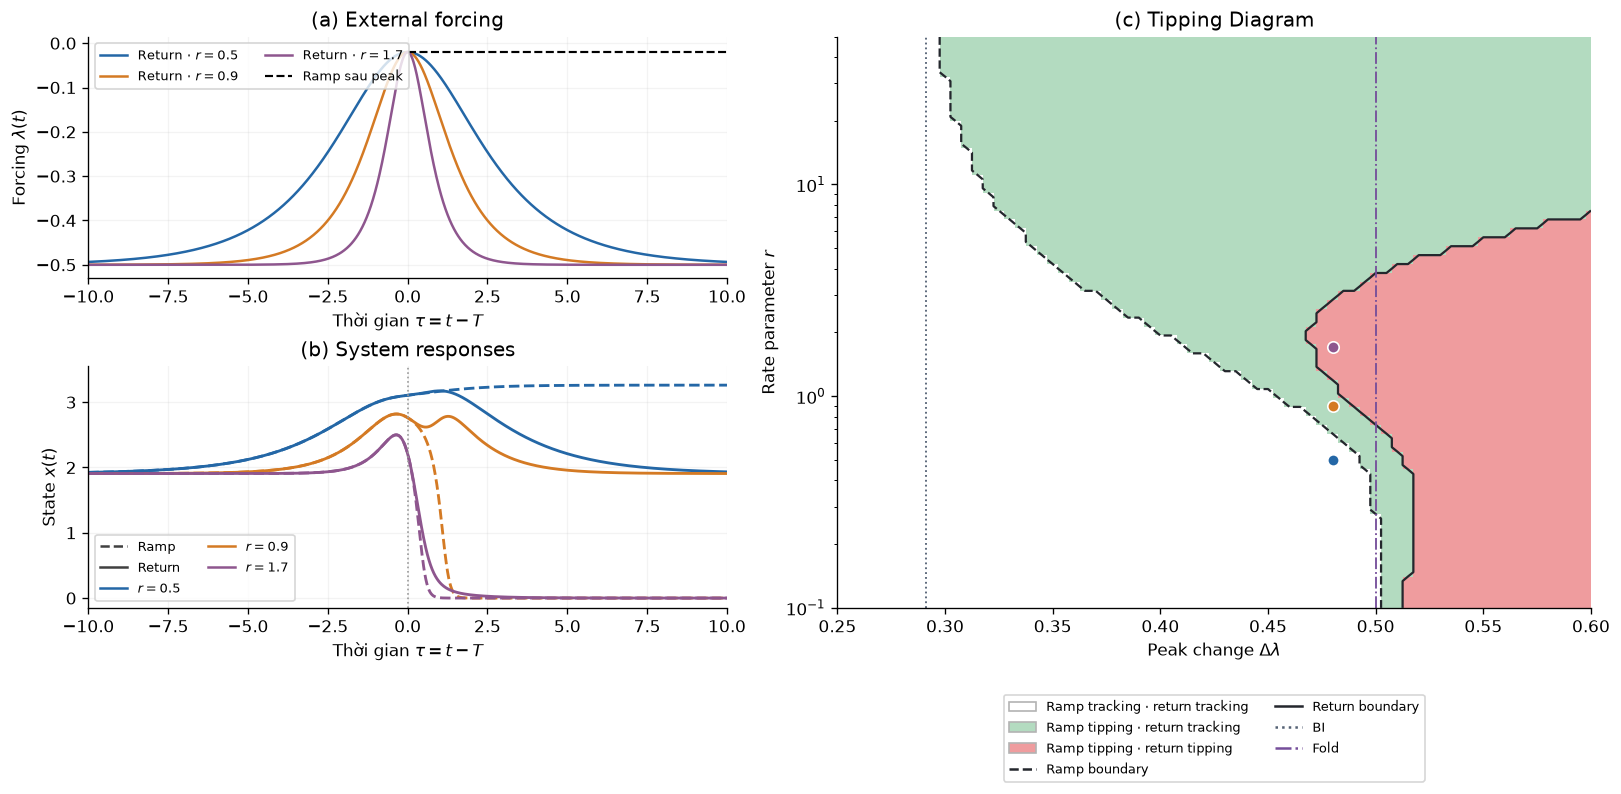

| Kết hợp outcomes | Số ô trong lưới |
|:---|---:|
| Ramp tracking · return tracking | 1,984 |
| Ramp tipping · return tracking | 1,771 |
| Ramp tipping · return tipping | 860 |
| Ramp tracking · return tipping | 0 |
| Unresolved | 0 |

In [37]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

REGION_COLORS = ("#ffffff", "#b3dbc0", "#ef9c9e", "#adbeeb", "#cbd0d6")
REGION_LABELS = ("Ramp tracking · return tracking", "Ramp tipping · return tracking",
                 "Ramp tipping · return tipping", "Ramp tracking · return tipping", "Unresolved")


def combined_outcome_grid(outcomes):
    ramp, pulse = outcomes
    combined = np.full(ramp.shape, 4, dtype=np.int8)
    resolved = (ramp >= 0) & (pulse >= 0)
    combined[resolved] = np.array([[0, 3], [1, 2]])[ramp[resolved], pulse[resolved]]
    return combined


def plot_tipping_diagram(ax, shifts, rates, outcomes):
    combined = combined_outcome_grid(outcomes)
    cmap = ListedColormap(REGION_COLORS)
    norm = BoundaryNorm(np.arange(-0.5, 5.5), cmap.N)
    ax.pcolormesh(shifts, rates, combined, shading="nearest", cmap=cmap, norm=norm)
    for values, linestyle in zip(outcomes, ("--", "-")):
        mask = np.ma.masked_less(values, 0)
        if mask.min() < 0.5 < mask.max():
            ax.contour(shifts, rates, mask, levels=[0.5], colors=["#24272d"],
                       linestyles=[linestyle], linewidths=1.35, corner_mask=False)
    ax.axvline(delta_lambda_bi, color="#546174", linestyle=":", linewidth=1.1)
    ax.axvline(-lambda_i, color="#754e9a", linestyle="-.", linewidth=1.1)
    for rate, color in zip(figure3_rates, figure3_colors):
        ax.scatter(figure3_shift, rate, c=color, edgecolors="white", s=47, zorder=6)
    ax.set(xlim=(shifts[0], shifts[-1]), ylim=(rates[0], rates[-1]), yscale="log",
           xlabel=r"Peak change $\Delta\lambda$", ylabel=r"Rate parameter $r$",
           title="(c) Tipping Diagram")
    handles = [
        Patch(facecolor=REGION_COLORS[k], edgecolor="0.7", label=REGION_LABELS[k])
        for k in np.unique(combined)
    ]
    handles += [
        Line2D([], [], color="#24272d", linestyle="--", label="Ramp boundary"),
        Line2D([], [], color="#24272d", linestyle="-", label="Return boundary"),
        Line2D([], [], color="#546174", linestyle=":", label="BI"),
        Line2D([], [], color="#754e9a", linestyle="-.", label="Fold"),
    ]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.50, -0.14), ncol=2)
    return combined


fig = plt.figure(figsize=(13.4, 6.5), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=(1, 1.18))
ax_force = fig.add_subplot(gs[0, 0])
ax_response = fig.add_subplot(gs[1, 0], sharex=ax_force)
ax_diagram = fig.add_subplot(gs[:, 1])
plot_figure3_forcing(ax_force)
plot_figure3_responses(ax_response)
combined_grid = plot_tipping_diagram(ax_diagram, shift_grid, rate_grid, outcomes_grid)
plt.show()

region_counts = ["| Kết hợp outcomes | Số ô trong lưới |", "|:---|---:|"]
for code, label in enumerate(REGION_LABELS):
    region_counts.append(f"| {label} | {np.count_nonzero(combined_grid == code):,} |")
display(Markdown("\n".join(region_counts)))

*Figure 3 tái tạo.* Biên ramp đứt tiến về fold khi $r$ giảm và về phía BI khi $r$ tăng. Return boundary liền gập lại gần fold, tạo vùng nơi reversal giúp tracking và vùng nơi cả hai profiles đều tipping. Ba điểm màu tại $\Delta\lambda=0.48$ tương ứng với (a,b). Ô màu biểu diễn kết quả trên lưới, nên biên nội suy có độ phân giải hữu hạn. Đường BI giải tích $0.29105339$ lớn hơn giá trị $0.29091797$ vẽ trong script tác giả khoảng $1.35\times10^{-4}$. Script gán trực tiếp giá trị đó. [Paper, Figure 3](../paper/23%20Rate-induced%20tipping%20in%20natural%20and%20human%20systems.pdf#page=6)

### 5.8. Multiple critical rates gần fold

**Additional experiment.** Chọn một overshoot từ lưới đã tính, ưu tiên lát cắt return có ít nhất ba thay đổi outcome. Tinh chỉnh từng bracket. Dùng một rate đại diện ở giữa mỗi dải outcome để xem hệ tiến vào vùng $\lambda>0$ bao lâu và vị trí state so với threshold sau khi các branches xuất hiện trở lại.

| $\Delta\lambda$ | Profile | Transition khi $r$ tăng | $\hat r_c$ | Bracket |
|---:|:---|:---|---:|---:|
| 0.515 | return | tipping → tracking | 0.140010 | [0.139997, 0.140023] |
| 0.515 | return | tracking → tipping | 0.439532 | [0.439490, 0.439574] |
| 0.515 | return | tipping → tracking | 4.233386 | [4.232985, 4.233787] |

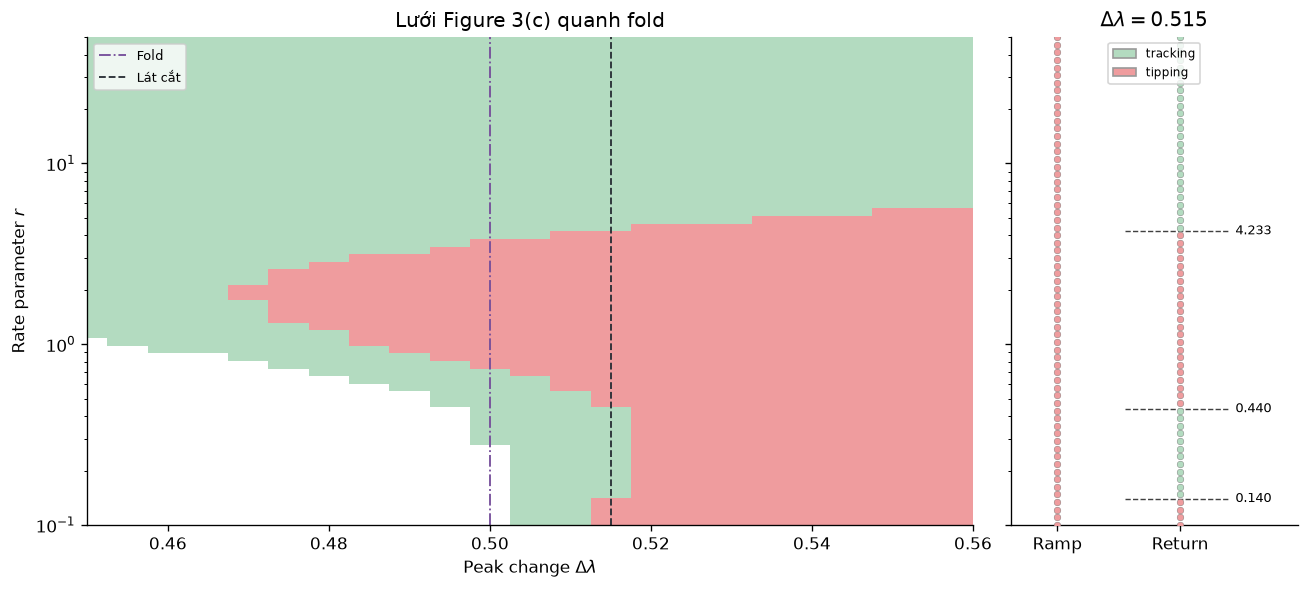

In [38]:
pulse_index = profiles.index("return")
overshoot_columns = np.flatnonzero(shift_grid > -lambda_i)
transition_counts = [
    len(transition_brackets(rate_grid, outcomes_grid[pulse_index, :, j]))
    for j in overshoot_columns
]
slice_index = overshoot_columns[int(np.argmax(transition_counts))]
slice_shift = shift_grid[slice_index]
slice_labels = outcomes_grid[pulse_index, :, slice_index]
slice_boundaries = refined_rate_slice(slice_shift, "return", rate_grid, slice_labels,
                                     **sweep_settings)
slice_critical_rates = np.array([np.sqrt(lo * hi) for lo, hi, _, _ in slice_boundaries])
slice_edges = np.r_[rate_grid[0], slice_critical_rates, rate_grid[-1]]
slice_rates = np.sqrt(slice_edges[:-1] * slice_edges[1:])

slice_rows = [r"| $\Delta\lambda$ | Profile | Transition khi $r$ tăng | $\hat r_c$ | Bracket |",
              "|---:|:---|:---|---:|---:|"]
slice_rows.extend(format_rate_row(slice_shift, "return", bracket) for bracket in slice_boundaries)
display(Markdown("\n".join(slice_rows)))
for low, high, left, right in slice_boundaries:
    for rate, label in ((low / 1.005, left), (high * 1.005, right)):
        outcome, _ = evaluate_forcing(*sweep_system, slice_shift, rate, "return",
                                      **strict_classifier_settings)
        assert OUTCOME_CODES[outcome] == label

fig, (ax_map, ax_slice) = plt.subplots(1, 2, figsize=(10.8, 4.8), sharey=True,
                                       gridspec_kw={"width_ratios": (3.7, 1.2)},
                                       layout="constrained")
near_fold = (shift_grid >= 0.45) & (shift_grid <= 0.56)
ax_map.pcolormesh(
    shift_grid[near_fold], rate_grid, combined_grid[:, near_fold], shading="nearest",
    cmap=ListedColormap(REGION_COLORS), norm=BoundaryNorm(np.arange(-0.5, 5.5), 5),
)
ax_map.axvline(-lambda_i, linestyle="-.", color="#754e9a", linewidth=1.1, label="Fold")
ax_map.axvline(slice_shift, linestyle="--", color="#282e35", linewidth=1.1, label="Lát cắt")
ax_map.set(xlabel=r"Peak change $\Delta\lambda$", ylabel=r"Rate parameter $r$",
           title="Lưới Figure 3(c) quanh fold", xlim=(0.45, 0.56), yscale="log",
           ylim=(rate_grid[0], rate_grid[-1]))
ax_map.legend(loc="upper left")
slice_colors = {-1: "#cbd0d6", 0: "#b3dbc0", 1: "#ef9c9e"}
for i, p in enumerate((0, 1)):
    for label, color in slice_colors.items():
        mask = outcomes_grid[p, :, slice_index] == label
        ax_slice.scatter(np.full(mask.sum(), i), rate_grid[mask], s=16, color=color,
                         edgecolors="0.45", linewidths=0.25, zorder=4)
for low, high, _, _ in slice_boundaries:
    critical = np.sqrt(low * high)
    ax_slice.hlines(critical, 0.55, 1.39, color="0.25", linestyle="--", linewidth=0.85)
    ax_slice.text(1.45, critical, f"{critical:.3f}", fontsize=8, va="center")
ax_slice.set(xlim=(-0.38, 1.96), xticks=[0, 1], xticklabels=["Ramp", "Return"],
             title=rf"$\Delta\lambda={slice_shift:.3f}$")
ax_slice.legend(handles=[
    Patch(facecolor=color, edgecolor="0.6", label=CODE_TO_OUTCOME[label])
    for label, color in slice_colors.items() if label in outcomes_grid[:, :, slice_index]
], loc="upper center", fontsize=7)
plt.show()

*Hình 5.1 · Additional experiment.* Đường đứng chỉ lát cắt sau fold. Mỗi marker ở khung phải là outcome đã tích phân tại một $r$ của lưới. Vạch ngang đánh dấu critical rate tìm được bằng refinement của return. Ramp nằm trên fold vĩnh viễn ở lát cắt này, còn return chỉ tạm vượt fold.

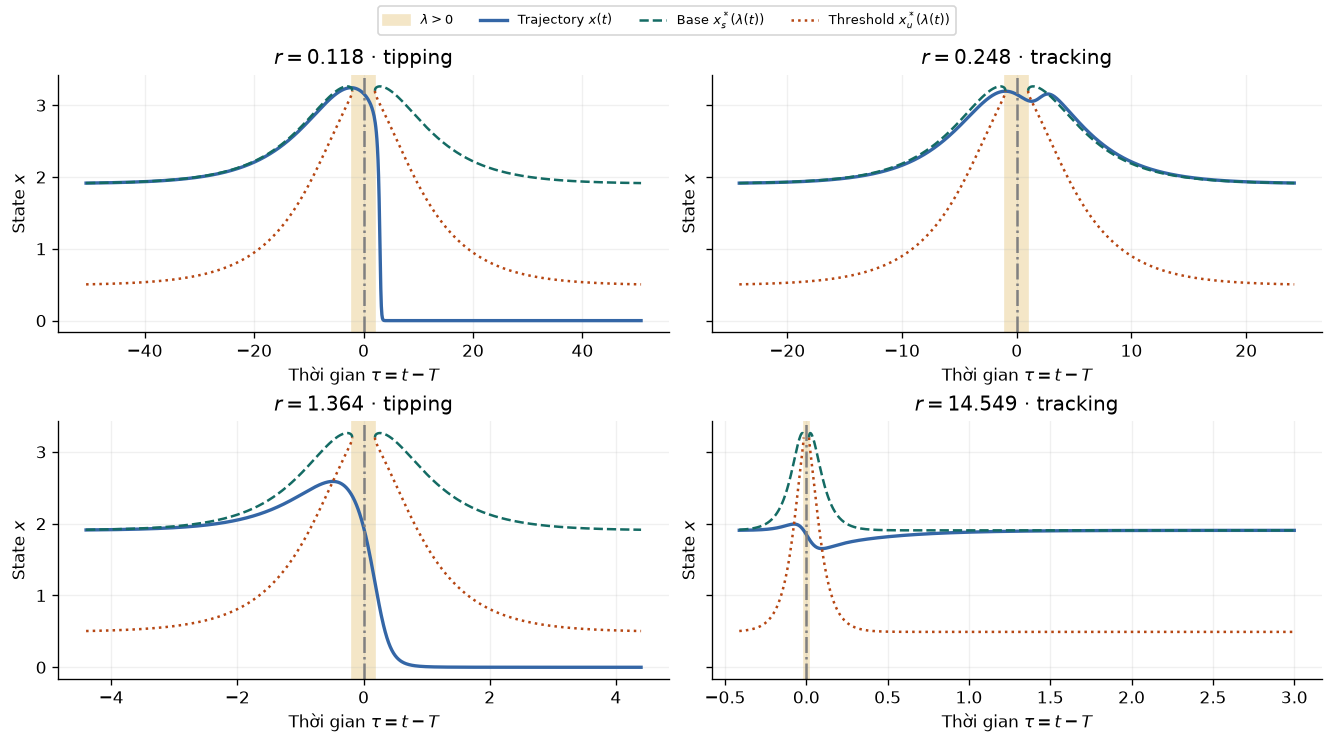

| $r$ | Thời gian $\lambda>0$ | $x(T)$ | $x(t_{\mathrm{exit}})-A$ | $x_{\mathrm{end}}$ | Outcome |
|---:|---:|---:|---:|---:|:---|
| 0.11833 | 4.12997 | 3.16296 | -0.41184 | -0.00000 | tipping |
| 0.24807 | 1.96993 | 3.15049 | -0.13561 | 1.90711 | tracking |
| 1.36408 | 0.35825 | 1.95058 | -2.01168 | -0.00000 | tipping |
| 14.54886 | 0.03359 | 1.84883 | -1.41322 | 1.90711 | tracking |

Chuỗi observed outcomes khi tăng rate · tipping → tracking → tipping → tracking.

In [39]:
slice_cases = {
    rate: evaluate_forcing(*sweep_system, slice_shift, rate, "return", dense_output=True,
                           **strict_classifier_settings)
    for rate in slice_rates
}
slice_sequence = [outcome for outcome, _ in slice_cases.values()]
known_sequence = ([CODE_TO_OUTCOME[slice_boundaries[0][2]]]
                  + [CODE_TO_OUTCOME[bracket[3]] for bracket in slice_boundaries]
                  if slice_boundaries else [])
if known_sequence:
    assert slice_sequence == known_sequence

fig, axes = plt.subplots((len(slice_cases) + 1) // 2, 2, sharey=True, squeeze=False,
                         figsize=(11, 3.05 * ((len(slice_cases) + 1) // 2)), layout="constrained")
diagnostics = [r"| $r$ | Thời gian $\lambda>0$ | $x(T)$ | $x(t_{\mathrm{exit}})-A$ | $x_{\mathrm{end}}$ | Outcome |",
               "|---:|---:|---:|---:|---:|:---|"]
for ax, (rate, (outcome, run)) in zip(axes.flat, slice_cases.items()):
    duration = 2.0 * np.arccosh(slice_shift / -lambda_i) / rate
    tau_plot = np.unique(np.r_[np.linspace(-6.0 / rate, max(6.0 / rate, 3.0), 1001),
                               -duration / 2, 0, duration / 2])
    lam = external_forcing(tau_plot, lambda_i, slice_shift, rate, 0.0, "return")
    x = sample_forced(run, tau_plot)
    base, threshold = instantaneous_branches(lam, A_paper, s_paper)
    ax.axvspan(-duration / 2, duration / 2, color="#f4e6c7", label=r"$\lambda>0$")
    plot_state_and_branches(ax, tau_plot, x, base, threshold)
    ax.axvline(0, color="0.5", linestyle="-.")
    ax.set_title(f"$r={rate:.3f}$ · {outcome}")
    exit_gap = sample_forced(run, duration / 2) - A_paper
    diagnostics.append(f"| {rate:.5f} | {duration:.5f} | {run['x_peak']:.5f} "
                       f"| {exit_gap:+.5f} | {run['x_end']:.5f} | {outcome} |")
for ax in list(axes.flat)[len(slice_cases):]:
    ax.axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=4)
plt.show()
display(Markdown("\n".join(diagnostics)))
display(Markdown("Chuỗi observed outcomes khi tăng rate · " + " → ".join(slice_sequence) + "."))

*Hình 5.2 · Additional experiment.* Trên lát cắt có ba transitions, ở rate nhỏ nhất hệ vượt fold đủ lâu để mất state đang theo. Ở rate tiếp theo, return làm xuất hiện lại nhánh hút kịp thời để hồi phục (**safe overshoot**). Rate trung gian cao hơn làm state tụt đủ xa khỏi moving base để nằm dưới threshold khi nhánh đẩy trở lại (**tracking failure**). Với impulse rất nhanh, state vẫn thấp hơn threshold ngay khi nhánh trở lại nhưng threshold lùi đủ nhanh để hệ phục hồi về base state. Bảng dùng $t_{\mathrm{exit}}$ là thời điểm $\lambda$ đi từ dương về $0$, khi hai nhánh gặp tại $x=A$.

### 5.9. Kết luận và phạm vi kiểm chứng

Critical rates thay đổi theo forcing magnitude và profile. BI cho ngưỡng hình học mà ramp nhanh có thể tiến tới, còn fold quyết định mất base state khi ramp vượt nó vĩnh viễn. Symmetric return thêm thời gian vượt fold và tốc độ phục hồi threshold vào bài toán. Điều này cho phép nhiều critical rates ở một magnitude và chỉ lộ rõ khi quét hệ thống cả hai tham số.

**Points of return** là các điểm trong lưới mà ramp tipping và symmetric return tracking. **Points of no return** là các điểm mà cả hai profile đã thử đều tipping. Ý nghĩa này gắn với cùng nhánh đi, thời điểm quay ở peak, symmetry của impulse và mô hình đang xét. Một reversal bắt đầu lúc khác hoặc có rate chiều về khác cần được thử riêng.

**Đối chiếu và giới hạn.** Figure 2 và Figure 3(a,b) dùng đúng tham số công bố, với adaptive LSODA và trục có giá trị số. Max trajectory differences do thay tolerance được báo ở từng module. Figure 3(c) tính độc lập trên cùng dải hiển thị, với contour nội suy từ lưới và brackets kiểm chứng ở các lát cắt đại diện. Các lưới và brackets có độ phân giải hữu hạn, nên vùng rất hẹp hoặc điểm sát separatrix có thể cần thêm refinement. Khi chạy lại plots, dùng các file NPZ đã lưu hoặc tính lại bằng các cell sweep.

## Tóm tắt kết quả · Tilted saddle-node model

- **Modules 1–3.** Ramp giữ mức mới, return quay về mức đầu. $\max|\dot\lambda|=r|\Delta\lambda|/2$. Tilt đổi hình học basins, fold vẫn tại $\lambda=0$ và BI bắt đầu ở $\Delta\lambda_{\mathrm{BI}}\approx0.291053$ với tham số chính.
- **Module 4 · Figure 2.** Ramp chậm vượt fold và đi qua $x=A/2$ khoảng $9.52$ đơn vị thời gian sau crossing. Ở cả ramp tăng dưới fold và ramp giảm rời fold, $r=1$ tracking và $r=3$ tipping.
- **Module 5 · Figure 3.** Với $\Delta\lambda=0.48$, các cặp ramp/return lần lượt là tracking/tracking, tipping/tracking và tipping/tipping tại $r=0.5,\ 0.9,\ 1.7$. Với overshoot $\Delta\lambda=0.515$, return có ba critical rates gần $0.140$, $0.440$ và $4.233$, cho chuỗi tipping → tracking → tipping → tracking.

## Module 6 — Plant–Herbivore Model · Figures 4(a–c), 5(a)

### 6.1–6.2. Từ mô hình sinh thái tới hệ hai chiều

**Mục tiêu.** Dùng nullclines, eigenvalues và frozen basins để xác định edge state trước khi thay đổi forcing. Scheffer et al. (2008) cung cấp mô hình biomass. O’Keeffe & Wieczorek (2020) dùng thay đổi môi trường để phân tích tipping. Ritchie et al. (2023) đi theo một đường thẳng trong không gian plant growth và herbivore mortality. [Scheffer et al.](https://doi.org/10.1007/s10021-007-9118-8) · [O’Keeffe & Wieczorek](https://doi.org/10.1137/19M1242884) · [Appendix A3](https://doi.org/10.5194/esd-14-669-2023)

**Original reproduction · Eq. (A4–A6).** $P,H$ là plant biomass và herbivore biomass trên một đơn vị diện tích. $\rho P-CP^2$ là logistic plant growth, $Hg(P)$ là lượng plant biomass bị tiêu thụ và $E e^{-bP}$ điều chỉnh chuyển hóa thức ăn thành herbivore biomass. Herbivore mất biomass theo $mH$.
$$
\begin{aligned}
\dot P&=\rho P-CP^2-Hg(P),\\
\dot H&=H(G(P)-m),\\
g(P)&=c_{\max}\frac{P^2}{P^2+a^2}e^{-b_cP},\qquad G(P)=E e^{-bP}g(P).
\end{aligned}
$$

Functional response tăng ở $P$ nhỏ và giảm khi exponential inhibition chi phối. Do đó cùng một $m$ có thể cắt $G(P)$ tại hai mức plant biomass, tạo hai coexistence equilibria nếu herbivore biomass tại giao điểm dương.

| Đại lượng | Giá trị | Đơn vị | Nguồn |
|---|---:|---|---|
| $P,H$ | state | $\mathrm{g\,m^{-2}}$ | Appendix A3 |
| $C$ | 0.02 | $\mathrm{m^2\,g^{-1}\,d^{-1}}$ | ecoModel_BI.m |
| $E$ | 0.4 | không thứ nguyên | ecoModel_BI.m |
| $b,b_c$ | 0.025 mỗi hệ số | $\mathrm{m^2\,g^{-1}}$ | ecoModel_BI.m |
| $c_{\max}$ | 1 | $\mathrm{d^{-1}}$ | ecoModel_BI.m |
| $a$ | 10 | $\mathrm{g\,m^{-2}}$ | ecoModel_BI.m |
| $\rho_-,m_-$ | 0.5, 0.125 | $\mathrm{d^{-1}}$ | Appendix A3 |
| $\Delta\rho$ Figure 4 | 0.1 | $\mathrm{d^{-1}}$ | Appendix A3 |
| $dm/d\rho$ | $1/30$ | không thứ nguyên | Eq. (A8), script sweep |
| $\Delta\rho_{\mathrm{Fold}},\Delta m_{\mathrm{Fold}}$ | 0.1966, 0.00655 | $\mathrm{d^{-1}}$ | Eq. (A10), số làm tròn |
| $T,r$ Figure 4 | 200 và $0.03,\ \approx0.0453,\ 0.1$ | $\mathrm{d}$ và $\mathrm{d^{-1}}$ | Appendix A3 |

Nguồn của sáu tham số cố định và cách triển khai path. [ecoModel_BI.m](https://github.com/hassanalkhayuon/rtippingreview/blob/main/ecoModel_BI.m) · [tipping_daiagram_ecoModel_nu.m](https://github.com/hassanalkhayuon/rtippingreview/blob/main/tipping_daiagram_ecoModel_nu.m)

### 6.3–6.4. Frozen equilibria, Jacobian và numerical integration

**Additional Mathematical Analysis.** Hai biên $P=0$ và $H=0$ là bất biến. Trong miền dương, plant nullcline là $H=P(\rho-CP)/g(P)$ và herbivore nullcline là $G(P)=m$. Các boundary equilibria là $(0,0)$ và $(\rho/C,0)$. Với mỗi nghiệm dương của $G(P)=m$, thay vào plant nullcline và chỉ giữ nghiệm $H>0$. Từ $G'(P)=0$, vị trí cực đại duy nhất thỏa $P(P^2+a^2)(b+b_c)=2a^2$. Khi giao điểm kép ở mức $H>0$, hai nhánh coexistence gặp tại fold.

$$
J(P,H)=
\begin{pmatrix}
\rho-2CP-Hg'(P)&-g(P)\\
H\,E e^{-bP}[g'(P)-bg(P)]&G(P)-m
\end{pmatrix}.
$$

**Phương pháp số dùng chung.** Tích phân bằng solve_ivp với LSODA và Jacobian, tách các đoạn trước/sau peak như Module 4. Gom nghiệm theo hai tọa độ bằng khoảng cách $\|(\mathbf{x}-\mathbf{x}^*)/\mathbf{s}\|_2$, với $\mathbf{s}$ là scales cố định được công bố trong code. Tracking và tipping yêu cầu đúng một attracting equilibrium nằm trong lân cận $2\times10^{-5}$ của state đã scale. Nếu chưa phân loại được, tăng relaxation horizon gấp ba. Trạng thái gần saddle, periodic orbit hoặc còn xa cả hai attractors giữ nhãn **unresolved**. Toạ độ nhỏ âm trong tolerance được kiểm tra như sai số tích phân gần biên bất biến.

In [40]:
from functools import lru_cache
from scipy.optimize import root
from scipy.spatial import cKDTree
from numpy.polynomial import Polynomial
import json


def stability_2d(jac):
    spectrum = np.linalg.eigvals(jac)
    real = spectrum.real
    if np.any(np.abs(real) < 1e-10):
        return "nonhyperbolic", spectrum
    if np.all(real < 0.0):
        return "stable", spectrum
    if np.all(real > 0.0):
        return "repelling", spectrum
    return "saddle", spectrum


def integrate_2d(rhs, interval, x_initial, *, jac=None, rtol=1e-9, atol=1e-11,
                 max_step=np.inf, dense_output=False, method="LSODA", events=None):
    options = {"jac": jac} if method == "LSODA" else {}
    sol = solve_ivp(rhs, interval, x_initial, method=method, rtol=rtol, atol=atol,
                    max_step=max_step, dense_output=dense_output, events=events, **options)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol


def frozen_2d(model, env, x_initial, horizon, **options):
    field, jac, _ = model
    return integrate_2d(lambda t, x: field(x, env), (0.0, horizon), x_initial,
                        jac=lambda t, x: jac(x, env), **options)


def classify_2d(state, targets, scale, tolerance=2e-5):
    """Đích phải là attracting equilibrium và state phải vào lân cận của đúng một đích."""
    within = [label for label, point in targets.items()
              if np.linalg.norm((np.asarray(state) - point) / scale) <= tolerance]
    return within[0] if len(within) == 1 else "unresolved"


def forced_2d(model, x_initial, peak, rate, profile, *, T=None, initial_tail=1e-5,
              return_tail=1e-9, relaxation, rtol=1e-9, atol=1e-11, rate_step=0.5,
              dense_output=False):
    """Tích phân với env=peak*a(r*tau), timescale và forcing profile dùng lại từ Module 1."""
    field, jac, _ = model
    T = minimum_peak_time(rate, initial_tail) if T is None else T
    tail = minimum_peak_time(rate, return_tail) if profile == "return" else 0.0
    intervals = [(-T, 0.0, rate_step / rate)]
    if profile == "return":
        intervals.append((0.0, tail, rate_step / rate))
    intervals.append((tail, tail + relaxation, np.inf))

    def env(tau):
        return external_forcing(tau, 0.0, peak, rate, 0.0, profile)

    state = x_initial
    segments = []
    for left, right, step in intervals:
        segment = integrate_2d(
            lambda time, x: field(x, env(time)), (left, right), state,
            jac=lambda time, x: jac(x, env(time)), max_step=step,
            rtol=rtol, atol=atol, dense_output=dense_output,
        )
        segments.append(segment)
        state = segment.y[:, -1]
    return {"segments": segments, "T": T, "x_peak": segments[0].y[:, -1],
            "x_end": state, "env": env, "profile": profile, "end": tail + relaxation}


def sample_2d(run, times):
    times = np.atleast_1d(times)
    if np.any(times < -run["T"]) or np.any(times > run["end"]):
        raise ValueError("Thời điểm nằm ngoài khoảng tích phân.")
    values = np.empty((2, times.size))
    for segment in run["segments"]:
        if segment.sol is None:
            raise ValueError("Cần dense_output=True để lấy mẫu.")
        mask = (times >= segment.t[0]) & (times <= segment.t[-1])
        values[:, mask] = segment.sol(times[mask])
    return values


def outcome_2d(run, model, peak, scale):
    end_env = peak if run["profile"] == "ramp" else 0.0
    if abs(run["env"](run["end"]) - end_env) > 1e-7 * max(1.0, peak):
        return "unresolved"
    return classify_2d(run["x_end"], model[2](end_env), scale)


def extend_2d(run, model, extra_time, *, rtol, atol, dense_output):
    field, jac, _ = model
    env = run["env"]
    end = run["end"] + extra_time
    solution = integrate_2d(
        lambda time, state: field(state, env(time)), (run["end"], end), run["x_end"],
        jac=lambda time, state: jac(state, env(time)), rtol=rtol, atol=atol,
        dense_output=dense_output,
    )
    return {**run, "segments": [*run["segments"], solution], "end": end,
            "x_end": solution.y[:, -1]}


def evaluate_2d(model, x_initial, peak, rate, profile, scale, *, relaxation,
                dense_output=False, max_relaxation=None, **settings):
    run = forced_2d(model, x_initial, peak, rate, profile, relaxation=relaxation,
                    dense_output=dense_output, **settings)
    outcome = outcome_2d(run, model, peak, scale)
    final_relaxation = max_relaxation or 3 * relaxation
    time_now = relaxation
    for deadline in sorted({min(3 * relaxation, final_relaxation), final_relaxation}):
        if outcome != "unresolved" or deadline <= time_now:
            break
        run = extend_2d(run, model, deadline - time_now,
                        rtol=settings.get("rtol", 1e-9), atol=settings.get("atol", 1e-11),
                        dense_output=dense_output)
        time_now = deadline
        outcome = outcome_2d(run, model, peak, scale)
    return outcome, run

In [41]:
eco_parameters = {"C": 0.02, "E": 0.4, "b": 0.025, "c_max": 1.0, "a": 10.0, "b_c": 0.025,
                  "rho_0": 0.5, "m_0": 0.125, "path_slope": 1 / 30, "rho_norm": 0.1966,
                  "m_norm": 0.00655}
eco_scale = np.array([20.0, 15.0])


def eco_path(env, slope=eco_parameters["path_slope"]):
    delta_rho = eco_parameters["rho_norm"] * np.asarray(env)
    return (eco_parameters["rho_0"] + delta_rho,
            eco_parameters["m_0"] + slope * delta_rho)


def herbivory(P):
    a, b_c, c_max = (eco_parameters[key] for key in ("a", "b_c", "c_max"))
    return c_max * P**2 / (P**2 + a**2) * np.exp(-b_c * P)


def herbivory_prime(P):
    a, b_c, c_max = (eco_parameters[key] for key in ("a", "b_c", "c_max"))
    square_sum = P**2 + a**2
    return c_max * np.exp(-b_c * P) * (2 * P * a**2 / square_sum**2 - b_c * P**2 / square_sum)


def herbivore_gain(P):
    return eco_parameters["E"] * np.exp(-eco_parameters["b"] * P) * herbivory(P)


def eco_field(state, env, slope=eco_parameters["path_slope"]):
    P, H = state
    rho, m = eco_path(env, slope)
    return np.array([rho * P - eco_parameters["C"] * P**2 - H * herbivory(P),
                     H * (herbivore_gain(P) - m)])


def eco_jac(state, env, slope=eco_parameters["path_slope"]):
    P, H = state
    rho, m = eco_path(env, slope)
    g = herbivory(P)
    dg = herbivory_prime(P)
    b = eco_parameters["b"]
    return np.array([
        [rho - 2 * eco_parameters["C"] * P - H * dg, -g],
        [H * eco_parameters["E"] * np.exp(-b * P) * (dg - b * g),
         herbivore_gain(P) - m],
    ])


eco_P_max = brentq(
    lambda P: 2 * eco_parameters["a"]**2 - (eco_parameters["b"] + eco_parameters["b_c"])
    * P * (P**2 + eco_parameters["a"]**2), 0, 100,
)
eco_m_fold = herbivore_gain(eco_P_max)
eco_fold = ((eco_m_fold - eco_parameters["m_0"]) / eco_parameters["path_slope"]
            / eco_parameters["rho_norm"])


@lru_cache(maxsize=2048)
def eco_equilibria(env, slope=eco_parameters["path_slope"]):
    rho, m = eco_path(env, slope)
    C = eco_parameters["C"]
    states = {"Extinction": np.zeros(2), "Plant-only": np.array([rho / C, 0.0])}
    if m < eco_m_fold:
        func = lambda P: herbivore_gain(P) - m
        plants = (brentq(func, 0, eco_P_max), brentq(func, eco_P_max, 200))
        for P, name in zip(plants, ("Coexistence", "Upper-P coexistence")):
            H = (rho * P - C * P**2) / herbivory(P)
            if H > 0.0:
                states[name] = np.array([P, H])
    return states


@lru_cache(maxsize=2048)
def eco_targets(env, slope=eco_parameters["path_slope"]):
    states = eco_equilibria(env, slope)
    return {label: states[name] for label, name in (("tracking", "Coexistence"),
                                                    ("tipping", "Plant-only"))
            if name in states and stability_2d(eco_jac(states[name], env, slope))[0] == "stable"}


eco_model = (eco_field, eco_jac, eco_targets)
eco_peak4 = 0.1 / eco_parameters["rho_norm"]
eco_initial = eco_targets(0.0)["tracking"]

In [42]:
def centered_jacobian(field, point, env, step=1e-6):
    offsets = np.eye(2) * step
    return np.column_stack([
        (field(point + offset, env) - field(point - offset, env)) / (2 * step)
        for offset in offsets
    ])


def equilibrium_table(cases, get_jac, transform=lambda x: x):
    rows = [r"| Forcing | Equilibrium | State coordinates | Eigenvalues | Stability |",
            "|---:|:---|:---|:---|:---|"]
    for env, states in cases:
        for name, point in states.items():
            stability, spectrum = stability_2d(get_jac(point, env))
            coords = ", ".join(f"{x:.5f}" for x in transform(point))
            eigenvalues = ", ".join(f"{x:.5g}" for x in spectrum)
            rows.append(f"| {env:.6g} | {name} | ({coords}) | {eigenvalues} | {stability} |")
    display(Markdown("\n".join(rows)))


eco_levels = (0.0, eco_peak4)
for env in eco_levels:
    for point in eco_equilibria(env).values():
        np.testing.assert_allclose(eco_field(point, env), np.zeros(2), atol=1e-11)
        np.testing.assert_allclose(
            eco_jac(point, env), centered_jacobian(eco_field, point, env), atol=5e-9,
        )
    assert set(eco_targets(env)) == {"tracking", "tipping"}
    saddle = eco_equilibria(env)["Upper-P coexistence"]
    assert stability_2d(eco_jac(saddle, env))[0] == "saddle"
equilibrium_table([(env, eco_equilibria(env)) for env in eco_levels], eco_jac)

| Forcing | Equilibrium | State coordinates | Eigenvalues | Stability |
|---:|:---|:---|:---|:---|
| 0 | Extinction | (0.00000, 0.00000) | 0.5, -0.125 | saddle |
| 0 | Plant-only | (25.00000, 0.00000) | -0.5, -0.026205 | stable |
| 0 | Coexistence | (10.68992, 7.49432) | -0.059123+0.1038j, -0.059123-0.1038j | stable |
| 0 | Upper-P coexistence | (17.74968, 5.28461) | -0.24547, 0.029951 | saddle |
| 0.508647 | Extinction | (0.00000, 0.00000) | 0.6, -0.12833 | saddle |
| 0.508647 | Plant-only | (30.00000, 0.00000) | -0.6, -0.048006 | stable |
| 0.508647 | Coexistence | (11.55248, 9.95255) | -0.035807+0.10923j, -0.035807-0.10923j | stable |
| 0.508647 | Upper-P coexistence | (16.44152, 9.21281) | -0.15569, 0.063036 | saddle |

Coexistence có cặp eigenvalues với phần thực âm ở cả hai mức. Plant-only vẫn hút và saddle coexistence có một stable direction và một unstable direction. Extinction cũng là saddle nhưng nằm ở góc miền vật lý. Giao điểm ở phía $P$ lớn là edge state cần khảo sát trong phần phase plane bên dưới.

### 6.5. Basin mapping và stable manifold

**Additional Experiments.** Dùng hai phép tính độc lập. (1) Tích phân một lưới initial conditions bằng RK4 theo cùng bước, phân loại theo khoảng cách tới các frozen attractors, kiểm tra vài điểm lưới bằng LSODA với tolerance chặt. (2) Từ saddle coexistence, đặt hai initial points cách $\varepsilon$ theo hai chiều của stable eigenvector và tích phân ngược tới mép miền vẽ. Khi tiến ngược thời gian, stable direction trở thành direction đẩy, giúp lần theo cả hai nhánh của stable manifold. Giảm $\varepsilon$ và kiểm tra hai điểm ở hai phía đường bằng forward integration. Sự phù hợp của hai phép tính chỉ xác nhận basin boundary trong miền khảo sát.

In [43]:
def rk4_frozen_grid(field, env, starts, horizon, max_step):
    """Tính ensemble frozen trajectories theo lưới, dùng RK4 cùng bước thời gian."""
    steps = int(np.ceil(horizon / max_step))
    dt = horizon / steps
    state = np.asarray(starts, dtype=float).copy()
    for _ in range(steps):
        k1 = field(state, env)
        k2 = field(state + 0.5 * dt * k1, env)
        k3 = field(state + 0.5 * dt * k2, env)
        k4 = field(state + dt * k3, env)
        state += (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
    return state


def basin_map_2d(model, env, x_axis, y_axis, scale, horizon, max_step):
    x, y = np.meshgrid(x_axis, y_axis)
    terminal = rk4_frozen_grid(model[0], env, np.stack([x, y]), horizon, max_step)
    labels = np.full(x.shape, OUTCOME_CODES["unresolved"], dtype=np.int8)
    for name, point in model[2](env).items():
        distance = np.linalg.norm((terminal - point[:, None, None]) / scale[:, None, None], axis=0)
        labels[distance <= 2e-5] = OUTCOME_CODES[name]
    return labels


def saddle_manifold(model, env, saddle, bounds, *, epsilon, backward_time, max_step):
    """Tích phân backward qua stable eigendirection ở hai phía, tới mép khung."""
    field, jac, _ = model
    eigenvalues, eigenvectors = np.linalg.eig(jac(saddle, env))
    assert sum(eigenvalues.real < 0) == 1 and sum(eigenvalues.real > 0) == 1
    direction = eigenvectors[:, np.argmin(eigenvalues.real)].real
    direction /= np.linalg.norm(direction)
    lower, upper = np.asarray(bounds[0]), np.asarray(bounds[1])

    def exit_domain(time, state):
        return min(np.min(state - lower), np.min(upper - state))

    exit_domain.terminal, exit_domain.direction = True, -1
    paths = []
    for sign in (-1, 1):
        solution = integrate_2d(
            lambda time, x: -field(x, env), (0.0, backward_time),
            saddle + sign * epsilon * direction, max_step=max_step,
            rtol=1e-10, atol=1e-12, method="DOP853", events=exit_domain, dense_output=True,
        )
        paths.append(solution.sol(np.linspace(0.0, solution.t[-1], 801)).T)
    return np.vstack([paths[0][::-1], saddle, paths[1]])


def basin_threshold(model, initial, bracket, scale, horizon, iterations=20):
    def endpoint_label(env):
        sol = frozen_2d(model, env, initial, horizon)
        return OUTCOME_CODES[classify_2d(sol.y[:, -1], model[2](env), scale)]

    low, high = bracket
    assert endpoint_label(low) == 0 and endpoint_label(high) == 1
    for _ in range(iterations):
        middle = (low + high) / 2
        label = endpoint_label(middle)
        if label == 0:
            low = middle
        elif label == 1:
            high = middle
        else:
            break
    return low, high


def application_rate_boundary(model, initial, peak, bracket, scale, settings):
    def label(rate):
        outcome, _ = evaluate_2d(model, initial, peak, rate, "ramp", scale, **settings)
        return OUTCOME_CODES[outcome]

    low, high = bracket
    assert (label(low), label(high)) == (0, 1)
    return refine_rate_bracket(label, (low, high, 0, 1), relative_width=2e-8)

In [44]:
def frozen_outcome(model, env, initial, scale, horizon):
    sol = frozen_2d(model, env, initial, horizon, rtol=1e-10, atol=1e-12)
    return classify_2d(sol.y[:, -1], model[2](env), scale)


def validate_basin_points(model, env, x_axis, y_axis, labels, scale, horizon):
    probes = [(len(y_axis) // 5, len(x_axis) // 5),
              (len(y_axis) * 4 // 5, len(x_axis) // 5),
              (len(y_axis) // 5, len(x_axis) * 4 // 5),
              (len(y_axis) * 4 // 5, len(x_axis) * 4 // 5)]
    comparisons = []
    for row, col in probes:
        outcome = frozen_outcome(model, env, [x_axis[col], y_axis[row]], scale, horizon)
        comparisons.append(OUTCOME_CODES[outcome] == labels[row, col])
    return sum(comparisons), len(comparisons)


basin_palette = ListedColormap(["#d0d3d7", "#e3f1e8", "#f6dfdf"])
basin_norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], basin_palette.N)
basin_legend = [
    Patch(color="#e3f1e8", label="Basin base state"),
    Patch(color="#f6dfdf", label="Basin alternative state"),
    Patch(color="#d0d3d7", label="Unresolved"),
]


def phase_background(ax, x_axis, y_axis, labels, field, env, transform=lambda x: x):
    ax.pcolormesh(transform(x_axis), transform(y_axis), labels, shading="nearest",
                  cmap=basin_palette, norm=basin_norm)
    dx, dy = field(np.meshgrid(x_axis, y_axis), env)
    ax.streamplot(transform(x_axis), transform(y_axis), dx, dy,
                  color="#81919a", density=0.66, linewidth=0.55, arrowsize=0.65)


def plot_frozen_examples(ax, model, env, starts, horizon, transform=lambda x: x):
    for k, initial in enumerate(starts):
        path = frozen_2d(model, env, initial, horizon)
        ax.plot(*transform(path.y), color="#3e6688", alpha=0.85, lw=1.25,
                label="Frozen trajectory" if k == 0 else None)
        ax.scatter(*transform(path.y[:, 0]), s=21, c="#3e6688", marker=">")


eco_P_grid = np.linspace(5, 33, 75)
eco_H_grid = np.linspace(0, 14, 65)
eco_bounds = ((eco_P_grid[0], eco_H_grid[0]), (eco_P_grid[-1], eco_H_grid[-1]))
eco_basins, eco_manifolds = {}, {}
for env in eco_levels:
    labels = basin_map_2d(eco_model, env, eco_P_grid, eco_H_grid, eco_scale, 650, 0.25)
    eco_basins[env] = labels
    assert validate_basin_points(eco_model, env, eco_P_grid, eco_H_grid,
                                 labels, eco_scale, 650) == (4, 4)
    saddle = eco_equilibria(env)["Upper-P coexistence"]
    curve_options = {"backward_time": 650, "max_step": 1.0}
    boundary = saddle_manifold(eco_model, env, saddle, eco_bounds,
                               epsilon=2e-5, **curve_options)
    tightened = saddle_manifold(eco_model, env, saddle, eco_bounds,
                                epsilon=5e-6, **curve_options)
    eco_manifolds[env] = tightened
    center = tightened[np.argmin(np.abs(tightened[:, 0] - 13.0))]
    tangent = eco_field(center, env)
    normal = np.array([-tangent[1], tangent[0]]) / np.linalg.norm(tangent)
    assert cKDTree(boundary).query(center)[0] < 0.08
    assert {frozen_outcome(eco_model, env, center + sign * 0.14 * normal, eco_scale, 900)
            for sign in (-1, 1)} == {"tracking", "tipping"}
display(Markdown("Kiểm tra hai phía stable manifold cho hai attractors khác nhau tại mỗi "
                 "mức forcing. Tám điểm kiểm tra trên basin maps khớp tích phân LSODA."))

Kiểm tra hai phía stable manifold cho hai attractors khác nhau tại mỗi mức forcing. Tám điểm kiểm tra trên basin maps khớp tích phân LSODA.

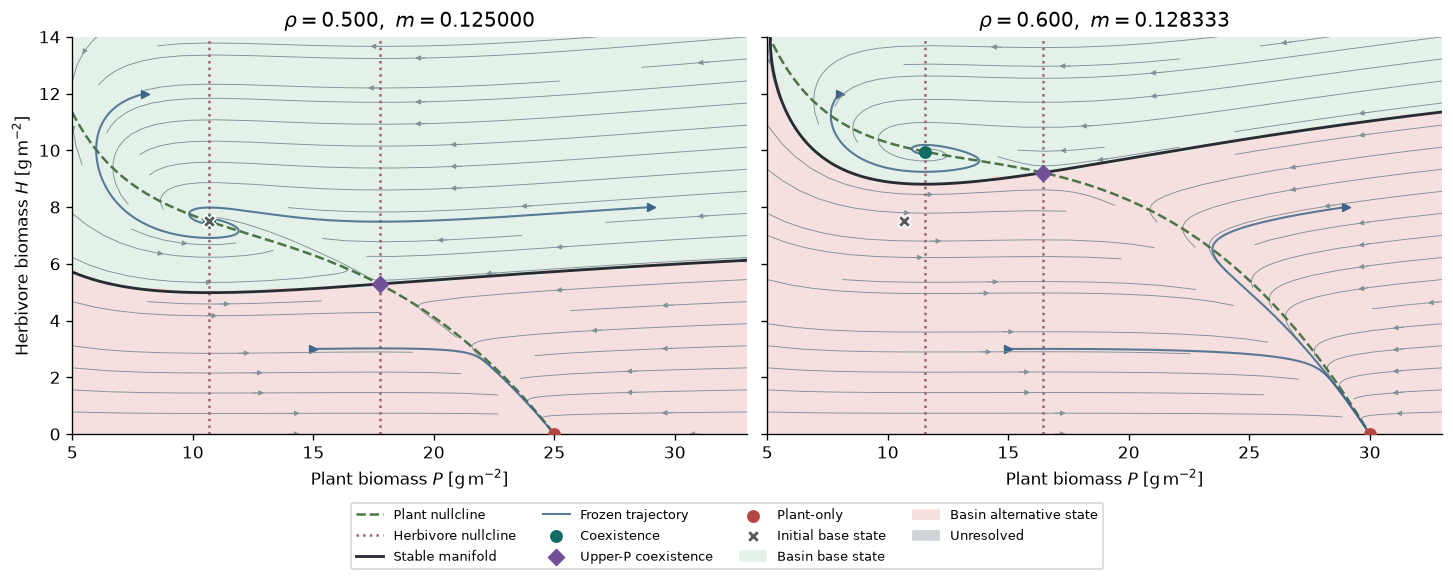

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharex=True, sharey=True,
                         layout="constrained")
for ax, env in zip(axes, eco_levels):
    phase_background(ax, eco_P_grid, eco_H_grid, eco_basins[env], eco_field, env)
    rho, m = eco_path(env)
    P_line = np.linspace(eco_P_grid[0], rho / eco_parameters["C"], 400)
    H_line = P_line * (rho - eco_parameters["C"] * P_line) / herbivory(P_line)
    ax.plot(P_line, H_line, color="#4c7446", linestyle="--", label="Plant nullcline")
    states = eco_equilibria(env)
    for k, name in enumerate(("Coexistence", "Upper-P coexistence")):
        ax.axvline(states[name][0], color="#986374", linestyle=":",
                   label="Herbivore nullcline" if k == 0 else None)
    ax.plot(*eco_manifolds[env].T, color="#282b32", lw=1.7, label="Stable manifold")
    plot_frozen_examples(ax, eco_model, env, [(8, 12), (15, 3), (29, 8)], 180)
    for name, marker, color in (("Coexistence", "o", "#146b64"),
                                ("Upper-P coexistence", "D", "#725097"),
                                ("Plant-only", "o", "#b64643")):
        ax.scatter(*states[name], marker=marker, color=color, s=45, zorder=6, label=name)
    ax.scatter(*eco_initial, color="0.35", edgecolor="white", s=60, marker="X", zorder=7,
               label="Initial base state")
    ax.set(xlim=(eco_P_grid[0], eco_P_grid[-1]), ylim=(0, 14),
           xlabel=r"Plant biomass $P$ [$\mathrm{g\,m^{-2}}$]",
           title=rf"$\rho={rho:.3f},\ m={m:.6f}$")
axes[0].set_ylabel(r"Herbivore biomass $H$ [$\mathrm{g\,m^{-2}}$]")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles + basin_legend, labels + [h.get_label() for h in basin_legend],
           loc="outside lower center", ncol=4)
plt.show()

*Hình 6.1 · Frozen dynamics.* Giao điểm nullclines cho hai coexistence equilibria nội miền. Các frozen trajectories đi về coexistence hoặc plant-only theo basin chứa initial condition. Stable manifold thu được bằng tích phân ngược bám theo biên giữa hai màu. Tọa độ initial base state đổi basin khi mức môi trường được tăng tới giá trị cuối.

### 6.6–6.7. Vector forcing, normalization và Basin Instability

**Original reproduction.** Một profile vô hướng điều khiển đồng thời hai environmental parameters theo Eq. (A7–A10):
$$
\begin{pmatrix}\rho(t)\\m(t)\end{pmatrix}
=\begin{pmatrix}0.5\\0.125\end{pmatrix}
+\begin{pmatrix}\Delta\rho\\\Delta\rho/30\end{pmatrix}a(rt),\qquad
e(t)=\Delta e\,a(rt),\qquad
\Delta e = \frac{\Delta\rho}{0.1966}\simeq\frac{\Delta m}{0.00655}.
$$
Hệ số $1/30$ là độ dốc đường đi, còn $g(P)$ là functional response. Thay $r$ đổi tốc độ đi dọc cùng đường, với vận tốc vector $(\Delta\rho,\Delta m)\,da(rt)/dt$. Sử dụng $\Delta\rho=0.1$ và $\Delta m=0.1/30=0.003333\ldots$ để giữ Eq. (A8). Các số $0.0033$ và $\Delta e\approx0.51$ trong caption/Appendix đã làm tròn. Hai normalization constants cũng làm tròn, nên hai tỉ số lệch nhẹ.

**Additional Experiment.** Giữ initial coexistence làm initial condition cho hai frozen integrations. Bisection theo $\Delta e$ tìm lần đổi long-term outcome dọc path. Fold được tính riêng từ cực đại $G(P)$, sau đó kiểm tra $H>0$ tại giao điểm kép.

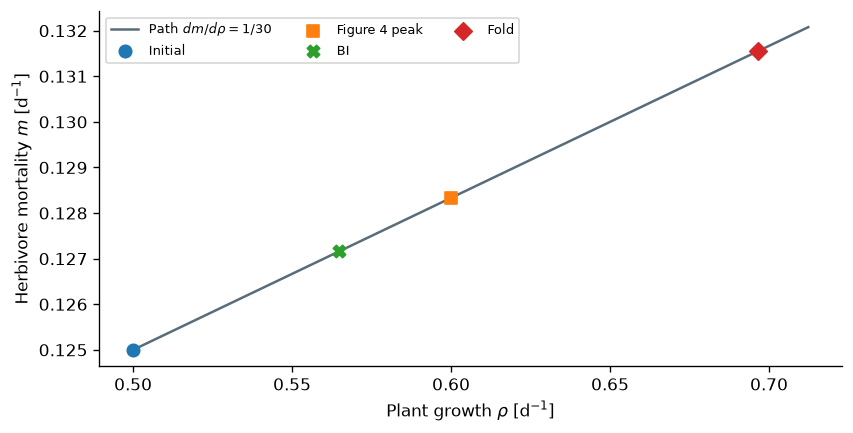

$\Delta m=0.00333333$, $\Delta e=0.50864700$ theo $\rho$, và $\Delta m/0.00655=0.50890585$. BI bracket [0.32985974, 0.32986023], fold tại 0.99985902.

In [46]:
eco_final = eco_targets(eco_peak4)["tracking"]
eco_bi_bracket = basin_threshold(eco_model, eco_initial, eco_levels, eco_scale, 5000)
eco_bi = np.mean(eco_bi_bracket)
eco_frozen_outcomes = [frozen_outcome(eco_model, env, eco_initial, eco_scale, 1600)
                       for env in eco_levels]
assert eco_frozen_outcomes == ["tracking", "tipping"]
assert eco_bi < eco_peak4 < eco_fold
rho_fold, m_fold = eco_path(eco_fold)
eco_fold_H = (rho_fold * eco_P_max - eco_parameters["C"] * eco_P_max**2) / herbivory(eco_P_max)
assert eco_fold_H > 0
np.testing.assert_allclose(eco_field([eco_P_max, eco_fold_H], eco_fold), 0.0, atol=1e-12)
assert abs(np.linalg.det(eco_jac([eco_P_max, eco_fold_H], eco_fold))) < 1e-12

rho_line, m_line = eco_path(np.linspace(0, 1.08, 300))
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(rho_line, m_line, color="#596c79", label=r"Path $dm/d\rho=1/30$")
for env, marker, label in [(0.0, "o", "Initial"), (eco_peak4, "s", "Figure 4 peak"),
                            (eco_bi, "X", "BI"), (eco_fold, "D", "Fold")]:
    ax.scatter(*eco_path(env), marker=marker, s=55, label=label, zorder=4)
ax.set(xlabel=r"Plant growth $\rho$ [$\mathrm{d^{-1}}$]",
       ylabel=r"Herbivore mortality $m$ [$\mathrm{d^{-1}}$]")
ax.legend(ncol=3)
plt.show()

delta_m_path = eco_parameters["path_slope"] * 0.1
display(Markdown(
    rf"$\Delta m={delta_m_path:.8f}$, $\Delta e={eco_peak4:.8f}$ theo $\rho$, "
    rf"và $\Delta m/0.00655={delta_m_path / 0.00655:.8f}$. "
    f"BI bracket [{eco_bi_bracket[0]:.8f}, {eco_bi_bracket[1]:.8f}], "
    f"fold tại {eco_fold:.8f}."
))

*Hình 6.2 · Parameter path.* Peak của Figure 4 nằm giữa BI và fold. Ở mức cuối, frozen trajectory khởi tạo tại initial coexistence hội tụ về plant-only, trong khi final coexistence vẫn hút. Đây là geometry cho phép R-tipping trong một ramp không cắt bifurcation.

### 6.8. Figure 4(a–c) và critical edge state

**Approximate reproduction với tham số Appendix.** Tích phân ramp với $T=200$, $r=0.03,0.1$ và kiểm tra thêm $r=0.0453$ từ Appendix A3. Bisection theo long-term outcome xác định một critical bracket. Với ramp, forcing hằng sau peak. Do đó critical trajectory có thể tiếp cận stable manifold của saddle cuối, đi gần saddle trước khi sai số rate hoặc sai số tích phân đẩy nó sang một basin. Dùng rate giữa bracket để vẽ đường xanh và kiểm tra khoảng cách tới saddle trong cửa sổ hữu hạn.

In [47]:
eco_run_options = {"T": 200.0, "relaxation": 1600.0}
eco_tight = {**eco_run_options, "rtol": 1e-11, "atol": 1e-13, "rate_step": 0.25}
eco_bracket = application_rate_boundary(
    eco_model, eco_initial, eco_peak4, (0.03, 0.1), eco_scale, eco_tight,
)
eco_critical = np.sqrt(eco_bracket[0] * eco_bracket[1])
eco_check_bracket = application_rate_boundary(
    eco_model, eco_initial, eco_peak4, (0.03, 0.1), eco_scale,
    {**eco_tight, "rtol": 3e-12, "atol": 3e-14, "rate_step": 0.12, "relaxation": 2800.0},
)
assert abs(eco_critical - np.sqrt(eco_check_bracket[0] * eco_check_bracket[1])) < 2e-7

# Kiểm tra xem dùng giá trị làm tròn Δm=0.0033 có giải thích chênh lệch hay không.
eco_rounded = (
    lambda x, env: eco_field(x, env, slope=0.033),
    lambda x, env: eco_jac(x, env, slope=0.033),
    lambda env: eco_targets(env, slope=0.033),
)
eco_rounded_bracket = application_rate_boundary(
    eco_rounded, eco_initial, eco_peak4, (0.03, 0.1), eco_scale, eco_tight,
)
eco_rounded_critical = np.sqrt(eco_rounded_bracket[0] * eco_rounded_bracket[1])
eco_published_label, _ = evaluate_2d(
    eco_model, eco_initial, eco_peak4, 0.0453, "ramp", eco_scale, **eco_tight,
)
eco_rates4 = (0.03, eco_critical, 0.1)
eco_runs4 = [forced_2d(eco_model, eco_initial, eco_peak4, rate, "ramp",
                       dense_output=True, **eco_tight) for rate in eco_rates4]
eco_tau4 = np.linspace(-200, 150, 901)
eco_paths4 = [sample_2d(run, eco_tau4) for run in eco_runs4]
assert min(x.min() for x in eco_paths4) >= -1e-9
assert [outcome_2d(eco_runs4[k], eco_model, eco_peak4, eco_scale) for k in (0, 2)] == [
    "tracking", "tipping",
]
eco_edge = eco_equilibria(eco_peak4)["Upper-P coexistence"]
eco_edge_distance = np.linalg.norm(eco_paths4[1][:, eco_tau4 >= 0] - eco_edge[:, None], axis=0)
display(Markdown(
    f"Critical bracket [{eco_bracket[0]:.10f}, {eco_bracket[1]:.10f}] /ngày. "
    f"Khoảng cách nhỏ nhất từ đường gần tới hạn tới saddle trong cửa sổ vẽ là "
    f"{eco_edge_distance.min():.3e} g/m². Rate Appendix 0.0453 cho {eco_published_label}. "
    f"Dùng shift làm tròn 0.0033 cho critical rate {eco_rounded_critical:.8f} /ngày."
))

Critical bracket [0.0431560110, 0.0431560118] /ngày. Khoảng cách nhỏ nhất từ đường gần tới hạn tới saddle trong cửa sổ vẽ là 6.087e-06 g/m². Rate Appendix 0.0453 cho tipping. Dùng shift làm tròn 0.0033 cho critical rate 0.04353848 /ngày.

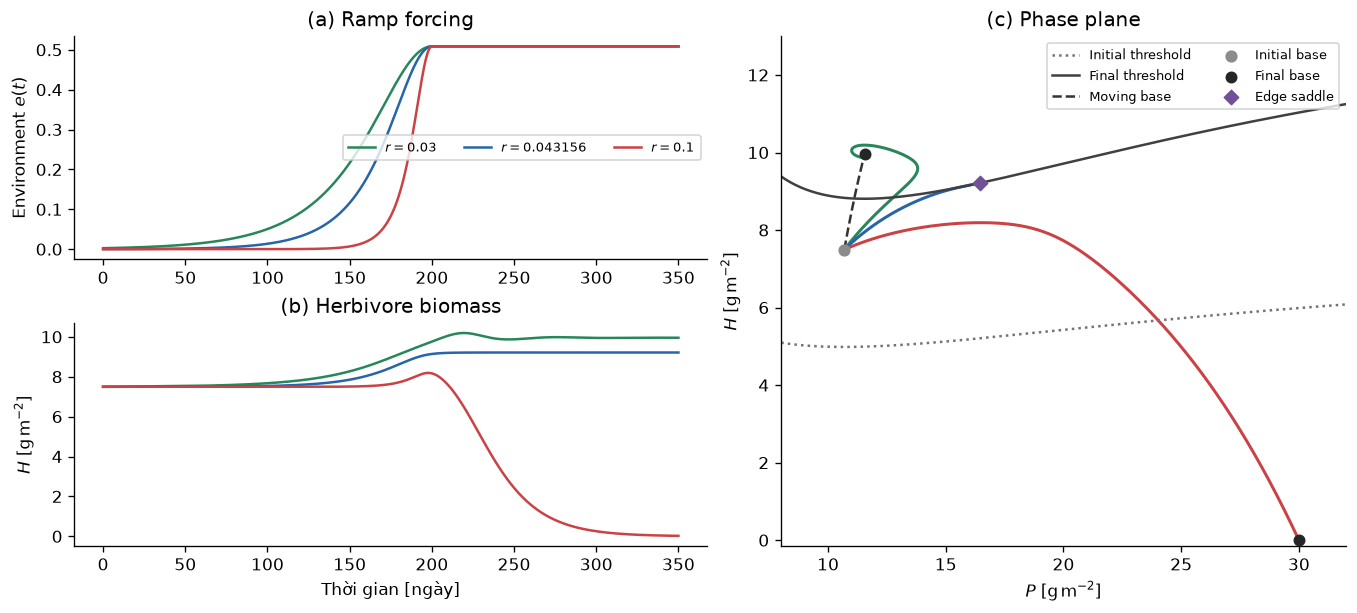

In [48]:
scenario_colors3 = ("#28865b", "#2665a8", "#ca4245")
env_samples_eco = np.linspace(0, eco_peak4, 151)
eco_moving_base = np.array([eco_targets(env)["tracking"] for env in env_samples_eco])


def application_figure_axes():
    fig = plt.figure(figsize=(11.2, 5.0), layout="constrained")
    grid = fig.add_gridspec(2, 2, width_ratios=[1.12, 1.0])
    ax_forcing = fig.add_subplot(grid[0, 0])
    ax_response = fig.add_subplot(grid[1, 0], sharex=ax_forcing)
    ax_phase = fig.add_subplot(grid[:, 1])
    return fig, ax_forcing, ax_response, ax_phase


fig, ax_env, ax_response, ax_phase = application_figure_axes()
for rate, run, trajectory, color in zip(eco_rates4, eco_runs4, eco_paths4, scenario_colors3):
    ax_env.plot(eco_tau4 + 200, run["env"](eco_tau4), color=color, label=f"$r={rate:.6g}$")
    ax_response.plot(eco_tau4 + 200, trajectory[1], color=color)
    ax_phase.plot(*trajectory, color=color, linewidth=1.8)
ax_env.set(ylabel=r"Environment $e(t)$", title="(a) Ramp forcing")
ax_response.set(xlabel="Thời gian [ngày]", ylabel=r"$H$ [$\mathrm{g\,m^{-2}}$]",
                title="(b) Herbivore biomass")
ax_env.legend(ncol=3)
ax_phase.plot(*eco_manifolds[0.0].T, color="0.45", ls=":", label="Initial threshold")
ax_phase.plot(*eco_manifolds[eco_peak4].T, color="0.25", ls="-", label="Final threshold")
ax_phase.plot(*eco_moving_base.T, color="0.2", ls="--", label="Moving base")
ax_phase.scatter(*eco_initial, color="0.55", s=40, label="Initial base", zorder=5)
ax_phase.scatter(*eco_final, color="0.15", s=38, label="Final base", zorder=5)
ax_phase.scatter(*eco_edge, color="#725097", marker="D", s=36, label="Edge saddle", zorder=5)
ax_phase.scatter(*eco_targets(eco_peak4)["tipping"], color="0.15", s=38, zorder=5)
ax_phase.set(xlim=(8, 32), ylim=(-0.15, 13), title="(c) Phase plane",
             xlabel=r"$P$ [$\mathrm{g\,m^{-2}}$]", ylabel=r"$H$ [$\mathrm{g\,m^{-2}}$]")
ax_phase.legend(loc="upper right", ncol=2)
plt.show()

*Figure 4(a–c).* Ramp chậm về coexistence, ramp nhanh về plant-only và đường gần tới hạn lưu lại gần saddle cuối. Với Eq. (A8), $r_c\approx0.043156$ gần giá trị $0.04315812$ trong script video. Phép thử dùng $\Delta m=0.0033$ không giải thích hết chênh lệch với $0.0453$ trong Appendix A3. Bản vẽ dùng nghiệm số gần tới hạn, giữ các rates chậm/nhanh của Appendix và báo riêng kết quả tại rate làm tròn. [Script video Plant–Herbivore](https://github.com/hassanalkhayuon/rtippingreview/blob/main/tipping_movie_ecoModel.m)

**Additional Experiment · Tracking error.** So sánh chuẩn Euclidean trên biomass gốc với khoảng cách sau khi chia theo scales $(20,15)$. Cả hai tọa độ có cùng đơn vị; scale vẫn ảnh hưởng mức đóng góp của một biến vào chuẩn.

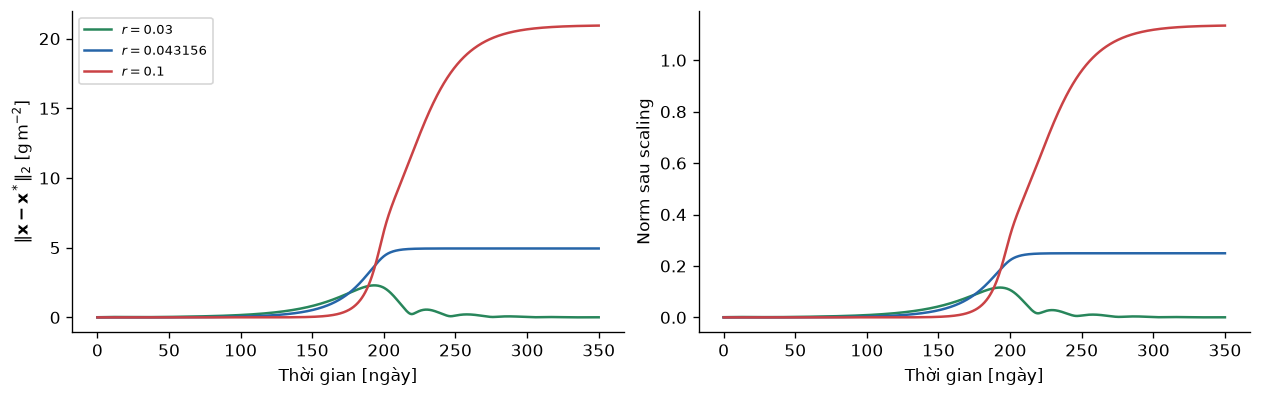

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.2), sharex=True, layout="constrained")
for rate, run, x, color in zip(eco_rates4, eco_runs4, eco_paths4, scenario_colors3):
    levels = run["env"](eco_tau4)
    base = np.array([np.interp(levels, env_samples_eco, eco_moving_base[:, k])
                     for k in range(2)])
    difference = x - base
    axes[0].plot(eco_tau4 + 200, np.linalg.norm(difference, axis=0), color=color,
                 label=f"$r={rate:.6g}$")
    axes[1].plot(eco_tau4 + 200, np.linalg.norm(difference / eco_scale[:, None], axis=0),
                 color=color)
axes[0].set_ylabel(r"$\|\mathbf{x}-\mathbf{x}^*\|_2$ [$\mathrm{g\,m^{-2}}$]")
axes[1].set_ylabel("Norm sau scaling")
for ax in axes:
    ax.set_xlabel("Thời gian [ngày]")
axes[0].legend()
plt.show()

*Hình 6.3.* Khoảng cách về gần zero khi ramp chậm đã thư giãn tới base state cuối. Plateau của đường gần tới hạn phản ánh thời gian lưu gần saddle. Khoảng cách đo độ lệch vị trí, còn hội tụ dài hạn và basin quyết định outcome.

### 6.9. Tipping Diagram · Figure 5(a)

**Approximate reproduction.** Dùng phạm vi hiển thị đã xác minh từ script Figure 5, $\Delta e\in[0,1.5]$, $r\in[10^{-3},1]\ \mathrm{d^{-1}}$. Tính một coarse grid rồi refine theo $\Delta e$ tuyến tính và $\log r$. Dùng $a(0)\le10^{-5}$ như Appendix. Với mỗi ô tích phân cả ramp và return, phân loại theo equilibrium cuối và lưu metadata vào NPZ. Hai phương án khác outcome được giữ riêng, kể cả nếu xuất hiện kết hợp ngoài ba màu của paper. [Script Figure 5](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Plotting_crit_boundaries_PH_AMOC_v2.py)

In [50]:
def sweep_2d(model, initial, scale, peaks, rates, settings, seed=None):
    shape = (2, len(rates), len(peaks))
    outcomes = np.full(shape, -2, dtype=np.int8)
    endpoint = np.full(shape + (2,), np.nan)
    if seed is not None:
        indices = np.ix_(range(2), np.searchsorted(rates, seed["rates"]),
                         np.searchsorted(peaks, seed["peaks"]))
        outcomes[indices] = seed["outcomes"]
        endpoint[indices] = seed["endpoint"]
    for p, i, j in np.argwhere(outcomes == -2):
        label, run = evaluate_2d(model, initial, peaks[j], rates[i], profiles[p],
                                 scale, **settings)
        outcomes[p, i, j] = OUTCOME_CODES[label]
        endpoint[p, i, j] = run["x_end"]
    return {"peaks": peaks, "rates": rates, "outcomes": outcomes, "endpoint": endpoint}


def cached_2d_sweep(name, model, params, initial, scale, peaks, rates, settings, seed=None):
    from inspect import getsource
    metadata = json.dumps(
        {"model": name, "parameters": params, "initial": initial.tolist(),
         "scale": scale.tolist(), "settings": settings, "profiles": list(profiles),
         "scipy": scipy.__version__, "numpy": np.__version__,
         "outcome_codes": OUTCOME_CODES, "state_tolerance": 2e-5},
        sort_keys=True,
    )
    functions = (sech, external_forcing, ramp_profile, return_profile, minimum_peak_time,
                 integrate_2d, forced_2d, classify_2d, outcome_2d, extend_2d, evaluate_2d, sweep_2d)
    implementation = "".join(getsource(function) for function in (*functions, *model))
    key = sha256(metadata.encode() + implementation.encode() + peaks.tobytes() + rates.tobytes())
    path = sweep_cache_dir / f"stage3-{name}-{key.hexdigest()[:16]}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as stored:
            assert stored["metadata"].item() == metadata
            return {key: stored[key] for key in ("peaks", "rates", "outcomes", "endpoint")}, path

    results = sweep_2d(model, initial, scale, peaks, rates, settings, seed)
    solver_settings = json.dumps({
        "method": "LSODA", "rtol": 1e-9, "atol": 1e-11,
        "rate_step": 0.5, "return_tail": 1e-9, "state_tolerance": 2e-5,
        "max_relaxation": 3 * settings["relaxation"], **settings,
    }, sort_keys=True)
    path.parent.mkdir(exist_ok=True, parents=True)
    with NamedTemporaryFile(dir=path.parent, delete=False) as temp:
        temporary_path = Path(temp.name)
        np.savez_compressed(temp, metadata=metadata, solver_settings=solver_settings, **results)
    try:
        temporary_path.replace(path)
    finally:
        temporary_path.unlink(missing_ok=True)
    return results, path


def outcome_transitions(grid, peak_index, profile):
    labels = grid["outcomes"][profiles.index(profile), :, peak_index]
    return transition_brackets(grid["rates"], labels)


def focused_rate_slice(model, initial, peak, scale, rates, settings, width=3e-5):
    def compute(rate):
        label, _ = evaluate_2d(model, initial, peak, rate, "return", scale, **settings)
        return OUTCOME_CODES[label]

    labels = np.array([compute(rate) for rate in rates])
    intervals = [refine_rate_bracket(compute, bracket, relative_width=width)
                 for bracket in transition_brackets(rates, labels)]
    return labels, intervals

In [51]:
eco_sweep_settings = {"relaxation": 1600.0, "initial_tail": 1e-5}
eco_peaks5 = np.linspace(0, 1.5, 49)
eco_rates5 = np.geomspace(1e-3, 1, 49)
eco_coarse5, eco_coarse_file = cached_2d_sweep(
    "eco-coarse", eco_model, eco_parameters, eco_initial, eco_scale,
    eco_peaks5[::4], eco_rates5[::4], eco_sweep_settings,
)
eco_grid5, eco_fine_file = cached_2d_sweep(
    "eco-fine", eco_model, eco_parameters, eco_initial, eco_scale,
    eco_peaks5, eco_rates5, eco_sweep_settings, seed=eco_coarse5,
)
np.testing.assert_array_equal(eco_grid5["outcomes"][:, ::4, ::4], eco_coarse5["outcomes"])
assert np.isfinite(eco_grid5["endpoint"]).all()
eco_j = int(np.argmax([len(outcome_transitions(eco_grid5, j, "return"))
                      for j in range(len(eco_peaks5))]))
eco_slice_labels, eco_slice_intervals = focused_rate_slice(
    eco_model, eco_initial, eco_peaks5[eco_j], eco_scale, np.geomspace(1e-3, 1, 75),
    {**eco_sweep_settings, "rtol": 1e-10, "atol": 1e-12, "rate_step": 0.25},
)

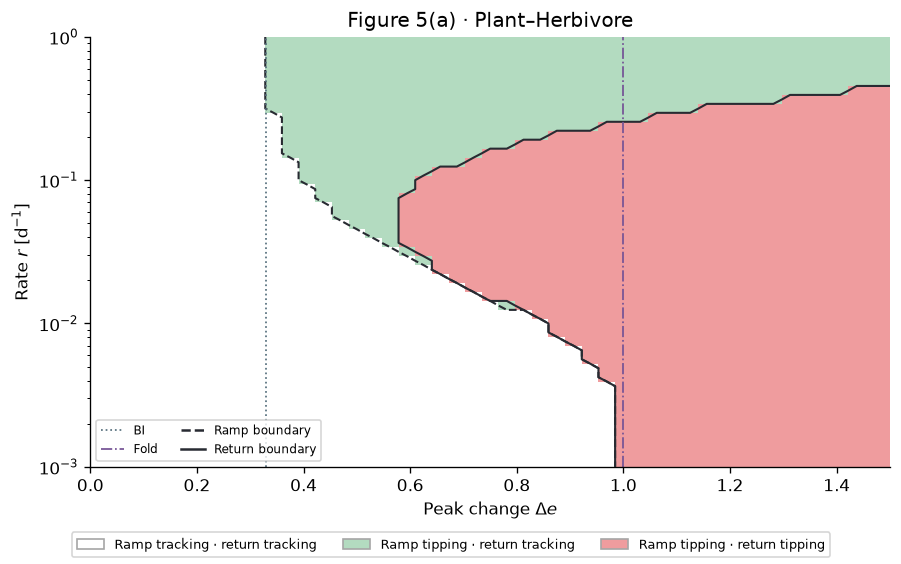

| Peak | Outcome theo $r$ tăng | Critical rate | Bracket |
|---:|:---|---:|:---|
| 0.59375 | tracking → tipping | 0.033974469 | [0.033974082, 0.033974856] |
| 0.59375 | tipping → tracking | 0.08220012 | [0.082199184, 0.082201057] |

Cache gồm 4,802 outcomes. Còn 0 unresolved. File stage3-eco-fine-18bf7c282522b854.npz.

In [52]:
def plot_application_boundary(ax, grid, markers, *, rate_label, peak_label, title):
    peaks, rates, outcomes = grid["peaks"], grid["rates"], grid["outcomes"]
    joint = combined_outcome_grid(outcomes)
    ax.pcolormesh(peaks, rates, joint, shading="nearest", cmap=ListedColormap(REGION_COLORS),
                  norm=BoundaryNorm(np.arange(-0.5, 5.5), 5))
    for values, linestyle in zip(outcomes, ("--", "-")):
        data = np.ma.masked_less(values, 0)
        if np.any(data == 0) and np.any(data == 1):
            ax.contour(peaks, rates, data, levels=[0.5], colors="#282b32",
                       linestyles=linestyle, linewidths=1.25, corner_mask=False)
    for label, value, color, linestyle in markers:
        ax.axvline(value, color=color, linestyle=linestyle, linewidth=1.05, label=label)
    ax.set(xlim=(peaks[0], peaks[-1]), ylim=(rates[0], rates[-1]), yscale="log",
           xlabel=peak_label, ylabel=rate_label, title=title)
    handles, _ = ax.get_legend_handles_labels()
    handles += [Line2D([], [], color="#282b32", ls=ls, label=label)
                for ls, label in (("--", "Ramp boundary"), ("-", "Return boundary"))]
    ax.legend(handles=handles, loc="lower left", fontsize=7, ncol=2)
    return joint


def application_region_legend(fig, *regions):
    visible = np.unique(np.concatenate([grid.ravel() for grid in regions]))
    fig.legend(handles=[Patch(facecolor=REGION_COLORS[k], edgecolor="0.65",
                              label=REGION_LABELS[k]) for k in visible],
               ncol=min(3, len(visible)), loc="outside lower center")


def show_application_slice(peak, intervals):
    rows = ["| Peak | Outcome theo $r$ tăng | Critical rate | Bracket |",
            "|---:|:---|---:|:---|"]
    for low, high, left, right in intervals:
        rows.append(f"| {peak:.6g} | {CODE_TO_OUTCOME[left]} → {CODE_TO_OUTCOME[right]} "
                    f"| {np.sqrt(low*high):.8g} | [{low:.8g}, {high:.8g}] |")
    display(Markdown("\n".join(rows)))


eco_figure5_markers = [("BI", eco_bi, "#58717f", ":"), ("Fold", eco_fold, "#755395", "-.")]
fig, ax = plt.subplots(figsize=(7.4, 4.6), layout="constrained")
eco_joint = plot_application_boundary(
    ax, eco_grid5, eco_figure5_markers, rate_label=r"Rate $r$ [$\mathrm{d^{-1}}$]",
    peak_label=r"Peak change $\Delta e$", title="Figure 5(a) · Plant–Herbivore",
)
application_region_legend(fig, eco_joint)
plt.show()
show_application_slice(eco_peaks5[eco_j], eco_slice_intervals)
display(Markdown(f"Cache gồm {eco_grid5['outcomes'].size:,} outcomes. "
                 f"Còn {np.count_nonzero(eco_grid5['outcomes'] < 0)} unresolved. "
                 f"File {eco_fine_file.name}."))

*Figure 5(a).* Đường ramp tiến từ gần fold ở rate nhỏ về gần BI ở rate lớn. Vùng đỏ của return lấn sang phía $\Delta e<1$, nên có xung tipping trước fold. Lát cắt được chọn từ lưới theo số transitions phát hiện được và được scan lại với cấu hình chặt hơn. Phần xanh thể hiện **points of return** cho đúng symmetric impulse đã thử. Phần đỏ thể hiện **points of no return** đối với cặp profiles ấy.

### 6.10. Tổng hợp phương pháp

Từ hệ logistic growth và non-monotone herbivory, nullclines tìm được stable coexistence, plant-only và một saddle nội miền. Frozen basin mapping và backward manifold xác định geometry cho BI. Tích phân non-autonomous cùng critical bracket kiểm tra khi nào state tới gần edge saddle. Workflow dùng được cho mô hình hai chiều khác khi attractors và phase-space boundaries được xác định lại theo vector field riêng.

## Module 7 — Atlantic Meridional Overturning Circulation · Figures 4(d–f), 5(b)

### 7.1–7.2. Từ năm boxes tới hai state variables

**Mục tiêu.** Xác định hình học basin boundary khi edge state là repelling periodic orbit. Wood et al. (2019) mô tả trao đổi muối giữa North Atlantic (N), Tropical Atlantic (T), Indo-Pacific (IP), Southern Ocean (S) và Bottom waters (B). Alkhayuon et al. (2019) quan sát $S_S,S_B$ biến thiên chậm và giữ chúng cố định trong reduced model. Conservation of salt xác định $S_{IP}$, để lại $S_N,S_T$ là hai biến động lực. Ritchie et al. dùng calibration $2\times\mathrm{CO_2}$ và đặt time profiles cho hosing để nghiên cứu R-tipping. [Wood et al.](https://doi.org/10.1007/s00382-019-04956-1) · [Alkhayuon et al.](https://doi.org/10.1098/rspa.2019.0051) · [Appendix A4](https://doi.org/10.5194/esd-14-669-2023)

### 7.3. Flow, salt conservation và forcing

**Original reproduction · Eq. (A11–A16).** Dùng salinity mass fractions trong phương trình vật lý. $q$ biểu diễn overturning volume transport. $\lambda_q$ là hệ số vật lý của Eq. (A11). Hosing $H$ mới là forcing điều khiển các freshwater fluxes.
$$
q=\frac{\lambda_q[\alpha(T_S-T_0)+\beta(S_N-S_S)]}{1+\lambda_q\alpha\mu},
\qquad
S_{IP}=\frac{C_{\rm salt}-V_N S_N-V_T S_T-V_S S_S-V_B S_B}{V_{IP}}.
$$

Với $q\ge0$, N nhận advective inflow từ T và T nhận hỗn hợp từ S và IP. Với $q<0$, dòng đảo chiều nên N nhận từ B và T nhận từ N. Các mixing terms $K_N,K_S$ và freshwater terms giữ nguyên:
$$
\begin{aligned}
q\ge0:\quad V_N\dot S_N &= q(S_T-S_N)+K_N(S_T-S_N)-F_NS_0,\\
V_T\dot S_T &=q[\gamma S_S+(1-\gamma)S_{IP}-S_T]+K_S(S_S-S_T)
                   +K_N(S_N-S_T)-F_TS_0;\\[2pt]
q<0:\quad V_N\dot S_N &= |q|(S_B-S_N)+K_N(S_T-S_N)-F_NS_0,\\
V_T\dot S_T &=|q|(S_N-S_T)+K_S(S_S-S_T)+K_N(S_N-S_T)-F_TS_0.
\end{aligned}
$$

$$
\begin{pmatrix}F_N\\F_T\\F_{IP}\\F_S\end{pmatrix}
=\begin{pmatrix}0.486\\-0.997\\-0.754\\1.265\end{pmatrix}
+H(t)\begin{pmatrix}0.1311\\0.6961\\-0.5646\\-0.2626\end{pmatrix}\quad[\mathrm{Sv}],
\qquad H(t)=\Delta H\,a(rt).
$$

| Tham số | Giá trị | Đơn vị / quy ước | Nguồn |
|---|---|---|---|
| $V_N,V_T,V_S,V_{IP},V_B$ | $(0.3683,0.5418,0.6097,1.4860,9.9250)\times10^{17}$ | $\mathrm{m^3}$ | BoxModel_2DH_IVP.m |
| $S_0,S_S,S_B$ | $0.035,0.034427,0.034538$ | mass fraction ($35,34.427,34.538$ psu) | BoxModel_2DH_IVP.m |
| $C_{\rm salt}$ | $4.4735\times10^{16}$ | $\mathrm{m^3}$ nhân mass fraction | BoxModel_2DH_IVP.m |
| $\alpha,\beta$ | $0.12,790.0$ | $\mathrm{kg\,m^{-3}}$ trên °C và trên mass fraction | BoxModel_2DH_IVP.m |
| $T_S,T_0$ | $7.919,3.87$ | °C | BoxModel_2DH_IVP.m |
| $\lambda_q,\mu$ | $1.62\times10^7,\,22\times10^{-8}$ | $\mathrm{m^6\,kg^{-1}\,s^{-1}}$, °C·s·m$^{-3}$ | BoxModel_2DH_IVP.m |
| $\gamma$ | 0.36 | không thứ nguyên | BoxModel_2DH_IVP.m |
| $K_N,K_S$ | $1.762,1.872$ | Sv, $1~\mathrm{Sv}=10^6~\mathrm{m^3\,s^{-1}}$ | BoxModel_2DH_IVP.m |
| $F_i(H)$ | hệ số Eq. (A16) ở trên | Sv, với coefficients theo $H$ không thứ nguyên | Appendix A4 |
| Hệ số đổi thời gian | $3.15\times10^7$ | giây/năm | BoxModel_2DH_IVP.m |
| $H_-,\Delta H,T$ Figure 4 | $0,0.365,1000$ | Sv, Sv, năm | Appendix A4 |
| $r$ Figure 4 | $0.005,\ \approx 0.01645,\ 0.017$ | $\mathrm{yr^{-1}}$ | Appendix A4 |

Code tích phân trong tọa độ $u_i=100(S_i-S_0)$ như MATLAB và đổi sang psu khi vẽ. Các $q,K,F$ nội bộ tính bằng Sv. Hai tổng hệ số của $F_i$ đều bằng 0; conservation của tổng muối là một ràng buộc riêng áp dụng khi tính $S_{IP}$. [Mã vector field](https://github.com/hassanalkhayuon/rtippingreview/blob/main/BoxModel_2DH_IVP.m)

### 7.4–7.5. Equilibria và local bifurcations

**Additional Mathematical Analysis.** $q$ là hàm affine theo $u_N$. N-nullcline cho $u_T$ tường minh theo $u_N$ trong mỗi miền dấu. Khi $q\ge0$, khử mẫu $q+K_N$ và thay vào T-nullcline để thu được đa thức; khi $q<0$, N-nullcline đã là đa thức. Giải nghiệm thực và kiểm tra dấu $q$ cùng residual của hai phương trình gốc. Các advective terms tiến về 0 khi $q\to0$, nên vector field liên tục. Jacobian lấy theo từng smooth region và có thể đổi qua mặt $q=0$.

Tính $\operatorname{tr}J=0$ trên nhánh AMOC-On, kiểm tra $\det J>0$ và dấu phần thực qua điểm đó. Tìm upper fold bằng hệ $f_N=f_T=\det J=0$ và kiểm tra số equilibria đổi qua nó. Tính repelling cycles ở phía còn stable của Hopf trong §7.6 để kiểm tra tính subcritical.

In [53]:
amoc_parameters = {
    "S0": 0.035, "V": (0.3683e17, 0.5418e17, 0.6097e17, 1.4860e17, 9.9250e17),
    "SS": 0.034427, "SB": 0.034538, "salt": 4.4735e16,
    "alpha": 0.12, "beta": 790.0, "Ts": 7.919, "T0": 3.87, "lambda_q": 1.62e7,
    "mu": 22e-8, "gamma": 0.36, "KN": 1.762, "KS": 1.872, "seconds_year": 3.15e7,
    "flux0": (0.486, -0.997, -0.754, 1.265),
    "flux_slope": (0.1311, 0.6961, -0.5646, -0.2626),
}
VN, VT, VS, VIP, VB = amoc_parameters["V"]
amoc_S0 = amoc_parameters["S0"]
uS = 100 * (amoc_parameters["SS"] - amoc_S0)
uB = 100 * (amoc_parameters["SB"] - amoc_S0)
amoc_uIP_offset = (100 * (amoc_parameters["salt"]
                          - amoc_S0 * sum(amoc_parameters["V"])) - VS * uS - VB * uB) / VIP
amoc_KN, amoc_KS = amoc_parameters["KN"], amoc_parameters["KS"]
amoc_gamma = amoc_parameters["gamma"]
amoc_ell, amoc_alpha = amoc_parameters["lambda_q"], amoc_parameters["alpha"]
amoc_q_factor = 1e-6 * amoc_ell / (1 + amoc_ell * amoc_alpha * amoc_parameters["mu"])
amoc_q_slope = amoc_q_factor * amoc_parameters["beta"] / 100
amoc_q_offset = amoc_q_factor * amoc_alpha * (amoc_parameters["Ts"] - amoc_parameters["T0"]) - amoc_q_slope * uS
amoc_time_factors = 1e6 * amoc_parameters["seconds_year"] / np.array([VN, VT])
amoc_scale = np.array([0.15, 0.15])


def amoc_fluxes(hosing):
    hosing = np.asarray(hosing)
    return (np.asarray(amoc_parameters["flux0"]) + hosing[..., None]
            * np.asarray(amoc_parameters["flux_slope"]))


def amoc_q(uN):
    return amoc_q_offset + amoc_q_slope * uN


def amoc_salinity_IP(uN, uT):
    return amoc_uIP_offset - (VN * uN + VT * uT) / VIP


def amoc_psu(u):
    return 1000 * amoc_S0 + 10 * np.asarray(u)


def amoc_field(state, hosing, *, positive_region=None):
    uN, uT = state
    FN0, FT0 = amoc_parameters["flux0"][:2]
    FN1, FT1 = amoc_parameters["flux_slope"][:2]
    q = amoc_q(uN)
    mix_N = amoc_KN * (uT - uN) - 100 * amoc_S0 * (FN0 + FN1 * hosing)
    mix_T = (amoc_KS * (uS - uT) + amoc_KN * (uN - uT)
             - 100 * amoc_S0 * (FT0 + FT1 * hosing))
    forward_N = q * (uT - uN)
    forward_T = q * (amoc_gamma * uS + (1 - amoc_gamma) * amoc_salinity_IP(uN, uT) - uT)
    reverse_N = -q * (uB - uN)
    reverse_T = -q * (uN - uT)
    positive = q >= 0.0 if positive_region is None else positive_region
    return np.array([amoc_time_factors[0] * (mix_N + np.where(positive, forward_N, reverse_N)),
                     amoc_time_factors[1] * (mix_T + np.where(positive, forward_T, reverse_T))])


def amoc_jac(state, hosing, *, positive_region=None):
    uN, uT = state
    q, q_n = amoc_q(uN), amoc_q_slope
    KN, KS = amoc_KN, amoc_KS
    positive = q >= 0.0 if positive_region is None else positive_region
    if positive:
        salt_in = amoc_gamma * uS + (1 - amoc_gamma) * amoc_salinity_IP(uN, uT) - uT
        mat = [[q_n * (uT - uN) - q - KN, q + KN],
               [q_n * salt_in - q * (1 - amoc_gamma) * VN / VIP + KN,
                -q * (1 + (1 - amoc_gamma) * VT / VIP) - KS - KN]]
    else:
        mat = [[-q_n * (uB - uN) + q - KN, KN],
               [-q_n * (uN - uT) - q + KN, q - KS - KN]]
    return np.asarray(mat) * amoc_time_factors[:, None]


def amoc_N_nullcline(uN, hosing):
    q = amoc_q(uN)
    FN = amoc_fluxes(hosing)[0]
    positive = q >= 0.0
    denominator = np.where(positive, amoc_KN + q, amoc_KN)
    offset = 100 * amoc_S0 * FN + np.where(positive, 0.0, q * (uB - uN))
    return uN + offset / denominator


@lru_cache(maxsize=4096)
def amoc_equilibria(hosing):
    FN, FT = amoc_fluxes(hosing)[:2]
    n = Polynomial([0, 1])
    q = Polynomial([amoc_q_offset, amoc_q_slope])
    salt_N, salt_T = (100 * amoc_S0 * flux for flux in (FN, FT))

    # q>=0: multiply the tropical equation by D=K_N+q.
    D = q + amoc_KN
    t_num = n * D + salt_N
    ip_num = amoc_uIP_offset * D - (VN * n * D + VT * t_num) / VIP
    pos = (q * (amoc_gamma * uS * D + (1 - amoc_gamma) * ip_num - t_num)
           + amoc_KS * (uS * D - t_num) + amoc_KN * (n * D - t_num) - salt_T * D)

    # q<0: the northern nullcline is already polynomial.
    t = n + (salt_N + q * (uB - n)) / amoc_KN
    neg = (-q * (n - t) + amoc_KS * (uS - t) + amoc_KN * (n - t) - salt_T)

    states = []
    for polynomial, positive in ((pos, True), (neg, False)):
        for candidate in polynomial.roots():
            if abs(candidate.imag) > 1e-9:
                continue
            uN = candidate.real
            if (amoc_q(uN) >= 0) != positive:
                continue
            point = np.array([uN, amoc_N_nullcline(uN, hosing)])
            if np.linalg.norm(amoc_field(point, hosing)) < 1e-9:
                states.append(point)
    return sorted(states, key=lambda state: state[0])


@lru_cache(maxsize=4096)
def amoc_targets(hosing):
    targets = {}
    for point in amoc_equilibria(hosing):
        if stability_2d(amoc_jac(point, hosing))[0] == "stable":
            targets["tracking" if amoc_q(point[0]) > 0 else "tipping"] = point
    return targets


amoc_model = (amoc_field, amoc_jac, amoc_targets)
amoc_initial = amoc_targets(0.0)["tracking"]
amoc_peak4 = 0.365

In [54]:
amoc_levels = (0.0, amoc_peak4)
q_zero_n = -amoc_q_offset / amoc_q_slope
for uT in (0.02, 0.16, 0.3):
    point = np.array([q_zero_n, uT])
    np.testing.assert_allclose(amoc_field(point, amoc_peak4, positive_region=True),
                               amoc_field(point, amoc_peak4, positive_region=False),
                               atol=3e-17)
np.testing.assert_allclose(amoc_fluxes(np.linspace(0, 0.45, 11)).sum(axis=-1), 0, atol=4e-16)

amoc_state_tables = []
for env in amoc_levels:
    states = amoc_equilibria(env)
    assert len(states) == 3
    assert [stability_2d(amoc_jac(point, env))[0] for point in states] == [
        "stable", "saddle", "stable",
    ]
    for point in states:
        np.testing.assert_allclose(amoc_field(point, env), np.zeros(2), atol=1e-10)
        np.testing.assert_allclose(
            amoc_jac(point, env), centered_jacobian(amoc_field, point, env), atol=1e-9,
        )
        uN, uT = point
        salt = np.dot(amoc_parameters["V"],
                      amoc_S0 + np.array([uN, uT, uS, amoc_salinity_IP(uN, uT), uB]) / 100)
        np.testing.assert_allclose(salt, amoc_parameters["salt"], rtol=1e-15)
    amoc_state_tables.append((env, dict(zip(("AMOC-Off", "Saddle", "AMOC-On"), states))))
equilibrium_table(amoc_state_tables, amoc_jac, transform=amoc_psu)
display(Markdown("Đã kiểm tra Eq. (A16), total salt, Jacobian hai phía và tính liên tục tại $q=0$."))

| Forcing | Equilibrium | State coordinates | Eigenvalues | Stability |
|---:|:---|:---|:---|:---|
| 0 | AMOC-Off | (33.01545, 36.49950) | -0.021583, -0.0039685 | stable |
| 0 | Saddle | (33.79829, 43.40063) | -0.013875, 0.004408 | saddle |
| 0 | AMOC-On | (35.32375, 36.43450) | -0.008206+0.011696j, -0.008206-0.011696j | stable |
| 0.365 | AMOC-Off | (32.85160, 35.21635) | -0.023489, -0.0054284 | stable |
| 0.365 | Saddle | (34.12270, 38.23148) | 0.024784, -0.0012817 | saddle |
| 0.365 | AMOC-On | (34.73135, 36.59916) | -0.001129+0.0071482j, -0.001129-0.0071482j | stable |

Đã kiểm tra Eq. (A16), total salt, Jacobian hai phía và tính liên tục tại $q=0$.

In [55]:
from matplotlib.path import Path as PolygonPath


def amoc_on_branch(hosing):
    states = amoc_equilibria(hosing)
    return max(states, key=lambda point: point[0])


def amoc_trace(hosing):
    return np.trace(amoc_jac(amoc_on_branch(hosing), hosing))


amoc_hopf = brentq(amoc_trace, 0.38, 0.4, xtol=1e-13)
hopf_spectrum = np.linalg.eigvals(amoc_jac(amoc_on_branch(amoc_hopf), amoc_hopf))
assert np.all(np.abs(hopf_spectrum.imag) > 0.0)
assert amoc_trace(amoc_hopf - 1e-4) < 0 < amoc_trace(amoc_hopf + 1e-4)


def amoc_fold_conditions(unknown):
    state, env = unknown[:2], unknown[2]
    return np.r_[100 * amoc_field(state, env), 1e5 * np.linalg.det(amoc_jac(state, env))]


fold_solution = root(amoc_fold_conditions, np.r_[amoc_on_branch(0.421), 0.422])
assert fold_solution.success and np.linalg.norm(fold_solution.fun) < 1e-8
amoc_fold = fold_solution.x[2]

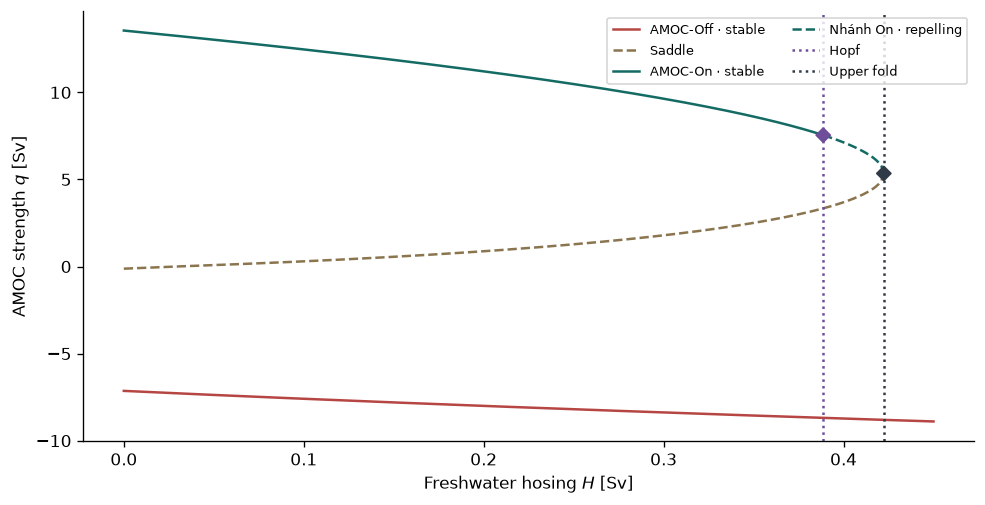

Hopf tại 0.388710431 Sv, eigenvalues -1.843e-17+0.006157j, -1.843e-17-0.006157j /năm. Độ dốc trace qua Hopf là 0.11265. Upper fold tại 0.422389474 Sv.

In [56]:
hopf_trace_slope = (amoc_trace(amoc_hopf + 1e-5) - amoc_trace(amoc_hopf - 1e-5)) / 2e-5
assert hopf_trace_slope > 0
for side, count in ((-1, 3), (1, 1)):
    assert len(amoc_equilibria(amoc_fold + side * 1e-5)) == count

h_bif = np.linspace(0.0, amoc_fold - 1e-7, 301)
q_branch = np.array([[amoc_q(point[0]) for point in amoc_equilibria(env)] for env in h_bif])
q_fold = amoc_q(fold_solution.x[0])
fig, ax = plt.subplots(figsize=(8.1, 4.1), layout="constrained")
h_off = np.linspace(0.0, 0.45, 301)
ax.plot(h_off, [amoc_q(amoc_equilibria(env)[0][0]) for env in h_off],
        color="#b64643", label="AMOC-Off · stable")
ax.plot(np.r_[h_bif, amoc_fold], np.r_[q_branch[:, 1], q_fold],
        color="#8a754f", ls="--", label="Saddle")
stable_h = h_bif < amoc_hopf
q_hopf = amoc_q(amoc_on_branch(amoc_hopf)[0])
ax.plot(np.r_[h_bif[stable_h], amoc_hopf], np.r_[q_branch[stable_h, 2], q_hopf],
        color="#146b64", label="AMOC-On · stable")
ax.plot(np.r_[amoc_hopf, h_bif[~stable_h], amoc_fold],
        np.r_[q_hopf, q_branch[~stable_h, 2], q_fold],
        color="#146b64", ls="--", label="Nhánh On · repelling")
ax.scatter([amoc_hopf, amoc_fold], [q_hopf, q_fold], c=["#6e4e9a", "#303a47"],
           marker="D", zorder=4)
ax.axvline(amoc_hopf, color="#6e4e9a", ls=":", label="Hopf")
ax.axvline(amoc_fold, color="#303a47", ls=":", label="Upper fold")
ax.set(xlabel="Freshwater hosing $H$ [Sv]", ylabel="AMOC strength $q$ [Sv]")
ax.legend(ncol=2)
plt.show()
display(Markdown(
    f"Hopf tại {amoc_hopf:.9f} Sv, eigenvalues {hopf_spectrum[0]:.4g}, "
    f"{hopf_spectrum[1]:.4g} /năm. Độ dốc trace qua Hopf là {hopf_trace_slope:.5g}. "
    f"Upper fold tại {amoc_fold:.9f} Sv."
))

*Hình 7.1 · Equilibrium bifurcations.* Hai attracting equilibria và một saddle cùng tồn tại ở $H=0$ và $H=0.365$. AMOC-On mất stability ở Hopf. Upper fold ở hosing lớn hơn làm mất hai equilibria không hút. Vị trí tính được gần các giá trị ba-box, $2\times\mathrm{CO_2}$ của Table 6, với sai khác nhỏ phù hợp với coefficients đã làm tròn và phương pháp tìm nghiệm. [Table 6 của Alkhayuon et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC6545045/#T6)

### 7.6. Repelling periodic orbit và frozen basin boundary

**Additional Mathematical Analysis.** Một periodic orbit lặp lại toàn bộ state sau một chu kỳ. Perturbations ngang giảm nếu chu kỳ hút và tăng nếu chu kỳ đẩy. Trong phase plane, một chu kỳ kín bất biến có thể ngăn trajectories từ hai phía đi xuyên qua nhau. Với AMOC tại final hosing, ta kiểm tra rằng inside tiến về AMOC-On và outside tiến về AMOC-Off.

**Additional Experiment.** Tại $H=0.365$ và một mức gần Hopf hơn, tích phân ngược từ gần AMOC-On để lấy section crossing của một chu kỳ hút theo chiều ngược. Dùng forward shooting để tìm fixed point $P(u_N)-u_N=0$ của Poincaré map tại $u_T=u_{T,\mathrm{On}}$. Kiểm tra closure và transverse Floquet multiplier
$$
M_\perp=\exp\!\left(\int_0^{\mathcal T}\operatorname{tr}J(\mathbf u(t),H)\,dt\right)
$$
bằng cả divergence integral và sai phân của Poincaré map. Chu kỳ phải có $M_\perp>1$. So kích thước hai chu kỳ ở phía ổn định của Hopf với kết quả subcritical trong nghiên cứu nguồn. Phép tính local này chưa theo dõi chu kỳ đến homoclinic bifurcation.

In [57]:
def amoc_cycle(hosing, *, rtol=1e-12, atol=1e-14, backward_time=22000):
    """Backward attraction supplies a seed, then forward shooting checks the orbit."""
    on = amoc_targets(hosing)["tracking"]

    def backward_section(time, state):
        return state[1] - on[1]

    backward_section.direction = 1
    reverse = integrate_2d(
        lambda time, x: -amoc_field(x, hosing), (0.0, backward_time),
        on + np.array([0.002, 0.0]), method="DOP853", rtol=rtol, atol=atol,
        max_step=30.0, events=backward_section,
    )
    crossings = reverse.y_events[0]
    if len(crossings) < 4:
        raise ValueError("Chưa đủ Poincaré crossings trong backward integration.")
    guess = crossings[-1, 0]
    width = abs(guess - on[0])
    if width < 1e-4:
        raise ValueError("Section seed quá gần equilibrium.")

    def forward_section(time, state):
        return state[1] - on[1]

    forward_section.direction = -1

    period_estimate = reverse.t_events[0][-1] - reverse.t_events[0][-2]

    def first_return(uN, *, dense_output=False):
        sol = integrate_2d(
            lambda time, x: amoc_field(x, hosing), (0.0, 1.5 * period_estimate),
            [uN, on[1]], method="DOP853", rtol=rtol, atol=atol,
            max_step=15.0, events=forward_section, dense_output=dense_output,
        )
        indices = np.flatnonzero(sol.t_events[0] > 1e-3)
        if not indices.size:
            raise ValueError("Không có lần trở lại Poincaré section.")
        j = indices[0]
        return sol.y_events[0][j, 0], sol.t_events[0][j], sol

    def residual(uN):
        return first_return(uN)[0] - uN

    for fraction in (4e-8, 4e-7, 4e-6, 4e-5):
        left, right = guess - fraction * width, guess + fraction * width
        returned_left, period_left, _ = first_return(left)
        returned_right, period_right, _ = first_return(right)
        nearby_period = max(abs(period_left - period_estimate),
                            abs(period_right - period_estimate)) < 0.05 * period_estimate
        if nearby_period and (returned_left - left) * (returned_right - right) < 0:
            break
    else:
        raise ValueError("Không bracket được fixed point của return map.")
    uN = brentq(residual, left, right, xtol=1e-14)
    end, period, orbit_sol = first_return(uN, dense_output=True)
    times = np.linspace(0.0, period, 2401)
    orbit = orbit_sol.sol(times).T
    closure = np.linalg.norm(orbit[-1] - orbit[0])
    divergence = np.array([np.trace(amoc_jac(point, hosing)) for point in orbit])
    floquet = np.exp(np.trapezoid(divergence, times))
    eps = 5e-10
    slope = (first_return(uN + eps)[0] - first_return(uN - eps)[0]) / (2 * eps)
    assert abs(end - uN) < 1e-8 and closure < 1e-8 and floquet > 1
    assert np.min(amoc_q(orbit[:, 0])) > 0.0
    np.testing.assert_allclose(floquet, slope, rtol=2e-3)
    return {"states": orbit, "period": period, "closure": closure,
            "multiplier": floquet, "section_slope": slope,
            "reverse_drift": abs(crossings[-1, 0] - crossings[-2, 0])}

In [58]:
amoc_final = amoc_targets(amoc_peak4)["tracking"]
amoc_boundary_final = amoc_cycle(amoc_peak4)
amoc_boundary_near_hopf = amoc_cycle(0.38)
amoc_polygon = PolygonPath(amoc_boundary_final["states"])
assert not amoc_polygon.contains_point(amoc_initial)
assert amoc_polygon.contains_point(amoc_final)
assert np.ptp(amoc_boundary_near_hopf["states"][:, 0]) < np.ptp(amoc_boundary_final["states"][:, 0])

section_state = amoc_boundary_final["states"][0]
inside, outside = [amoc_final + factor * (section_state - amoc_final)
                   for factor in (0.94, 1.06)]
assert [frozen_outcome(amoc_model, amoc_peak4, z, amoc_scale, 15000)
        for z in (inside, outside)] == ["tracking", "tipping"]
cycle_rows = ["| Hosing [Sv] | Chu kỳ [năm] | Closure [psu] | Floquet multiplier | Section slope |",
              "|---:|---:|---:|---:|---:|"]
for env, cycle in ((amoc_peak4, amoc_boundary_final), (0.38, amoc_boundary_near_hopf)):
    cycle_rows.append(f"| {env:.3f} | {cycle['period']:.5f} | {10 * cycle['closure']:.3e} "
                      f"| {cycle['multiplier']:.7g} | {cycle['section_slope']:.7g} |")
display(Markdown("\n".join(cycle_rows)))

| Hosing [Sv] | Chu kỳ [năm] | Closure [psu] | Floquet multiplier | Section slope |
|---:|---:|---:|---:|---:|
| 0.365 | 1591.78707 | 1.014e-10 | 22141.02 | 22141.49 |
| 0.380 | 1116.52705 | 8.136e-15 | 3.955711 | 3.955711 |

**Frozen basin map và phase portraits.** Tích phân RK4 theo lưới tại hai mức hosing, giữ cùng state range và kiểm tra lại điểm lưới bằng LSODA. Ở $H=0$, vẽ phần stable manifold của saddle đi qua vùng quan sát. Ở $H=0.365$, so vùng hội tụ tới AMOC-On với chu kỳ đã kiểm chứng bằng shooting.

In [59]:
amoc_N_grid = np.linspace(-0.245, 0.067, 73)
amoc_T_grid = np.linspace(-0.02, 0.343, 73)
amoc_basins = {}
for env in amoc_levels:
    labels = basin_map_2d(amoc_model, env, amoc_N_grid, amoc_T_grid, amoc_scale, 14000, 6)
    amoc_basins[env] = labels
    assert validate_basin_points(amoc_model, env, amoc_N_grid, amoc_T_grid,
                                 labels, amoc_scale, 14000) == (4, 4)
amoc_manifold_initial = saddle_manifold(
    amoc_model, 0.0, amoc_equilibria(0.0)[1], ((-0.31, -0.11), (0.14, 0.96)),
    epsilon=5e-7, backward_time=9000, max_step=18.0,
)
N_2d, T_2d = np.meshgrid(amoc_N_grid, amoc_T_grid)
in_cycle = amoc_polygon.contains_points(np.column_stack([N_2d.ravel(), T_2d.ravel()]))
expected = np.where(in_cycle, 0, 1).reshape(N_2d.shape)
resolved = amoc_basins[amoc_peak4] >= 0
basin_agreement = np.mean(expected[resolved] == amoc_basins[amoc_peak4][resolved])
assert basin_agreement > 0.99
display(Markdown(f"Chu kỳ và basin map đồng ý tại {basin_agreement:.2%} các ô resolved. "
                 "Bốn điểm kiểm tra mỗi mức hosing đồng ý với LSODA."))

Chu kỳ và basin map đồng ý tại 100.00% các ô resolved. Bốn điểm kiểm tra mỗi mức hosing đồng ý với LSODA.

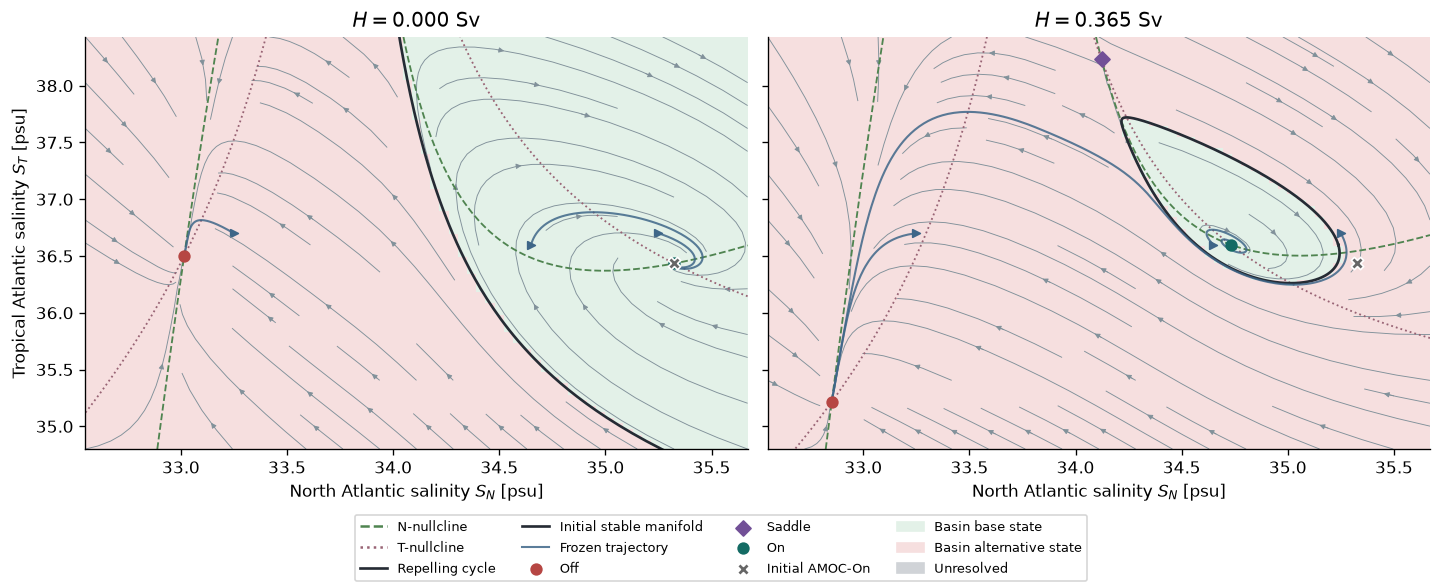

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(11.9, 4.8), sharey=True, sharex=True,
                         layout="constrained")
for ax, env in zip(axes, amoc_levels):
    phase_background(ax, amoc_N_grid, amoc_T_grid, amoc_basins[env], amoc_field,
                     env, transform=amoc_psu)
    field_values = amoc_field((N_2d, T_2d), env)
    for values, linestyle, color, name in zip(field_values, ("--", ":"), ("#4f8450", "#986374"),
                                               ("N-nullcline", "T-nullcline")):
        ax.contour(amoc_psu(amoc_N_grid), amoc_psu(amoc_T_grid), values, levels=[0],
                   linestyles=linestyle, colors=color, linewidths=1.1)
        ax.plot([], [], ls=linestyle, color=color, label=name)
    line = amoc_manifold_initial if env == 0.0 else amoc_boundary_final["states"]
    ax.plot(*amoc_psu(line.T), color="#252b34", linewidth=1.6,
            label="Initial stable manifold" if env == 0.0 else "Repelling cycle")
    plot_frozen_examples(ax, amoc_model, env, [(-0.175, 0.17), (0.025, 0.17), (-0.035, 0.16)],
                         3400, transform=amoc_psu)
    for k, (point, name) in enumerate(zip(amoc_equilibria(env), ("Off", "Saddle", "On"))):
        ax.scatter(*amoc_psu(point), c=("#b64643", "#725097", "#146b64")[k],
                   marker=("o", "D", "o")[k], s=41, zorder=6, label=name)
    ax.scatter(*amoc_psu(amoc_initial), color="0.4", edgecolor="white", s=55, marker="X",
               zorder=7, label="Initial AMOC-On")
    ax.set(xlim=amoc_psu(amoc_N_grid[[0, -1]]), ylim=amoc_psu(amoc_T_grid[[0, -1]]),
           xlabel=r"North Atlantic salinity $S_N$ [psu]", title=f"$H={env:.3f}$ Sv")
axes[0].set_ylabel(r"Tropical Atlantic salinity $S_T$ [psu]")
handles, labels = axes[1].get_legend_handles_labels()
handles.insert(3, Line2D([], [], color="#252b34", lw=1.6, label="Initial stable manifold"))
fig.legend(handles + basin_legend, [line.get_label() for line in handles + basin_legend],
           loc="outside lower center", ncol=4)
plt.show()

*Hình 7.2 · Frozen basins.* Ở final hosing, quỹ đạo tuần hoàn có closure nhỏ và transverse multiplier lớn hơn 1. Basin map cho thấy inside là basin của AMOC-On. Ở initial level, saddle ở ngoài phạm vi trục nhưng một nhánh manifold đi qua vùng vẽ. Tọa độ initial AMOC-On nằm bên ngoài chu kỳ cuối và hội tụ AMOC-Off ở frozen system cuối.

### 7.7. Vector hosing và Basin Instability

**Original reproduction.** Với Figure 4(d–f), $H$ đi từ 0 đến $0.365$ Sv. Eq. (A16) biến một scalar hosing profile thành bốn freshwater histories cùng thỏa $\sum_i F_i=0$. Kiểm tra Basin Instability bằng frozen integrations từ initial AMOC-On. Dùng bisection tìm mức đổi attractor qua bracket đã chọn ở phía dưới Hopf.

In [61]:
amoc_frozen_outcomes = [
    frozen_outcome(amoc_model, env, amoc_initial, amoc_scale, 18000) for env in amoc_levels
]
assert amoc_frozen_outcomes == ["tracking", "tipping"]
amoc_bi_bracket = basin_threshold(
    amoc_model, amoc_initial, (0.35, amoc_peak4), amoc_scale, 30000,
)
amoc_bi = np.mean(amoc_bi_bracket)
assert amoc_bi < amoc_peak4 < amoc_hopf < amoc_fold
forcing_flux_table = ["| $H$ [Sv] | $F_N$ | $F_T$ | $F_{IP}$ | $F_S$ | Sum [Sv] |",
                      "|---:|---:|---:|---:|---:|---:|"]
for hosing in amoc_levels:
    flux = amoc_fluxes(hosing)
    numbers = " | ".join(f"{value:+.7f}" for value in flux)
    forcing_flux_table.append(f"| {hosing:.3f} | {numbers} | {sum(flux):.2e} |")
display(Markdown("\n".join(forcing_flux_table)))
display(Markdown(f"BI bracket [{amoc_bi_bracket[0]:.9f}, {amoc_bi_bracket[1]:.9f}] Sv. "
                 "Initial AMOC-On ở ngoài chu kỳ cuối, trong basin AMOC-Off."))

| $H$ [Sv] | $F_N$ | $F_T$ | $F_{IP}$ | $F_S$ | Sum [Sv] |
|---:|---:|---:|---:|---:|---:|
| 0.000 | +0.4860000 | -0.9970000 | -0.7540000 | +1.2650000 | -2.22e-16 |
| 0.365 | +0.5338515 | -0.7429235 | -0.9600790 | +1.1691510 | 0.00e+00 |

BI bracket [0.361494560, 0.361494575] Sv. Initial AMOC-On ở ngoài chu kỳ cuối, trong basin AMOC-Off.

### 7.8. Figure 4(d–f) và critical trajectory

**Approximate reproduction với tham số Appendix.** Tích phân $T=1000$, $r=0.005,0.017$ và kiểm tra rate làm tròn $0.01645$. So sánh sau khi siết tolerance, thay step limit và relaxation. Dùng midpoint của critical bracket để quan sát trajectory đi gần chu kỳ trong khoảng thời gian hữu hạn. Kiểm tra độc lập bằng cách xét vị trí state tại peak so với chu kỳ cuối khi ramp đã cố định. Khi rate lệch khỏi ranh giới, trajectory có thể lưu lâu gần chu kỳ rồi rời đi về một attractor.

In [62]:
amoc_r4_settings = {"T": 1000.0, "relaxation": 18000.0}
amoc_tight4 = {**amoc_r4_settings, "rtol": 1e-11, "atol": 1e-13, "rate_step": 0.25}
amoc_bracket4 = application_rate_boundary(
    amoc_model, amoc_initial, amoc_peak4, (0.005, 0.017), amoc_scale, amoc_tight4,
)
amoc_critical4 = np.sqrt(amoc_bracket4[0] * amoc_bracket4[1])
amoc_strict4 = {**amoc_tight4, "rtol": 3e-12, "atol": 3e-14,
                "rate_step": 0.12, "relaxation": 28000.0}
amoc_strict_bracket = application_rate_boundary(
    amoc_model, amoc_initial, amoc_peak4, (0.005, 0.017), amoc_scale, amoc_strict4,
)
assert abs(amoc_critical4 - np.sqrt(amoc_strict_bracket[0] * amoc_strict_bracket[1])) < 2e-8
for rate, expected in ((amoc_critical4 - 5e-6, True), (amoc_critical4 + 5e-6, False)):
    run = forced_2d(amoc_model, amoc_initial, amoc_peak4, rate, "ramp", **amoc_tight4)
    assert amoc_polygon.contains_point(run["x_peak"]) == expected

amoc_rates4 = (0.005, amoc_critical4, 0.017)
amoc_tau4 = np.linspace(-1000, 3200, 1601)
amoc_runs4 = [forced_2d(amoc_model, amoc_initial, amoc_peak4, rate, "ramp",
                        dense_output=True, **amoc_tight4) for rate in amoc_rates4]
amoc_paths4 = [sample_2d(run, amoc_tau4) for run in amoc_runs4]
assert [outcome_2d(amoc_runs4[k], amoc_model, amoc_peak4, amoc_scale) for k in (0, 2)] == [
    "tracking", "tipping",
]
amoc_pub_outcome, _ = evaluate_2d(amoc_model, amoc_initial, amoc_peak4, 0.01645, "ramp",
                                  amoc_scale, **amoc_tight4)
amoc_cycle_tree = cKDTree(amoc_boundary_final["states"])
amoc_near_edge = amoc_cycle_tree.query(amoc_paths4[1][:, amoc_tau4 >= 0].T)[0] * 10
for k in (0, 2):
    check = forced_2d(amoc_model, amoc_initial, amoc_peak4, amoc_rates4[k], "ramp",
                      dense_output=True, **amoc_strict4)
    np.testing.assert_allclose(sample_2d(check, amoc_tau4), amoc_paths4[k], atol=2e-6, rtol=0)
display(Markdown(
    f"Critical bracket [{amoc_bracket4[0]:.11f}, {amoc_bracket4[1]:.11f}] /năm. "
    f"Rate làm tròn 0.01645 cho {amoc_pub_outcome}. Khoảng cách tối thiểu từ đường gần tới hạn "
    f"đến mẫu chu kỳ sau peak là {amoc_near_edge.min():.3e} psu."
))

Critical bracket [0.01644874450, 0.01644874480] /năm. Rate làm tròn 0.01645 cho tipping. Khoảng cách tối thiểu từ đường gần tới hạn đến mẫu chu kỳ sau peak là 1.052e-06 psu.

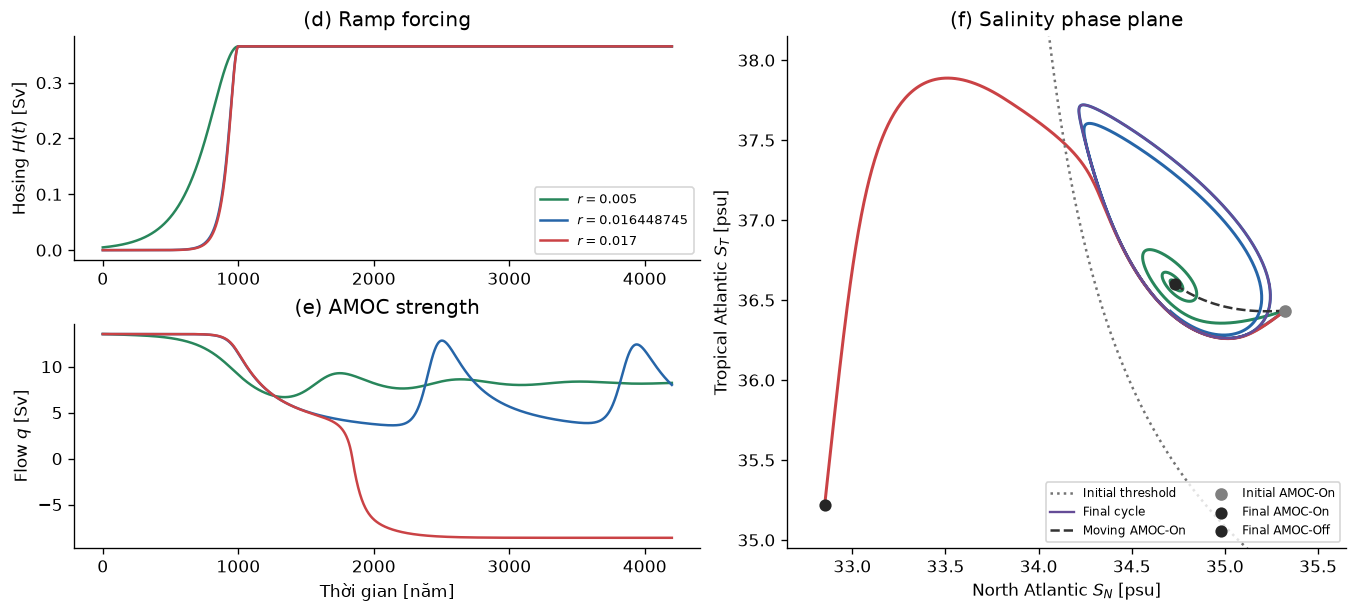

In [63]:
fig, ax_h, ax_q, ax_phase = application_figure_axes()
for rate, run, trajectory, color in zip(amoc_rates4, amoc_runs4, amoc_paths4, scenario_colors3):
    ax_h.plot(amoc_tau4 + 1000, run["env"](amoc_tau4), color=color, label=f"$r={rate:.8g}$")
    ax_q.plot(amoc_tau4 + 1000, amoc_q(trajectory[0]), color=color)
    ax_phase.plot(*amoc_psu(trajectory), color=color, linewidth=1.8)
ax_h.set(ylabel="Hosing $H(t)$ [Sv]", title="(d) Ramp forcing")
ax_q.set(xlabel="Thời gian [năm]", ylabel="Flow $q$ [Sv]", title="(e) AMOC strength")
ax_h.legend()
ax_phase.plot(*amoc_psu(amoc_manifold_initial.T), color="0.45", ls=":", label="Initial threshold")
ax_phase.plot(*amoc_psu(amoc_boundary_final["states"].T), color="#654c97", lw=1.4, label="Final cycle")
levels4 = np.linspace(0.0, amoc_peak4, 151)
on_path = np.array([amoc_targets(env)["tracking"] for env in levels4])
ax_phase.plot(*amoc_psu(on_path.T), color="0.2", ls="--", label="Moving AMOC-On")
ax_phase.scatter(*amoc_psu(amoc_initial), c="0.5", s=43, zorder=5, label="Initial AMOC-On")
ax_phase.scatter(*amoc_psu(amoc_final), c="0.15", s=40, zorder=5, label="Final AMOC-On")
ax_phase.scatter(*amoc_psu(amoc_targets(amoc_peak4)["tipping"]), c="0.15", s=40, zorder=5,
                 label="Final AMOC-Off")
ax_phase.set(xlim=(32.65, 35.65), ylim=(34.95, 38.15), title="(f) Salinity phase plane",
             xlabel=r"North Atlantic $S_N$ [psu]", ylabel=r"Tropical Atlantic $S_T$ [psu]")
ax_phase.legend(loc="lower right", ncol=2, fontsize=7)
plt.show()

*Figure 4(d–f).* Ramp chậm cho AMOC-On, ramp nhanh cho AMOC-Off. Đường gần tới hạn dao động gần final cycle, nên diễn biến khác việc lưu gần một saddle point ở Figure 4(c). $r_c$ làm tròn khớp $0.01645$ trong Appendix. Script video AMOC dùng $T=2000$, rate xanh $0.0164491186245$ và rate đỏ $0.05$. Notebook giữ $T=1000$ và rate đỏ $0.017$ của Appendix. Các đồ thị gần ranh giới phụ thuộc chữ số của rate và horizon. [Script video AMOC](https://github.com/hassanalkhayuon/rtippingreview/blob/main/tipping_movie_AMOC.m)

### 7.9. Tipping Diagram · Figure 5(b)

**Approximate reproduction.** Dùng phạm vi của script Figure 5, $\Delta H\in[0.35,0.45]$ Sv và $r\in[10^{-6},10^{-1}]\ \mathrm{yr^{-1}}$. Tính coarse rồi fine grids như Module 6 với cùng initial-tail condition của Appendix A4. Mask các ô unresolved khi vẽ contour. Thêm các vạch BI, Hopf và upper fold tính từ model. Ở gần Hopf, decay hoặc growth của dao động có thể rất chậm, nên kiểm tra thêm với thời gian thư giãn dài trước khi gán outcome. [Script Figure 5](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Plotting_crit_boundaries_PH_AMOC_v2.py) · [Script tính boundary](https://github.com/hassanalkhayuon/rtippingreview/blob/main/tipping_diagram_AMOC.m)

In [64]:
amoc_peaks5 = np.linspace(0.35, 0.45, 51)
amoc_rates5 = np.geomspace(1e-6, 1e-1, 61)
amoc_sweep_settings = {"relaxation": 22000.0, "initial_tail": 1e-5,
                       "max_relaxation": 300000.0}
amoc_coarse5, amoc_coarse_file = cached_2d_sweep(
    "amoc-coarse", amoc_model, amoc_parameters, amoc_initial, amoc_scale,
    amoc_peaks5[::5], amoc_rates5[::5], amoc_sweep_settings,
)
amoc_grid5, amoc_fine_file = cached_2d_sweep(
    "amoc-fine", amoc_model, amoc_parameters, amoc_initial, amoc_scale,
    amoc_peaks5, amoc_rates5, amoc_sweep_settings, seed=amoc_coarse5,
)
np.testing.assert_array_equal(amoc_grid5["outcomes"][:, ::5, ::5], amoc_coarse5["outcomes"])
assert np.isfinite(amoc_grid5["endpoint"]).all()
amoc_figure5_markers = [("BI", amoc_bi, "#58717f", ":"),
                        ("Hopf", amoc_hopf, "#755395", "-."),
                        ("Fold", amoc_fold, "#353640", ":")]

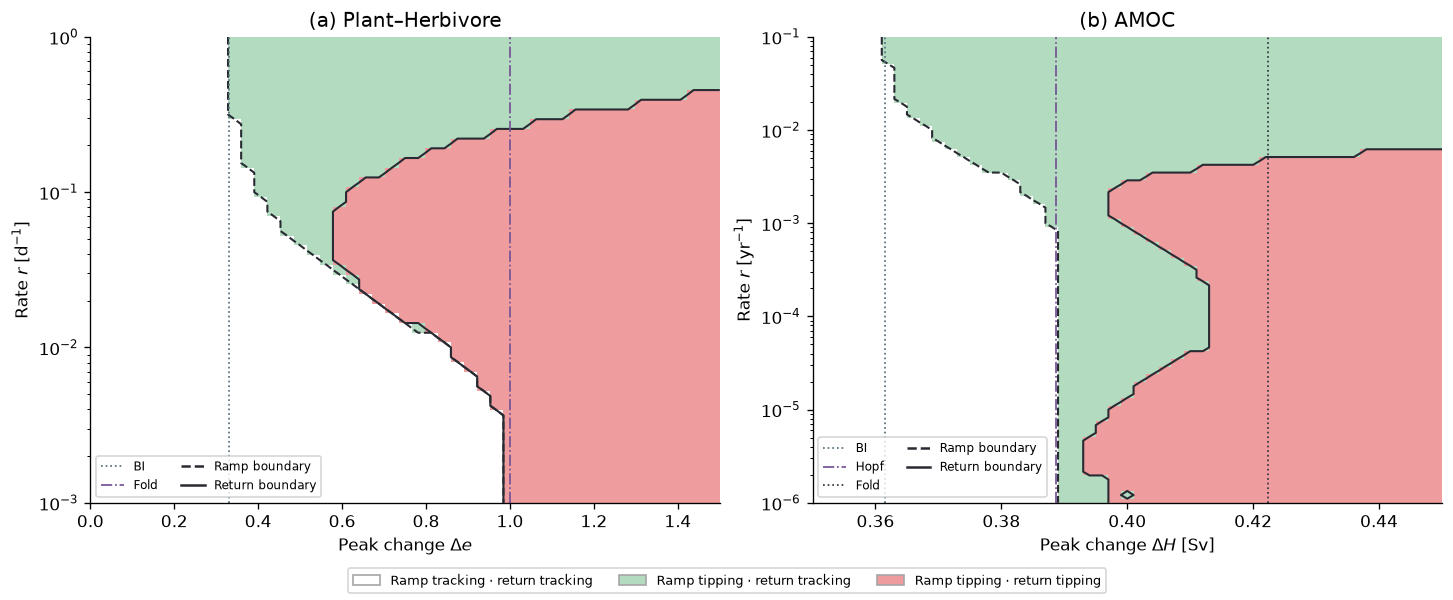

Cache AMOC gồm 6,222 outcomes, 0 unresolved. Có 0 ô đỏ phía dưới Hopf trong lưới này. File stage3-amoc-fine-b4bf9092e3513523.npz.

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.9), layout="constrained")
eco_joint5 = plot_application_boundary(
    axes[0], eco_grid5, eco_figure5_markers, rate_label=r"Rate $r$ [$\mathrm{d^{-1}}$]",
    peak_label=r"Peak change $\Delta e$", title="(a) Plant–Herbivore",
)
amoc_joint = plot_application_boundary(
    axes[1], amoc_grid5, amoc_figure5_markers, rate_label=r"Rate $r$ [$\mathrm{yr^{-1}}$]",
    peak_label=r"Peak change $\Delta H$ [Sv]", title="(b) AMOC",
)
application_region_legend(fig, eco_joint5, amoc_joint)
plt.show()

amoc_below_hopf = amoc_peaks5 < amoc_hopf
amoc_red_below_hopf = np.count_nonzero(amoc_joint[:, amoc_below_hopf] == 2)
display(Markdown(f"Cache AMOC gồm {amoc_grid5['outcomes'].size:,} outcomes, "
                 f"{np.count_nonzero(amoc_grid5['outcomes'] < 0)} unresolved. "
                 f"Có {amoc_red_below_hopf} ô đỏ phía dưới Hopf trong lưới này. "
                 f"File {amoc_fine_file.name}."))

*Figure 5 tái tạo.* Cả hai ramps cho vùng R-tipping trước local bifurcation. Vùng đỏ của Plant–Herbivore đi sang trái fold, còn vùng đỏ của AMOC trong lưới nằm phía trên Hopf theo hosing. Đường bao tính từ lưới hữu hạn nên có thể có góc do phân giải. Hai màu xanh/đỏ đánh giá tác dụng của một symmetric return bắt đầu tại peak của cùng ramp. Paper vẽ các curves từ workbook của tác giả. Notebook tính độc lập và đối chiếu cấu trúc vùng với Figure 5. [Figure 5 gốc](../paper/23%20Rate-induced%20tipping%20in%20natural%20and%20human%20systems.pdf#page=8) · [Kho code và workbook](https://zenodo.org/records/7920243)

**Additional Experiment · Multiple critical rates và wiggles.** Lấy lát cắt $\Delta H=0.410$ Sv dưới upper fold và so với một lát cắt sát đầu cửa sổ xanh $\Delta H=0.414$ Sv. Giữ cùng initial-tail và relaxation settings, tăng mật độ rate grid và siết tolerances cùng step limit. Tinh chỉnh **tất cả** khoảng đổi outcome tìm được trên từng lưới. Một cửa sổ chỉ xuất hiện ở một cấu hình được báo là nhạy số. Vì thời gian qua Hopf có thể rất dài ở $r$ nhỏ, một đường răng cưa hoặc cửa sổ hẹp đơn lẻ chưa đủ chứng minh wiggle của continuous system.

In [66]:
amoc_slice_peak = 0.410
amoc_wiggle_peak = 0.414
amoc_refined_settings = {**amoc_sweep_settings, "rtol": 1e-11, "atol": 1e-13,
                          "rate_step": 0.25}
rates_slice_coarse = np.geomspace(6e-6, 8e-3, 41)
rates_slice_fine = np.geomspace(6e-6, 8e-3, 81)
slice_amoc_coarse = focused_rate_slice(
    amoc_model, amoc_initial, amoc_slice_peak, amoc_scale, rates_slice_coarse,
    amoc_sweep_settings,
)
slice_amoc_fine = focused_rate_slice(
    amoc_model, amoc_initial, amoc_slice_peak, amoc_scale, rates_slice_fine,
    amoc_refined_settings,
)
amoc_slice_rates = np.array([np.sqrt(lo * hi) for lo, hi, _, _ in slice_amoc_fine[1]])
amoc_base_slice_rates = np.array([np.sqrt(lo * hi) for lo, hi, _, _ in slice_amoc_coarse[1]])
fine_high = amoc_slice_rates[amoc_slice_rates > 1e-4]
base_high = amoc_base_slice_rates[amoc_base_slice_rates > 1e-4]
np.testing.assert_allclose(fine_high, base_high, rtol=3e-4)
for lo, hi, left, right in slice_amoc_fine[1]:
    if np.sqrt(lo * hi) <= 1e-4:
        continue
    for rate, expected in ((lo / 1.003, left), (hi * 1.003, right)):
        outcome, _ = evaluate_2d(
            amoc_model, amoc_initial, amoc_slice_peak, rate, "return", amoc_scale,
            **{**amoc_refined_settings, "rtol": 1e-12, "atol": 1e-14, "rate_step": 0.15},
        )
        assert OUTCOME_CODES[outcome] == expected
display(Markdown("Lát cắt AMOC 0.410 Sv với cấu hình chặt hơn"))
show_application_slice(amoc_slice_peak, slice_amoc_fine[1])
display(Markdown(f"Số transitions của baseline và lưới chặt là "
                 f"{len(amoc_base_slice_rates)} và {len(amoc_slice_rates)}. "
                 f"Các rates trên $10^{{-4}}$ khớp giữa hai cấu hình trong 0.03%. "
                 f"Rate thấp nhất lần lượt là {min(amoc_base_slice_rates, default=np.nan):.8g} "
                 f"và {min(amoc_slice_rates, default=np.nan):.8g} /năm."))

wiggle_rates_coarse = np.geomspace(2.0e-5, 1.7e-4, 38)
wiggle_rates_fine = np.geomspace(2.0e-5, 1.7e-4, 75)
wiggle_base = focused_rate_slice(
    amoc_model, amoc_initial, amoc_wiggle_peak, amoc_scale, wiggle_rates_coarse,
    amoc_sweep_settings,
)
wiggle_tight = focused_rate_slice(
    amoc_model, amoc_initial, amoc_wiggle_peak, amoc_scale, wiggle_rates_fine,
    amoc_refined_settings,
)
wiggle_strict = focused_rate_slice(
    amoc_model, amoc_initial, amoc_wiggle_peak, amoc_scale, wiggle_rates_fine,
    {**amoc_refined_settings, "rtol": 1e-12, "atol": 1e-14, "rate_step": 0.15},
)
display(Markdown(f"Sát cửa sổ nhỏ tại 0.414 Sv, số transitions phát hiện trong "
                 f"phạm vi zoom lần lượt là {len(wiggle_base[1])}, "
                 f"{len(wiggle_tight[1])}, {len(wiggle_strict[1])}."))

Lát cắt AMOC 0.410 Sv với cấu hình chặt hơn

| Peak | Outcome theo $r$ tăng | Critical rate | Bracket |
|---:|:---|---:|:---|
| 0.41 | tipping → tracking | 2.9487786e-05 | [2.9487463e-05, 2.948811e-05] |
| 0.41 | tracking → tipping | 0.00036215005 | [0.00036214607, 0.00036215403] |
| 0.41 | tipping → tracking | 0.0037529231 | [0.0037528819, 0.0037529643] |

Số transitions của baseline và lưới chặt là 3 và 3. Các rates trên $10^{-4}$ khớp giữa hai cấu hình trong 0.03%. Rate thấp nhất lần lượt là 3.9131837e-05 và 2.9487786e-05 /năm.

Sát cửa sổ nhỏ tại 0.414 Sv, số transitions phát hiện trong phạm vi zoom lần lượt là 2, 4, 4.

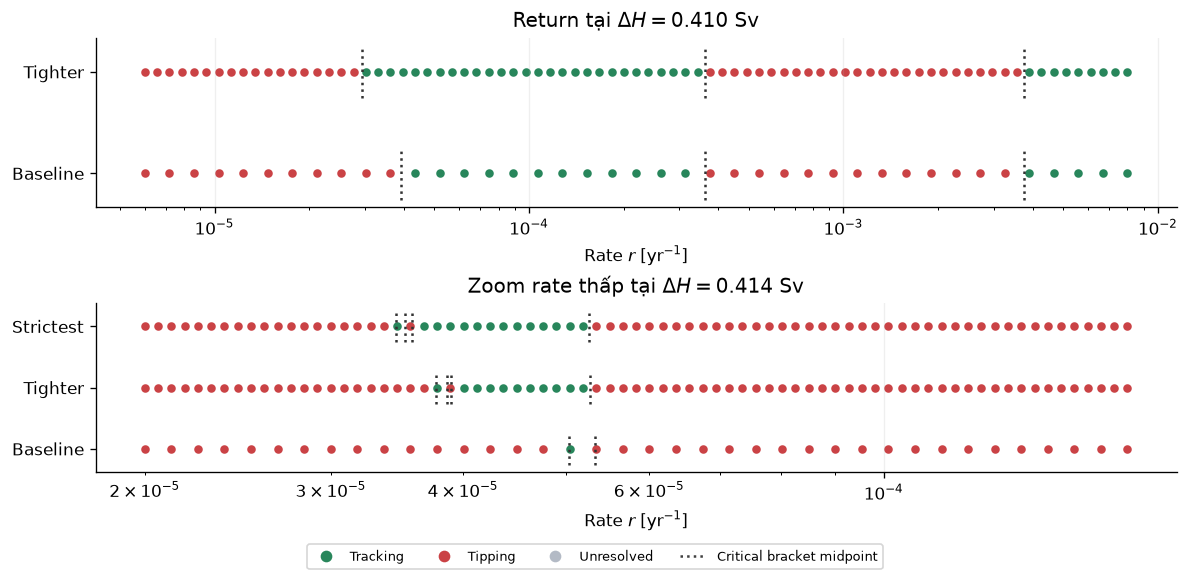

In [67]:
def plot_outcome_strip(ax, datasets, title):
    for y, (name, rates, (labels, intervals)) in enumerate(datasets):
        for outcome_id, color in ((-1, "#b3bac5"), (0, "#28865b"), (1, "#ca4245")):
            mask = labels == outcome_id
            ax.scatter(rates[mask], np.full(mask.sum(), y), color=color, s=17)
        for lo, hi, _, _ in intervals:
            ax.vlines(np.sqrt(lo * hi), y - 0.26, y + 0.26, color="0.2", linestyles=":")
    ax.set(yticks=np.arange(len(datasets)), yticklabels=[item[0] for item in datasets],
           xlabel=r"Rate $r$ [$\mathrm{yr^{-1}}$]", xscale="log", title=title)
    ax.grid(axis="x", alpha=0.2)


fig, axes = plt.subplots(2, 1, figsize=(9.8, 4.7), layout="constrained")
plot_outcome_strip(axes[0], [("Baseline", rates_slice_coarse, slice_amoc_coarse),
                             ("Tighter", rates_slice_fine, slice_amoc_fine)],
                   r"Return tại $\Delta H=0.410$ Sv")
plot_outcome_strip(axes[1], [("Baseline", wiggle_rates_coarse, wiggle_base),
                             ("Tighter", wiggle_rates_fine, wiggle_tight),
                             ("Strictest", wiggle_rates_fine, wiggle_strict)],
                   r"Zoom rate thấp tại $\Delta H=0.414$ Sv")
fig.legend(handles=[
    Line2D([], [], color=color, marker="o", ls="none", label=label)
    for color, label in (("#28865b", "Tracking"), ("#ca4245", "Tipping"),
                         ("#b3bac5", "Unresolved"))
] + [Line2D([], [], color="0.25", ls=":", label="Critical bracket midpoint")],
    loc="outside lower center", ncol=4)
plt.show()

*Hình 7.3 · Kiểm tra độ phân giải.* Lát cắt 0.410 Sv có chuỗi tipping → tracking → tipping → tracking. Hai transitions ở rate cao ổn định hơn transition đầu. Lát cắt 0.414 Sv cho thấy cửa sổ ở mép vùng xanh nhạy với solver. Phần xoay của biên return và nhiều critical rates được tái lập. Vị trí và số lượng wiggles nhỏ ở rate thấp vẫn chưa được xác nhận hội tụ số. Hình giữ tất cả điểm phân loại và critical brackets tìm được.

### 7.10. Tổng hợp AMOC

Giữ tổng muối và đóng băng hai reservoirs chậm cho phép phân tích hệ hai chiều. Hosing làm AMOC-On dịch và basin của nó co lại, tạo BI trước Hopf. Shooting xác nhận final edge state là repelling periodic orbit. Vì vậy trajectory gần tới hạn dao động dọc theo chu kỳ trong pha hậu forcing. Hình học này khác edge saddle của Plant–Herbivore dù cả hai cùng có một ngưỡng theo rate. Quét return profiles cho ba lần đổi outcome trong một lát cắt qua vùng giữa Hopf và fold.

## Comparative Analysis · Modules 1–7

| Property | Tilted saddle-node | Plant–Herbivore | AMOC |
|---|---|---|---|
| State-space dimension | 1 | 2 | 2 sau reduction |
| Model origin | Tilted saddle-node normal form | Scheffer et al., O’Keeffe & Wieczorek | Wood et al., Alkhayuon et al. |
| Base state | Stable $x_+^*$ | Coexistence | AMOC-On |
| Alternative state | $x=0$ | Plant-only | AMOC-Off |
| External forcing | Scalar $\lambda(t)$ | $(\rho,m)$ dọc một path | $H(t)$ điều khiển bốn $F_i$ |
| Bifurcation type | Fold tại $\lambda=0$ trong miền chính | Coexistence fold | Subcritical Hopf rồi upper fold |
| Basin boundary ở ca ramp cuối | Unstable equilibrium | Stable manifold một chiều | Repelling periodic orbit |
| Critical edge state | Unstable equilibrium | Saddle equilibrium | Repelling periodic orbit |
| Basin Instability | $\Delta\lambda_{\rm BI}\approx0.291053$ | $\Delta e_{\rm BI}\approx0.329860$ | $\Delta H_{\rm BI}\approx0.361495$ Sv |
| R-tipping | Ramp đổi outcome khi đổi $r$ | Coexistence → plant-only dưới fold | On → Off dưới Hopf |
| Multiple critical rates | Ba với return tại $\Delta\lambda=0.515$ | Hai ở lát cắt return đã khảo sát | Ba ở lát cắt return tại $0.410$ Sv |

Cơ chế chung là state không theo kịp attractor đang dịch, rồi đi vào basin khác khi forcing tiếp tục. Điều kiện BI kiểm tra trước khả năng đó từ frozen systems. Dạng edge state quyết định đoạn transient quan sát gần rate tới hạn. Trong hệ scalar đó là điểm đẩy, trong Plant–Herbivore là saddle và trong AMOC là dao động gần chu kỳ đẩy. Workflow tái sử dụng được gồm giải equilibrium, kiểm tra eigenvalues, dựng basins, xác minh invariant boundary, tích phân non-autonomous và refine outcome brackets.

**Phạm vi và reproducibility.** Các equations và coefficients được đối chiếu với Appendix cùng scripts tác giả. Figures 4–5 tái tạo gần đúng bằng Python, dùng nghiệm equilibria độc lập và ODE tolerances khác MATLAB. Figures 4(a–f) dùng critical brackets đã tính cho đường gần tới hạn, và kiểm tra riêng các rates làm tròn. Figures 5(a,b) dựa trên lưới và giữ unresolved khi state chưa vào lân cận attractor. Cache NPZ dưới results/ritchie_2023 lưu grids, labels, terminal states và JSON metadata. Các phase maps kiểm chứng trong miền hiển thị. Việc tiếp tục chu kỳ tới homoclinic bifurcation và độ hội tụ của wiggles AMOC ở rate rất thấp nằm ngoài phần đã xác nhận.

## Tóm tắt kết quả · Stage 3

- **Plant–Herbivore.** BI tại $\Delta e\approx0.329860$, trước fold $\Delta e\approx0.999859$. Stable manifold phân cách hai basins. Figure 4(a–c) cho $r_c\approx0.043156\,\mathrm{d^{-1}}$, gần script video. Rate $0.0453$ trong Appendix cho tipping với parameter path đã xác minh.
- **AMOC.** BI tại $\Delta H\approx0.361495$ Sv, trước Hopf $0.388710$ Sv. Chu kỳ đẩy tại $H=0.365$ có period khoảng $1592$ năm. Figure 4(d–f) cho $r_c\approx0.01644874\,\mathrm{yr^{-1}}$ và transient đi gần chu kỳ.
- **Figure 5.** Sweep độc lập tìm được hai critical rates return tại $\Delta e=0.59375$ và ba tại $\Delta H=0.410$ Sv trong AMOC. Các wiggles nhỏ của AMOC ở rate thấp còn nhạy với cấu hình số.

## Module 8 — Power Grid Model · Figure 6

### 8.1–8.2. Mục tiêu và phương trình

**Original Reproduction.** Hệ 4D này mở rộng câu hỏi về R-tipping: sau forcing, hệ có thể giữ cùng operating equilibrium, hồi phục ở bản sao tương đương sau phase slip, hoặc chạm $V=0$. Ta xét mô hình three-bus tổng quát đã công bố, theo Dobson et al. (1988), Dobson & Chiang (1989) và Budd & Wilson (2002). Một generator động và một slack bus cấp cho load có thành phần P–Q và động lực tải kiểu induction motor. [Dobson et al. (1988)](https://doi.org/10.1109/CDC.1988.194705) · [Dobson & Chiang (1989)](https://doi.org/10.1016/0167-6911(89)90072-8) · [Budd & Wilson (2002)](https://people.bath.ac.uk/mascjb/Papers09/wilson.pdf)

$\mathbf x=(\delta_m,\omega_m,\delta,V)^\top$ gồm generator angle, angular velocity tương đối, load angle và voltage magnitude. Swing equation cân bằng mechanical input, electrical output và damping. Hai phương trình cuối mô tả đáp ứng của load angle và voltage đối với power imbalance. Viết đầy đủ Eq. (A17), đổi tên hằng số thời gian tải thành $T_L$ để dành $T$ cho peak time:
$$
\begin{aligned}
\dot\delta_m &= \omega_m,\\
\dot\omega_m &= (-d_m\omega_m+P_m-P_e)/M,\\
\dot\delta &= (-K_{qv}V-K_{qv^2}V^2+Q_l-Q_0-Q_1(t))/K_{q\omega},\\
\dot V &=\frac{1}{T_L K_{q\omega}K_{pv}}\big[
K_{p\omega}K_{qv^2}V^2+
(K_{p\omega}K_{qv}-K_{q\omega}K_{pv})V\\
&\hspace{32mm}+K_{p\omega}(Q_0+Q_1(t)-Q_l)-K_{q\omega}(P_0+P_1-P_l)\big].
\end{aligned}
$$

**Đối chiếu Eq. (A18).** Bản in có ký hiệu $T_0$ ở tích đầu của $P_l$ và thiếu toán tử trước $\theta_m$ trong đối số sin của $P_e$. Mã Figure 6 và quy ước hai đầu của nhánh generator–load cho $Y_0'$ ở $P_l$ và dấu trừ ở $P_e$. $P_l,Q_l$ dùng góc tương đối phía load với dấu cộng. Đây là các biểu thức dùng cho reproduction:
$$
\begin{aligned}
P_l &=-V_0'VY_0'\sin(\delta+\theta_0')
      -V_mVY_m\sin(\delta-\delta_m+\theta_m)
      +[Y_0'\sin\theta_0'+Y_m\sin\theta_m]V^2,\\
Q_l &= V_0'VY_0'\cos(\delta+\theta_0')
      +V_mVY_m\cos(\delta-\delta_m+\theta_m)
      -[Y_0'\cos\theta_0'+Y_m\cos\theta_m]V^2,\\
P_e &=-V_mVY_m\sin(\delta-\delta_m-\theta_m)-V_m^2Y_m\sin\theta_m .
\end{aligned}
$$
Các dấu được kiểm tra bằng công thức Eq. (A17) viết trực tiếp, residual của nghiệm cân bằng và đối chiếu quỹ đạo với cấu hình script. [Appendix A5](https://doi.org/10.5194/esd-14-669-2023) · [Mã Figure 6](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Power_grid_model_plotting_critical_boundaries_regions_P5_v3.py)

| Ký hiệu | Giá trị | Đơn vị | Vai trò | Nguồn |
|---|---:|---|---|---|
| $M,d_m,P_m$ | $0.3,\ 0.05,\ 1$ | Chuẩn hóa | Quán tính, damping, mechanical input | Script Figure 6 |
| $K_{p\omega}, K_{pv}$ | $0.4,\ 0.3$ | Chuẩn hóa | Hệ số đáp ứng real load | Script Figure 6 |
| $K_{q\omega},K_{qv},K_{qv^2}$ | $-0.03,\ -2.8,\ 2.1$ | Chuẩn hóa | Hệ số đáp ứng reactive load | Script Figure 6 |
| $T_L$ | $8.5$ | Model time | Hằng số thời gian tải trong ODE | Script Figure 6 |
| $P_0,Q_0$ | $0.6,\ 1.3$ | Chuẩn hóa | Thành phần tải nền | Script Figure 6 |
| $P_1$ | $5$ | Chuẩn hóa | Real demand cố định | Appendix A5 |
| $V_m,Y_m,\theta_m$ | $1,\ 5,\ -5^\circ$ | Chuẩn hóa và độ | Generator voltage và admittance nhánh | Script Figure 6 |
| $V_0',Y_0',\theta_0'$ | $2.5,\ 8,\ -12^\circ$ | Chuẩn hóa và độ | Điện áp và admittance của slack branch hiệu dụng | Script Figure 6 |
| $Q_{1-},\Delta Q_1$ | $5,\ 5$ | Chuẩn hóa | Mức và peak shift cho Figure 6(a,b) | Appendix A5 |
| $T,r$ | $0.15$ và $50,\ 130,\ 400$ | Model time, inverse model time | Peak time và inverse model time | Appendix A5 |

Góc đổi sang radian trước khi tính. Budd & Wilson mô tả tham số dưới các đại lượng chuẩn hóa, ngoài góc. Notebook giữ model units của Figures 6(a–c) cho điện áp, công suất và thời gian.

### 8.3–8.4. Force là reactive demand và phương pháp tích phân

$$Q_1(t)=Q_{1-}+\Delta Q_1 a(rt).$$

Giữ $P_1=5$ để khảo sát mất ổn định qua fold dọc trục $Q_1$, theo lựa chọn được ghi trong Appendix A5. Appendix A5 đối chiếu lựa chọn này với trường hợp $P_1=0$ có Hopf trong nghiên cứu được dẫn. Notebook kiểm tra dọc high-voltage branch với $P_1=5$ bằng eigenvalues. Input $Q_1$ đi trực tiếp vào reactive imbalance và tác động lên $\dot V$ qua coupling. $Q_1$ là mức demand, $\dot Q_1$ là độ dốc tức thời và $r$ co giãn profile. Theo Module 1, $\max|\dot Q_1|=r|\Delta Q_1|/2$ trên profile đầy đủ.

**Numerical implementation.** Thay $\dot\delta$ vào dòng cuối Eq. (A17) cho $\dot V=(P_l-P_0-P_1-K_{pv}V-K_{p\omega}\dot\delta)/(T_L K_{pv})$. Code dùng biểu thức này và analytic Jacobian. Tích phân LSODA để xử lý mode nhanh và chậm. Giới hạn bước trong forcing window theo $1/r$ và tách tại peak. Kiểm tra đại diện bằng Radau với tolerances chặt. Mã boundary của tác giả dùng solve_ivp, giới hạn bước và terminal event $V=0$. Mã vẽ time series cắt phần âm bằng giới hạn trục. Notebook dừng tại lần chạm $V=0$ theo chiều đi xuống. [Mã bisection](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Power_grid_model_continuation_bisection_rs_P5.py) · [Mã vẽ Figure 6](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Power_grid_model_plotting_critical_boundaries_regions_P5_v3.py)

In [68]:
from math import sin, cos, asin
from scipy.optimize import minimize_scalar

grid_parameters = {
    "M": 0.3, "d_m": 0.05, "P_m": 1.0, "K_pw": 0.4, "K_pv": 0.3,
    "K_qw": -0.03, "K_qv": -2.8, "K_qv2": 2.1, "T_load": 8.5,
    "P_0": 0.6, "Q_0": 1.3, "P_1": 5.0, "Q_1_base": 5.0,
    "V_m": 1.0, "Y_m": 5.0, "theta_m": float(np.deg2rad(-5)),
    "V_0": 2.5, "Y_0": 8.0, "theta_0": float(np.deg2rad(-12)),
}
GRID_TRACK, GRID_RECOVER, GRID_COLLAPSE, GRID_UNKNOWN = 0, 1, 2, -1
grid_outcomes = {GRID_TRACK: "tracking", GRID_RECOVER: "reversible",
                 GRID_COLLAPSE: "irreversible", GRID_UNKNOWN: "unresolved"}
grid_phase_indices = [0, 2]


def grid_powers(delta_m, delta, V, p=grid_parameters):
    """P_e, P_l, Q_l dùng quy ước góc của mã Figure 6."""
    phase = delta - delta_m
    source = p["V_0"] * p["Y_0"]
    machine = p["V_m"] * p["Y_m"]
    sum_sin = p["Y_0"] * sin(p["theta_0"]) + p["Y_m"] * sin(p["theta_m"])
    sum_cos = p["Y_0"] * cos(p["theta_0"]) + p["Y_m"] * cos(p["theta_m"])
    P_e = -machine * (V * sin(phase - p["theta_m"]) + p["V_m"] * sin(p["theta_m"]))
    P_l = V * (-source * sin(delta + p["theta_0"]) - machine * sin(phase + p["theta_m"])
               + V * sum_sin)
    Q_l = V * (source * cos(delta + p["theta_0"]) + machine * cos(phase + p["theta_m"])
               - V * sum_cos)
    return P_e, P_l, Q_l


def grid_frozen(state, Q_1, p=grid_parameters):
    delta_m, omega_m, delta, V = state
    P_e, P_l, Q_l = grid_powers(delta_m, delta, V, p)
    dot_delta = (Q_l - p["K_qv"] * V - p["K_qv2"] * V**2 - p["Q_0"] - Q_1) / p["K_qw"]
    dot_V = (P_l - p["P_0"] - p["P_1"] - p["K_pv"] * V
             - p["K_pw"] * dot_delta) / (p["T_load"] * p["K_pv"])
    return np.array([omega_m, (p["P_m"] - P_e - p["d_m"] * omega_m) / p["M"],
                     dot_delta, dot_V])


def grid_jacobian(state, Q_1, p=grid_parameters):
    delta_m, _, delta, V = state
    angle_0 = delta + p["theta_0"]
    angle_load = delta - delta_m + p["theta_m"]
    angle_gen = delta - delta_m - p["theta_m"]
    vmym = p["V_m"] * p["Y_m"]
    v0y0 = p["V_0"] * p["Y_0"]
    cos_gen = vmym * V * cos(angle_gen)
    cos_load = vmym * cos(angle_load)
    sin_load = vmym * sin(angle_load)
    cos_src = v0y0 * cos(angle_0)
    sin_src = v0y0 * sin(angle_0)
    sum_sin = p["Y_0"] * sin(p["theta_0"]) + p["Y_m"] * sin(p["theta_m"])
    sum_cos = p["Y_0"] * cos(p["theta_0"]) + p["Y_m"] * cos(p["theta_m"])
    row_Q = np.array([V * sin_load, 0.0, -V * (sin_src + sin_load),
                      cos_src + cos_load - 2 * V * sum_cos - p["K_qv"] - 2 * p["K_qv2"] * V])
    row_Q /= p["K_qw"]
    row_P = np.array([V * cos_load, 0.0, -V * (cos_src + cos_load),
                      -sin_src - sin_load + 2 * V * sum_sin - p["K_pv"]])
    return np.vstack((
        [0.0, 1.0, 0.0, 0.0],
        np.array([-cos_gen, -p["d_m"], cos_gen, vmym * sin(angle_gen)]) / p["M"],
        row_Q, (row_P - p["K_pw"] * row_Q) / (p["T_load"] * p["K_pv"]),
    ))

In [69]:
def grid_appendix_rhs(state, demand):
    """Biểu thức Eq. (A17) giữ nguyên dạng phân số để đối chiếu algebra."""
    dm, wm, delta, V = state
    p = grid_parameters
    Pe, Pl, Ql = grid_powers(dm, delta, V)
    q_residual = p["Q_0"] + demand - Ql
    numerator = (
        p["K_pw"] * p["K_qv2"] * V**2
        + (p["K_pw"] * p["K_qv"] - p["K_qw"] * p["K_pv"]) * V
        + p["K_pw"] * q_residual - p["K_qw"] * (p["P_0"] + p["P_1"] - Pl)
    )
    return np.array([wm, (p["P_m"] - Pe - p["d_m"] * wm) / p["M"],
                     (-p["K_qv"] * V - p["K_qv2"] * V**2 - q_residual) / p["K_qw"],
                     numerator / (p["T_load"] * p["K_qw"] * p["K_pv"])])


for components in ((0.08, 0.3, -0.1, 1.2), (0.1, -0.2, 6.2, 0.5), (0.0, 0.0, 0.2, 0.0)):
    state = np.array(components)
    for demand in (5.0, 10.0):
        expected = grid_appendix_rhs(state, demand)
        np.testing.assert_allclose(grid_frozen(state, demand), expected, atol=1e-12)
        h = 1e-6
        fd = np.column_stack([
            (grid_frozen(state + h * axis, demand) - grid_frozen(state - h * axis, demand))
            / (2 * h) for axis in np.eye(4)
        ])
        np.testing.assert_allclose(grid_jacobian(state, demand), fd, atol=2e-6, rtol=1e-7)
        equivalent = state + 2 * np.pi * np.array([-1, 0, 2, 0])
        np.testing.assert_allclose(grid_frozen(equivalent, demand), expected, atol=1e-11)
assert grid_frozen([0.0, 0.0, 0.0, 0.0], 5.0)[3] < 0
display(Markdown("Đã kiểm tra Eq. (A17), analytic Jacobian và tính bất biến khi cộng $2\pi$ vào các góc."))

Đã kiểm tra Eq. (A17), analytic Jacobian và tính bất biến khi cộng $2\pi$ vào các góc.

### 8.5. Frozen equilibria, fold và phase equivalence

**Additional Mathematical Analysis.** Đặt $\phi=\delta-\delta_m$ tại equilibrium. Ta có $\omega_m=0$, $P_e=P_m$ và $P_l=P_0+P_1+K_{pv}V$. Với mỗi $V$, hai power balances cho lần lượt $\phi$ và $\delta$ qua arcsin trên nhánh nối với operating state. Thế vào reactive balance để thu $Q_1(V)=Q_l-Q_0-K_{qv}V-K_{qv^2}V^2$. Tìm cực đại của nhánh này, kiểm tra residual, độ cong và eigenvalues ở hai phía. Tham số hóa theo $V$ đi qua turning point mà root theo $Q_1$ khó đi tiếp.

$\delta_m+2k\pi$ và $\delta+2\ell\pi$ cho cùng vector field và cùng physical operating state khi $\omega_m,V$ bằng nhau. Trong unwrapped coordinates, chúng là các equilibrium points phân biệt. Sau forcing, một winding khác zero biểu thị một transition sang lift khác. Phase angles luôn giữ liên tục trong tích phân.

Với $V=0$, $P_l=Q_l=0$ và $\dot V<0$ ở các mức demand được xét. $V=0$ là loss-of-operation event tại biên vật lý. Numerical extension xuống voltage âm không được dùng để mô tả recovery hay steady state.

In [70]:
def grid_branch_at_voltage(V, p=grid_parameters):
    """Nhánh arcsin chính nối với operating equilibrium của Figure 6."""
    source = p["V_0"] * p["Y_0"]
    machine = p["V_m"] * p["Y_m"]
    sine_gen = -(p["P_m"] / machine + p["V_m"] * sin(p["theta_m"])) / V
    phi = p["theta_m"] + asin(sine_gen)
    sum_sin = p["Y_0"] * sin(p["theta_0"]) + p["Y_m"] * sin(p["theta_m"])
    sine_load = (V**2 * sum_sin - machine * V * sin(phi + p["theta_m"]) - p["P_0"]
                 - p["P_1"] - p["K_pv"] * V) / (source * V)
    delta = asin(sine_load) - p["theta_0"]
    state = np.array([delta - phi, 0.0, delta, V])
    Q_l = grid_powers(state[0], state[2], V, p)[2]
    Q_1 = Q_l - p["Q_0"] - p["K_qv"] * V - p["K_qv2"] * V**2
    return state, Q_1


grid_fold_search = minimize_scalar(lambda V: -grid_branch_at_voltage(V)[1],
                                  bounds=(0.65, 1.5), method="bounded",
                                  options={"xatol": 1e-13})
grid_fold_state, grid_fold_Q = grid_branch_at_voltage(grid_fold_search.x)


@lru_cache(maxsize=512)
def grid_operating(Q_1):
    if Q_1 >= grid_fold_Q:
        return None
    V = brentq(lambda V: grid_branch_at_voltage(V)[1] - Q_1,
               grid_fold_state[3], 1.8, xtol=1e-13)
    return grid_branch_at_voltage(V)[0]


grid_base_Q = grid_parameters["Q_1_base"]
grid_base = grid_operating(grid_base_Q)

In [71]:
grid_script_initial = np.array([0.1119, 0.0, -0.097, 1.5149])
grid_base_eigs = np.linalg.eigvals(grid_jacobian(grid_base, grid_base_Q))
assert grid_fold_search.success
assert np.max(grid_base_eigs.real) < 0.0
assert np.linalg.norm(grid_frozen(grid_base, grid_base_Q), ord=np.inf) < 1e-10
fold_eigs = np.linalg.eigvals(grid_jacobian(grid_fold_state, grid_fold_Q))
assert np.count_nonzero(np.abs(fold_eigs) < 1e-5) == 1
assert np.count_nonzero(fold_eigs.real < -1e-5) == 3
assert all(grid_branch_at_voltage(grid_fold_state[3] + step)[1] < grid_fold_Q
           for step in (-1e-3, 1e-3))
grid_voltages = np.linspace(0.69, grid_base[3], 361)
grid_branch_data = [grid_branch_at_voltage(V) for V in grid_voltages]
grid_branch_q = np.array([demand for _, demand in grid_branch_data])
grid_eig_real = np.array([
    np.max(np.linalg.eigvals(grid_jacobian(state, demand)).real)
    for state, demand in grid_branch_data
])
operating_side = grid_voltages > grid_fold_state[3]
assert np.all(grid_eig_real[operating_side] < 0)
grid_delta_fold = grid_fold_Q - grid_base_Q
display(Markdown(
    f"Base equilibrium tại $Q_1=5$ là {np.array2string(grid_base, precision=8)}. "
    f"Eigenvalues là {np.array2string(grid_base_eigs, precision=4)}. "
    f"Fold tại $Q_1={grid_fold_Q:.8f}$, tức shift {grid_delta_fold:.8f}. "
    f"Residual infinity norm của initial vector ghi trong script là "
    f"{np.linalg.norm(grid_frozen(grid_script_initial, grid_base_Q), ord=np.inf):.4g}."
))

Base equilibrium tại $Q_1=5$ là [ 0.0695048   0.         -0.09231212  1.51506595]. Eigenvalues là [-4.3882e+02+0.j     -1.2535e-01+4.4903j -1.2535e-01-4.4903j
 -1.9666e+01+0.j    ]. Fold tại $Q_1=10.34645570$, tức shift 5.34645570. Residual infinity norm của initial vector ghi trong script là 4.516.

### 8.6. Frozen-step test cho Basin Instability

**Additional Experiment.** Dùng equilibrium tại $Q_1=5$ làm initial condition cho các frozen systems ở $Q_1=5+\Delta Q_1$. So sánh hội tụ với event vật lý khi operating state cuối vẫn stable. Dùng bisection trên một bracket có hai outcomes đã kiểm tra. Vẽ thêm phép chiếu $(\delta,V)$ của các trajectories đã tính để thấy khác biệt về đáp ứng. Các tọa độ $\delta_m,\omega_m$ vẫn có mặt trong tích phân.

In [72]:
def grid_voltage_event(t, state):
    return state[3]


grid_voltage_event.terminal = True
grid_voltage_event.direction = -1


def grid_integrate(demand, interval, state, *, method="LSODA", rtol=2e-8, atol=2e-10,
                   max_step=np.inf, dense_output=False):
    options = {"jac": lambda t, x: grid_jacobian(x, demand(t))} if method in ("LSODA", "Radau") else {}
    run = solve_ivp(lambda t, x: grid_frozen(x, demand(t)), interval, state, method=method,
                    rtol=rtol, atol=atol, max_step=max_step, dense_output=dense_output,
                    events=grid_voltage_event, **options)
    if not run.success:
        raise RuntimeError(run.message)
    return run


def grid_equivalence(state, target):
    difference = state - target
    windings = np.rint(difference[grid_phase_indices] / (2 * np.pi)).astype(int)
    difference[grid_phase_indices] -= 2 * np.pi * windings
    return difference, windings


def grid_classify(state, target, collapsed, *, tolerance=2e-4):
    if collapsed:
        return GRID_COLLAPSE, None
    if target is None:
        return GRID_UNKNOWN, None
    difference, winding = grid_equivalence(state, target)
    if np.linalg.norm(difference, ord=np.inf) > tolerance:
        return GRID_UNKNOWN, None
    return (GRID_RECOVER if np.any(winding) else GRID_TRACK), winding


def grid_run(shift, rate, profile, *, T=None, initial_tail=1e-5, final_tail=1e-9,
             phase_step=0.45, settle=(12.0, 45.0, 140.0), tolerance=2e-4,
             dense_output=False, **integrator_options):
    """Tích phân trên trục tau=t-T. Phase angles giữ unwrapped."""
    T = minimum_peak_time(rate, initial_tail) if T is None else T
    end_tail = minimum_peak_time(rate, final_tail) if profile == "return" else 0.0

    def Q(tau):
        return external_forcing(tau, grid_base_Q, shift, rate, 0.0, profile)

    target = grid_operating(grid_base_Q + shift if profile == "ramp" else grid_base_Q)
    segments = []
    state = grid_base
    label, winding = GRID_UNKNOWN, None
    # Rate-aware max_step chỉ trên cửa sổ forcing đang thay đổi.
    intervals = [(-T, 0.0, phase_step / rate)]
    if profile == "return":
        intervals.append((0.0, end_tail, phase_step / rate))
    clock = end_tail
    for horizon in settle:
        intervals.append((clock, end_tail + horizon, np.inf))
        clock = end_tail + horizon

    for start, end, max_step in intervals:
        run = grid_integrate(Q, (start, end), state, max_step=max_step, dense_output=dense_output,
                             **integrator_options)
        segments.append(run)
        state = run.y[:, -1]
        hit = bool(run.t_events[0].size)
        if hit or end > end_tail:
            label, winding = grid_classify(state, target, hit, tolerance=tolerance)
            if label != GRID_UNKNOWN:
                break
    return {
        "segments": segments, "label": label, "winding": winding,
        "event": segments[-1].t_events[0], "minimum_V": min(np.min(run.y[3]) for run in segments),
        "state": state, "T": T, "demand": Q,
    }


def grid_sample(run, t):
    """Dense output chỉ trên miền vật lý. Sau event trả NaN."""
    t = np.atleast_1d(t)
    y = np.full((4, t.size), np.nan)
    for segment in run["segments"]:
        inside = (t >= segment.t[0]) & (t <= segment.t[-1])
        if inside.any():
            y[:, inside] = segment.sol(t[inside])
    return y

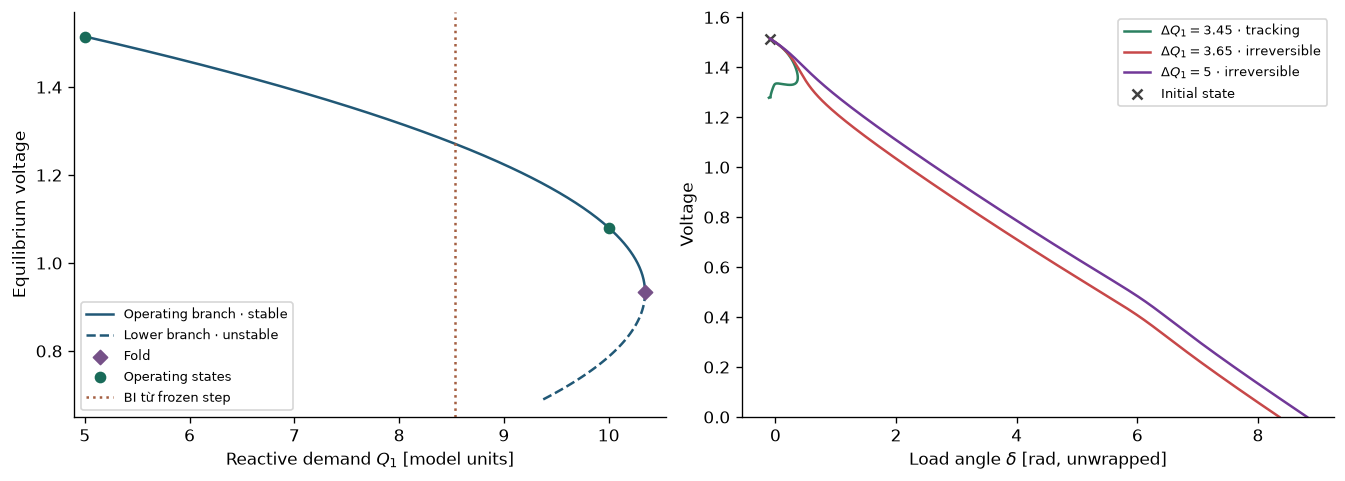

BI bracket của frozen step là [3.52849283, 3.52849288]. Frozen step $\Delta Q_1=5$ chạm $V=0$, dù operating equilibrium tại $Q_1=10$ vẫn stable.

In [73]:
def grid_frozen_step(shift, *, duration=100.0, **settings):
    Q = grid_base_Q + shift
    run = grid_integrate(lambda t: Q, (0.0, duration), grid_base, **settings)
    label, _ = grid_classify(run.y[:, -1], grid_operating(Q), bool(run.t_events[0].size))
    return label, run


def grid_bi_bracket(low, high, *, settings, iterations=22):
    assert grid_frozen_step(low, **settings)[0] == GRID_TRACK
    assert grid_frozen_step(high, **settings)[0] == GRID_COLLAPSE
    for _ in range(iterations):
        mid = (low + high) / 2
        label, _ = grid_frozen_step(mid, **settings)
        if label == GRID_TRACK:
            low = mid
        elif label == GRID_COLLAPSE:
            high = mid
        else:
            break
    return low, high


grid_bi_interval = grid_bi_bracket(3.45, 3.65, settings={"rtol": 1e-9, "atol": 1e-11})
grid_delta_bi = np.mean(grid_bi_interval)
assert grid_delta_bi < 5 < grid_delta_fold
grid_bi_tight = grid_bi_bracket(
    grid_bi_interval[0] - 0.002, grid_bi_interval[1] + 0.002,
    settings={"method": "Radau", "duration": 125.0, "rtol": 5e-10, "atol": 5e-12},
    iterations=10,
)
assert abs(np.mean(grid_bi_tight) - grid_delta_bi) < 5e-5

fig, axes = plt.subplots(1, 2, figsize=(11.1, 3.9), layout="constrained")
ax, ax_phase = axes
for mask, linestyle, label in ((operating_side, "-", "Operating branch · stable"),
                               (~operating_side, "--", "Lower branch · unstable")):
    ax.plot(grid_branch_q[mask], grid_voltages[mask], linestyle=linestyle, label=label, color="#215876")
ax.scatter(grid_fold_Q, grid_fold_state[3], marker="D", color="#765188", label="Fold", zorder=5)
ax.scatter([5, 10], [grid_base[3], grid_operating(10)[3]],
           color="#196b59", label="Operating states", zorder=6)
ax.axvline(grid_base_Q + grid_delta_bi, ls=":", color="#a45f41", label="BI từ frozen step")
ax.set(xlabel=r"Reactive demand $Q_1$ [model units]", ylabel="Equilibrium voltage",
       xlim=(4.9, 10.55), ylim=(0.65, 1.57))
ax.legend()
for shift, color in ((3.45, "#2b8060"), (3.65, "#c74849"), (5, "#713898")):
    label, run = grid_frozen_step(shift, dense_output=True, duration=100.0)
    time = np.linspace(0, min(1.0, run.t[-1]), 850)
    state = run.sol(time)
    ax_phase.plot(state[2], state[3], color=color,
                  label=rf"$\Delta Q_1={shift:g}$ · {grid_outcomes[label]}")
ax_phase.scatter(grid_base[2], grid_base[3], color="0.25", marker="x", label="Initial state")
ax_phase.set(xlabel=r"Load angle $\delta$ [rad, unwrapped]", ylabel="Voltage",
             ylim=(0, 1.62))
ax_phase.legend()
plt.show()
display(Markdown(
    f"BI bracket của frozen step là [{grid_bi_interval[0]:.8f}, {grid_bi_interval[1]:.8f}]. "
    r"Frozen step $\Delta Q_1=5$ chạm $V=0$, dù operating equilibrium tại $Q_1=10$ vẫn stable."
))

*Hình 8.1.* Operating branch giữ stability tới gần fold trong miền đã lấy mẫu. Một frozen jump lớn hơn BI đưa initial state ra khỏi basin của operating state cuối. Phép chiếu hai chiều chỉ hiển thị các trajectories kiểm tra. Việc xác định toàn bộ basin boundary và critical edge state trong hệ 4D cần phân tích riêng.

### 8.7–8.8. Figure 6(a,b) — Demand và voltage response

**Original Reproduction theo Appendix A5.** Dùng $T=0.15$, $Q_{1-}=5$, $\Delta Q_1=5$, $r=50,130,400$ và initial condition là nghiệm cân bằng tính ở trên. Tái sử dụng ramp và symmetric return của Appendix A1. Cửa sổ Figure 6 kết thúc ở $t=0.55$ nhưng phân loại chạy sâu hơn để kiểm tra recovery. Mã gốc khởi tạo tại $\tau=t-T=-1$ bằng vector ghi sẵn và tích phân $Q_1$ qua đạo hàm. Tích phân trực tiếp 4D với $Q_1(t)$ tường minh giữ peak đúng công thức. Phép đối chiếu riêng bên dưới dùng vector và thời điểm bắt đầu của script.

In [74]:
grid_rates6 = (50.0, 130.0, 400.0)
grid_shift6, grid_T6 = 5.0, 0.15
grid_colors6 = ("#1c65ac", "#d97825", "#986193")
grid_profiles = ("ramp", "return")
grid_run6 = {
    (rate, profile): grid_run(grid_shift6, rate, profile, T=grid_T6, dense_output=True)
    for rate in grid_rates6 for profile in grid_profiles
}

rows6 = [r"| Rate $r$ | Ramp | Return | $\min V$ return | Winding return $(k_m,k)$ |",
         "|---:|:---|:---|---:|:---|"]
for rate in grid_rates6:
    ramp, pulse = [grid_run6[rate, profile] for profile in grid_profiles]
    rows6.append(f"| {rate:g} | {grid_outcomes[ramp['label']]} | {grid_outcomes[pulse['label']]} "
                 f"| {max(0, pulse['minimum_V']):.6f} | {pulse['winding']} |")
display(Markdown("\n".join(rows6)))
assert [grid_run6[rate, "ramp"]["label"] for rate in grid_rates6] == [GRID_COLLAPSE] * 3
assert [grid_run6[rate, "return"]["label"] for rate in grid_rates6] == [
    GRID_COLLAPSE, GRID_RECOVER, GRID_TRACK,
]

grid_slow_time = -1.0 / np.max(grid_base_eigs.real)
grid_fast_time = -1.0 / np.min(grid_base_eigs.real)
display(Markdown(f"Linear decay times tại base trải từ {grid_fast_time:.4g} "
                 f"đến {grid_slow_time:.3g} đơn vị thời gian mô hình. "
                 "Inverse rates của Figure 6 là 0.02, 0.00769 và 0.0025."))

| Rate $r$ | Ramp | Return | $\min V$ return | Winding return $(k_m,k)$ |
|---:|:---|:---|---:|:---|
| 50 | irreversible | irreversible | 0.000000 | None |
| 130 | irreversible | reversible | 0.479707 | [0 1] |
| 400 | irreversible | tracking | 1.408415 | [0 0] |

Linear decay times tại base trải từ 0.002279 đến 7.98 đơn vị thời gian mô hình. Inverse rates của Figure 6 là 0.02, 0.00769 và 0.0025.

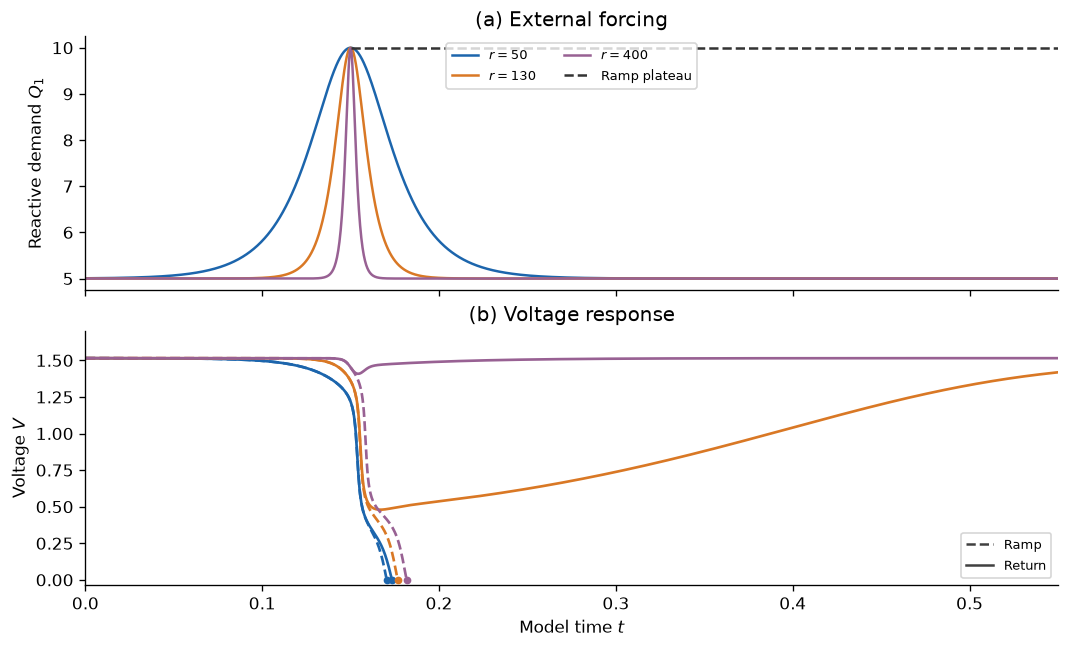

In [75]:
def grid_plot_forcing_and_response(ax_Q, ax_V):
    time = np.linspace(0.0, 0.55, 1601)
    tau = time - grid_T6
    for rate, color in zip(grid_rates6, grid_colors6):
        pulse = grid_run6[rate, "return"]
        ax_Q.plot(time, pulse["demand"](tau), color=color, label=f"$r={rate:g}$")
        for profile, ls in zip(grid_profiles, ("--", "-")):
            run = grid_run6[rate, profile]
            ax_V.plot(time, grid_sample(run, tau)[3], ls=ls, color=color, lw=1.6)
            if run["event"].size and run["event"][0] + grid_T6 <= time[-1]:
                ax_V.scatter(run["event"][0] + grid_T6, 0.0, color=color, s=13, zorder=4)
    ax_Q.hlines(10.0, grid_T6, time[-1], color="0.2", ls="--", label="Ramp plateau")
    ax_Q.set(xlim=(0, 0.55), ylabel=r"Reactive demand $Q_1$", title="(a) External forcing")
    ax_V.set(xlim=(0, 0.55), ylim=(-0.035, 1.7), xlabel="Model time $t$", ylabel="Voltage $V$",
             title="(b) Voltage response")
    ax_Q.legend(loc="upper center", ncol=2)
    ax_V.legend(handles=[Line2D([], [], color="0.25", ls=ls, label=profile.title())
                         for profile, ls in zip(grid_profiles, ("--", "-"))],
                loc="lower right")


fig, axes = plt.subplots(2, 1, figsize=(8.8, 5.3), sharex=True, layout="constrained")
grid_plot_forcing_and_response(*axes)
plt.show()

*Figure 6(a,b).* Ba ramps lên tới $Q_1=10$ rồi duy trì demand cao, và cả ba chạm $V=0$ dù peak thấp hơn fold. Return chậm vẫn chạm zero. Return trung gian hạ áp sâu và hồi phục. Return nhanh cho excursion nhỏ hơn và về đúng lift của initial base state. Sự khác biệt liên quan tới độ dài xung so với modes nội tại. Các rates lớn theo time unit của mô hình này vì sự cố diễn ra trên cửa sổ thời gian ngắn của nó.

### 8.9. Phase slip, voltage collapse và recovery

**Additional Experiment.** So sánh $V,\delta,\delta_m,\omega_m$ ở ba return cases. Đánh dấu voltage minimum của $r=130$ và thời điểm trở lại trong 5% của base voltage trên cửa sổ vẽ. Ngưỡng 5% chỉ định vị recovery trong visualization. Outcome được xét riêng bằng terminal event hoặc convergence trong cả bốn tọa độ.

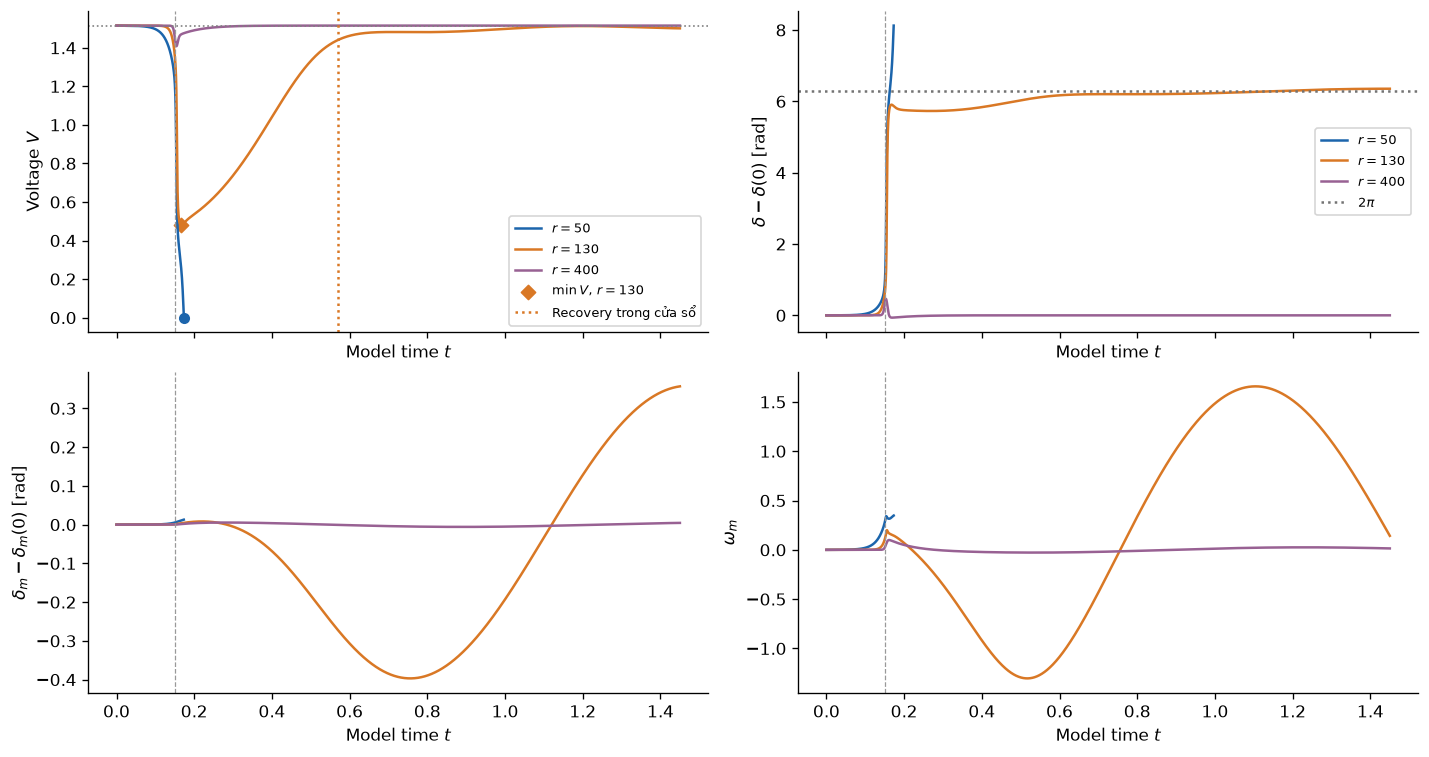

| Return $r$ | Voltage tối thiểu | Max voltage deviation | Kết quả |
|---:|---:|---:|:---|
| 50 | 0.000000 | 1.515066 | irreversible |
| 130 | 0.479707 | 1.035359 | reversible |
| 400 | 1.408415 | 0.106651 | tracking |

$r=130$ có voltage minimum gần $t=0.16675$ và recovery theo chỉ báo trên tại $t=0.56898$. Dịch chuyển cuối của load angle là 6.28318531 rad. Infinity norm của 4D residual so với lift đã dịch là 3.97e-08.

In [76]:
grid_detail_t = np.linspace(0.0, 1.45, 5001)
grid_detail_tau = grid_detail_t - grid_T6
grid_pulse_paths = {rate: grid_sample(grid_run6[rate, "return"], grid_detail_tau)
                    for rate in grid_rates6}
mid = grid_pulse_paths[130.0]
i_min = np.argmin(mid[3])
i_recovery = np.flatnonzero(
    (np.arange(grid_detail_t.size) > i_min)
    & (np.maximum.accumulate(np.abs(mid[3, ::-1] - grid_base[3]))[::-1] <= 0.05 * grid_base[3])
)
assert i_recovery.size
grid_recovery_t = grid_detail_t[i_recovery[0]]
grid_mid_end = grid_run6[130.0, "return"]["state"]
grid_mid_difference, grid_mid_winding = grid_equivalence(grid_mid_end, grid_base)
np.testing.assert_array_equal(grid_mid_winding, [0, 1])
np.testing.assert_allclose(grid_mid_end[2] - grid_base[2], 2 * np.pi, atol=2e-4)

fig, axes = plt.subplots(2, 2, figsize=(11.8, 6.2), sharex=True, layout="constrained")
for rate, color in zip(grid_rates6, grid_colors6):
    pulse = grid_run6[rate, "return"]
    states = grid_pulse_paths[rate]
    for ax, index in zip(axes.flat, (3, 2, 0, 1)):
        values = states[index] - grid_base[index] if index in grid_phase_indices else states[index]
        ax.plot(grid_detail_t, values, color=color, label=f"$r={rate:g}$")
    if pulse["event"].size:
        axes[0, 0].scatter(pulse["event"][0] + grid_T6, 0, color=color, s=32, zorder=4)

axes[0, 0].axhline(grid_base[3], color="0.5", ls=":", lw=1)
axes[0, 0].scatter(grid_detail_t[i_min], mid[3, i_min], c="#d97825", marker="D",
                   label=r"$\min V$, $r=130$")
axes[0, 0].axvline(grid_recovery_t, color="#d97825", ls=":", label="Recovery trong cửa sổ")
axes[0, 0].legend(loc="lower right")
axes[0, 1].axhline(2 * np.pi, color="0.45", linestyle=":", label=r"$2\pi$")
axes[0, 1].legend(loc="center right")
for ax, ylabel in zip(axes.flat, ("Voltage $V$", r"$\delta-\delta(0)$ [rad]",
                                  r"$\delta_m-\delta_m(0)$ [rad]", r"$\omega_m$")):
    ax.set(ylabel=ylabel, xlabel="Model time $t$")
    ax.axvline(grid_T6, color="0.6", ls="--", lw=0.75)
plt.show()

metric_rows = ["| Return $r$ | Voltage tối thiểu | Max voltage deviation | Kết quả |",
               "|---:|---:|---:|:---|"]
for rate in grid_rates6:
    pulse = grid_run6[rate, "return"]
    vmin = max(0.0, pulse["minimum_V"])
    vmax = max(segment.y[3].max() for segment in pulse["segments"])
    deviation = max(grid_base[3] - vmin, vmax - grid_base[3])
    metric_rows.append(f"| {rate:g} | {vmin:.6f} | {deviation:.6f} | {grid_outcomes[pulse['label']]} |")
display(Markdown("\n".join(metric_rows)))
display(Markdown(
    f"$r=130$ có voltage minimum gần $t={grid_detail_t[i_min]:.5f}$ và recovery theo "
    f"chỉ báo trên tại $t={grid_recovery_t:.5f}$. "
    f"Dịch chuyển cuối của load angle là {grid_mid_end[2] - grid_base[2]:.8f} rad. "
    f"Infinity norm của 4D residual so với lift đã dịch là {np.max(np.abs(grid_mid_difference)):.2e}."
))

*Hình 8.2.* Voltage của $r=130$ hồi phục, trong khi $\delta$ kết thúc cao hơn một vòng. $\delta_m$ dao động trong transient và có winding zero ở nghiệm cuối. Phép đo phase displacement phân biệt được phase-slip tipping với tracking khi chỉ nhìn voltage cuối sẽ thấy cùng một operating voltage. Return $r=400$ vẫn có đáp ứng ngắn hữu hạn rồi trở về lift cũ. Return $r=50$ dừng tại biên vật lý.

### 8.10. Outcome classifier và numerical convergence

- **Tracking.** Sau khi forcing đủ gần asymptotic level, state nằm trong tolerance của operating equilibrium cuối với winding $(0,0)$.
- **Reversible.** State hồi phục về operating equilibrium cuối modulo $2\pi$ và winding khác zero. Ca Figure 6 có voltage excursion rõ ràng. Nhãn dựa vào hội tụ và phase displacement, trong khi độ sâu của excursion là diagnostic bổ sung.
- **Irreversible.** Phát hiện terminal event $V=0$ theo chiều đi xuống, như mã boundary của tác giả. Nếu forcing vượt fold, nhãn này mô tả outcome. Cơ chế có thể liên quan đến bifurcation.
- **Unresolved.** Không phát hiện event và chưa đủ gần operating equilibrium trong thời gian thư giãn. Trường hợp này giữ nguyên nhãn khi lên diagram.

Tolerance dùng infinity norm của sai khác 4D sau khi khử winding, theo model units. Kết thúc forcing, kiểm tra ở nhiều relaxation checkpoints. Với return, bắt đầu đoạn kiểm tra sau khi đuôi forcing nhỏ hơn $10^{-9}$ lần peak shift. Classifier theo lift cuối nhận biết net phase slip. Nếu một trajectory đi rồi đảo chiều đúng về lift cũ, cần thêm event theo từng lần quay để phân tích kiểu transient đó.

**Numerical verification.** So sánh 6 outcomes bằng hai integrators với thời gian và step limits khác nhau. Đối chiếu đường $r=130$ return với RK45, max step $10^{-4}$ và initial state làm tròn bắt đầu ở $\tau=-1$ của mã vẽ gốc.

In [77]:
grid_strict6 = {
    "method": "Radau", "rtol": 3e-9, "atol": 3e-11, "phase_step": 0.20,
    "settle": (15.0, 65.0, 155.0), "tolerance": 1e-4,
}
grid_differences6 = []
grid_event_differences6 = []
for (rate, profile), standard in grid_run6.items():
    tighter = grid_run(grid_shift6, rate, profile, T=grid_T6, dense_output=True, **grid_strict6)
    assert tighter["label"] == standard["label"]
    if standard["winding"] is not None:
        np.testing.assert_array_equal(tighter["winding"], standard["winding"])
    end = min(0.4, standard["segments"][-1].t[-1], tighter["segments"][-1].t[-1])
    tau = np.linspace(-grid_T6, end, 700)
    error = np.max(np.abs(grid_sample(standard, tau) - grid_sample(tighter, tau)))
    grid_differences6.append(error)
    if standard["event"].size:
        grid_event_differences6.append(abs(tighter["event"][0] - standard["event"][0]))
assert max(grid_differences6) < 4e-4
assert max(grid_event_differences6) < 2e-5

ref_rate = 130.0
reference = grid_integrate(
    lambda tau: external_forcing(tau, grid_base_Q, 5.0, ref_rate, 0.0, "return")
    - 5.0 * sech(ref_rate),
    (-1.0, 0.4), grid_script_initial, method="RK45", max_step=1e-4,
    rtol=1e-3, atol=1e-6, dense_output=True,
)
compare_tau = np.linspace(-grid_T6, 0.4, 900)
grid_max_reference_V = float(np.max(np.abs(
    reference.sol(compare_tau)[3] - grid_sample(grid_run6[ref_rate, "return"], compare_tau)[3]
)))
display(Markdown(
    f"Cả sáu classifications nhất quán giữa LSODA và Radau. "
    f"Max state difference {max(grid_differences6):.3e}. "
    f"Max event-time difference {max(grid_event_differences6):.3e}. "
    f"Ở $r=130$ return, khác biệt voltage lớn nhất khi dùng cấu hình khởi tạo script "
    f"trên cửa sổ vẽ là {grid_max_reference_V:.4g}."
))

Cả sáu classifications nhất quán giữa LSODA và Radau. Max state difference 4.772e-06. Max event-time difference 2.991e-09. Ở $r=130$ return, khác biệt voltage lớn nhất khi dùng cấu hình khởi tạo script trên cửa sổ vẽ là 0.00961.

### 8.11. Figure 6(c) — Systematic parameter exploration

**Approximate Reproduction.** Mã tác giả nạp các mảng MAT đã tính bằng continuation và bisection, rồi vẽ trong $\Delta Q_1\in[3,7]$, $r\in[1,1000]$. Notebook quét lại theo magnitude tuyến tính và rate log, từ $17\times25$ lên $33\times49$. Lấy $T=\operatorname{arcosh}(10^5)/r$ để $a(0)=10^{-5}\le10^{-2}$ theo giới hạn Appendix A5. Mỗi ô tích phân cả hai profiles, lưu outcome, final state, minimum voltage và event time cùng metadata. Các contour được nội suy từ categorical transitions. Refine thêm critical rates trên các lát cắt từ lưới. [Appendix A5 và Figure 6](https://doi.org/10.5194/esd-14-669-2023) · [Mã vẽ](https://github.com/hassanalkhayuon/rtippingreview/blob/main/Power_grid_model_plotting_critical_boundaries_regions_P5_v3.py)

In [78]:
from inspect import getsource

grid_sweep_settings = {
    "initial_tail": 1e-5, "final_tail": 1e-9, "phase_step": 0.45,
    "settle": (8.0, 35.0, 110.0), "tolerance": 1e-3,
    "method": "LSODA", "rtol": 3e-8, "atol": 3e-10,
}
grid_sweep_shifts = np.linspace(3.0, 7.0, 33)
grid_sweep_rates = np.geomspace(1.0, 1000.0, 49)
grid_profiles = ("ramp", "return")


def grid_scan(shifts, rates, settings, *, seed=None):
    shape = (2, len(rates), len(shifts))
    labels = np.full(shape, -2, dtype=np.int8)
    ends = np.full(shape + (4,), np.nan)
    min_voltage = np.full(shape, np.nan)
    event_time = np.full(shape, np.nan)
    if seed is not None:
        indices = np.ix_(range(2), np.searchsorted(rates, seed["rates"]),
                         np.searchsorted(shifts, seed["shifts"]))
        labels[indices] = seed["labels"]
        ends[indices] = seed["ends"]
        min_voltage[indices] = seed["min_voltage"]
        event_time[indices] = seed["event_time"]
    for p, i, j in np.argwhere(labels == -2):
        run = grid_run(shifts[j], rates[i], grid_profiles[p], **settings)
        labels[p, i, j] = run["label"]
        ends[p, i, j] = run["state"]
        min_voltage[p, i, j] = max(0.0, run["minimum_V"])
        if run["event"].size:
            event_time[p, i, j] = run["event"][0]
    return {"shifts": shifts, "rates": rates, "labels": labels, "ends": ends,
            "min_voltage": min_voltage, "event_time": event_time}


def grid_cached_scan(name, shifts, rates, settings, *, seed=None):
    metadata = json.dumps({
        "model": "Ritchie 2023 Figure 6 three-bus", "parameters": grid_parameters,
        "settings": settings, "profiles": grid_profiles, "numpy": np.__version__,
        "scipy": scipy.__version__, "initial": grid_base.tolist(),
        "outcome_codes": grid_outcomes,
    }, sort_keys=True)
    functions = (sech, ramp_profile, return_profile, external_forcing, minimum_peak_time,
                 grid_powers, grid_frozen, grid_jacobian, grid_branch_at_voltage, grid_operating,
                 grid_voltage_event, grid_integrate, grid_equivalence, grid_classify,
                 grid_run, grid_scan)
    implementation = "\n".join(getsource(function).strip() for function in functions)
    key = sha256(metadata.encode() + implementation.encode() + shifts.tobytes() + rates.tobytes())
    path = sweep_cache_dir / f"final-grid-{name}-{key.hexdigest()[:16]}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as data:
            assert data["metadata"].item() == metadata
            return {key: data[key] for key in data.files if key != "metadata"}, path

    results = grid_scan(shifts, rates, settings, seed=seed)
    path.parent.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(dir=path.parent, delete=False) as temporary_file:
        temporary_path = Path(temporary_file.name)
        np.savez_compressed(temporary_file, metadata=metadata, **results)
    try:
        temporary_path.replace(path)
    finally:
        temporary_path.unlink(missing_ok=True)
    return results, path


def grid_sweep_results():
    coarse, coarse_file = grid_cached_scan(
        "coarse", grid_sweep_shifts[::2], grid_sweep_rates[::2], grid_sweep_settings,
    )
    fine, fine_file = grid_cached_scan(
        "fine", grid_sweep_shifts, grid_sweep_rates, grid_sweep_settings, seed=coarse,
    )
    np.testing.assert_array_equal(fine["labels"][:, ::2, ::2], coarse["labels"])
    assert np.isfinite(fine["ends"]).all()
    assert np.all(fine["min_voltage"] >= 0)
    assert np.array_equal(np.isfinite(fine["event_time"]), fine["labels"] == GRID_COLLAPSE)
    assert set(np.unique(fine["labels"])) <= set(grid_outcomes)
    return coarse, fine, coarse_file, fine_file

In [79]:
grid_coarse6, grid_fine6, grid_coarse_file, grid_fine_file = grid_sweep_results()
grid_pair_counts = np.unique(grid_fine6["labels"].reshape(2, -1), axis=1, return_counts=True)
grid_counts6 = ["| Ramp | Return | Số ô |", "|:---|:---|---:|"]
for pair, count in zip(grid_pair_counts[0].T, grid_pair_counts[1]):
    grid_counts6.append(f"| {grid_outcomes[pair[0]]} | {grid_outcomes[pair[1]]} | {count:,} |")
display(Markdown("\n".join(grid_counts6)))
display(Markdown(f"Fine grid gồm {grid_fine6['labels'].size:,} outcomes. "
                 f"Cache {grid_fine_file.name}."))

| Ramp | Return | Số ô |
|:---|:---|---:|
| tracking | tracking | 655 |
| irreversible | tracking | 434 |
| irreversible | reversible | 203 |
| irreversible | irreversible | 325 |

Fine grid gồm 3,234 outcomes. Cache final-grid-fine-1caf0ceb8e3715ba.npz.

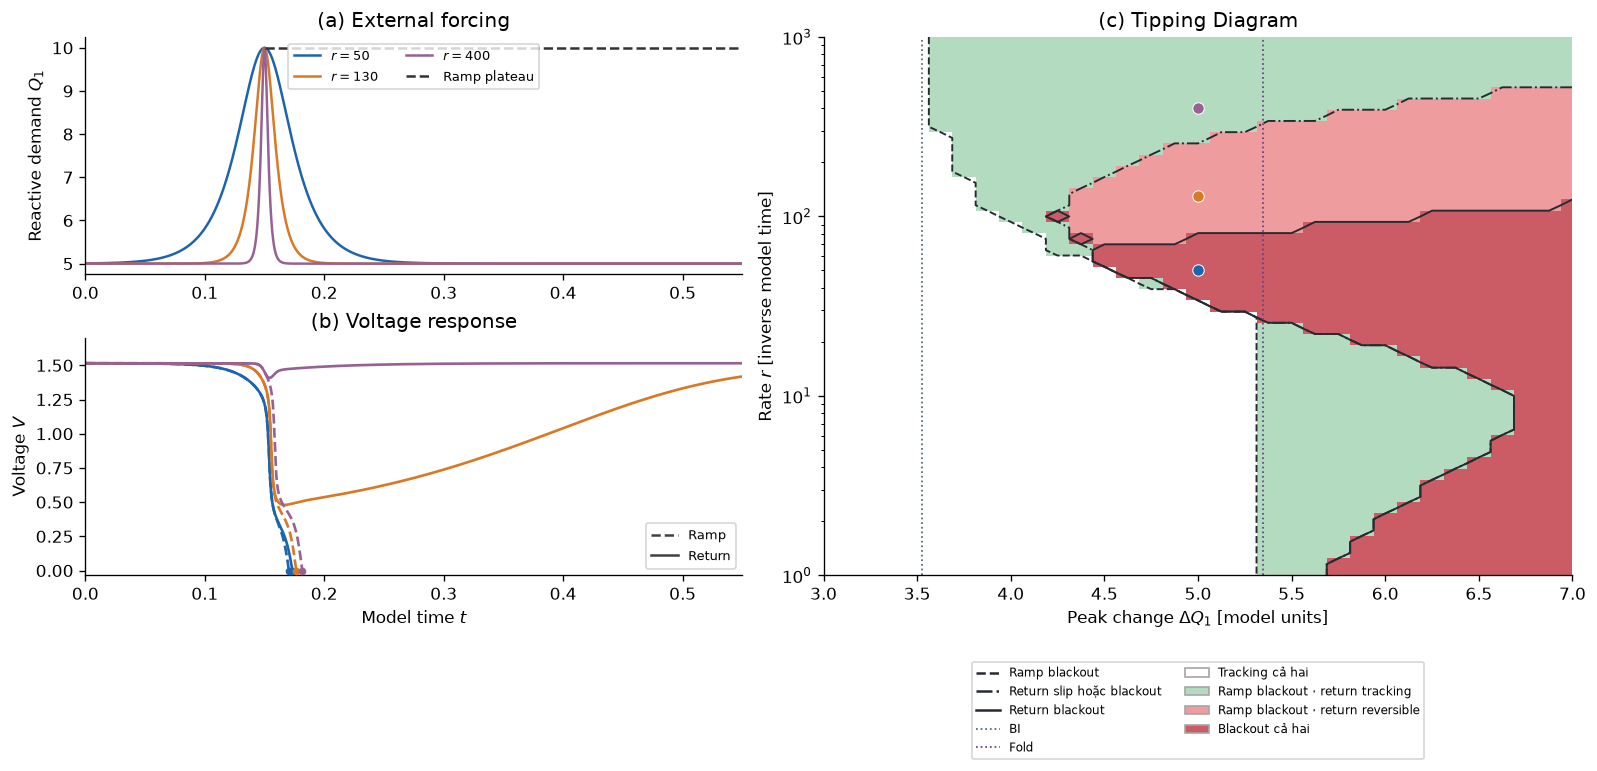

In [80]:
grid_named_regions = {
    (GRID_TRACK, GRID_TRACK): ("Tracking cả hai", "#ffffff"),
    (GRID_COLLAPSE, GRID_TRACK): ("Ramp blackout · return tracking", "#b3dbc0"),
    (GRID_COLLAPSE, GRID_RECOVER): ("Ramp blackout · return reversible", "#ef9c9e"),
    (GRID_COLLAPSE, GRID_COLLAPSE): ("Blackout cả hai", "#cb5b65"),
}


def grid_region_map(labels):
    ramp, pulse = labels
    pairs = np.unique(labels.reshape(2, -1), axis=1).T
    styles = dict(grid_named_regions)
    joint = np.full(ramp.shape, -1, dtype=int)
    names, colors = [], []
    extra_colors = plt.get_cmap("tab20c").colors
    for p, q in map(tuple, pairs):
        if GRID_UNKNOWN in (p, q):
            name, color = "Unresolved", "#ced1d9"
        else:
            name, color = styles.get(
                (p, q), (f"Ramp {grid_outcomes[p]} · return {grid_outcomes[q]}",
                         extra_colors[len(names) % len(extra_colors)]),
            )
        if name not in names:
            names.append(name)
            colors.append(color)
        joint[(ramp == p) & (pulse == q)] = names.index(name)
    return joint, names, colors


def plot_grid_diagram(ax, data, *, title="(c) Tipping Diagram"):
    shifts, rates = data["shifts"], data["rates"]
    ramp, pulse = data["labels"]
    joint, names, colors = grid_region_map(data["labels"])
    cmap = ListedColormap(colors)
    ax.pcolormesh(shifts, rates, joint, shading="nearest", cmap=cmap,
                  norm=BoundaryNorm(np.arange(cmap.N + 1) - 0.5, cmap.N))
    for label, valid, mask, ls in (
        ("Ramp blackout", ramp >= 0, ramp == GRID_COLLAPSE, "--"),
        ("Return slip hoặc blackout", pulse >= 0, pulse >= GRID_RECOVER, "-."),
        ("Return blackout", pulse >= 0, pulse == GRID_COLLAPSE, "-"),
    ):
        boundary = np.ma.array(mask.astype(float), mask=~valid)
        if np.any(boundary == 0.0) and np.any(boundary == 1.0):
            ax.contour(shifts, rates, boundary, levels=[0.5], colors="#262b31",
                       linestyles=ls, linewidths=1.15, corner_mask=False)
        ax.plot([], [], color="#262b31", ls=ls, label=label)
    ax.axvline(grid_delta_bi, color="#526977", ls=":", lw=1.05, label="BI")
    ax.axvline(grid_delta_fold, color="#654283", ls=":", lw=1.05, label="Fold")
    for rate, color in zip(grid_rates6, grid_colors6):
        ax.scatter(grid_shift6, rate, s=47, color=color, edgecolor="white", lw=0.6, zorder=5)
    ax.set(yscale="log", xlim=(3, 7), ylim=(1, 1000),
           xlabel=r"Peak change $\Delta Q_1$ [model units]",
           ylabel=r"Rate $r$ [inverse model time]", title=title)
    handles, _ = ax.get_legend_handles_labels()
    handles += [Patch(facecolor=color, edgecolor="0.65", label=name)
                for name, color in zip(names, colors)]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.15),
              ncol=2, fontsize=7)


fig = plt.figure(figsize=(13.2, 6.3), layout="constrained")
layout = fig.add_gridspec(2, 2, width_ratios=[1, 1.14])
ax_Q6 = fig.add_subplot(layout[0, 0])
ax_V6 = fig.add_subplot(layout[1, 0], sharex=ax_Q6)
grid_plot_forcing_and_response(ax_Q6, ax_V6)
plot_grid_diagram(fig.add_subplot(layout[:, 1]), grid_fine6)
plt.show()

*Figure 6 tái tạo.* Màu trắng/xanh/đỏ nhạt/đỏ đậm phân biệt bốn cặp outcomes qua terminal states đã tính. Đường đứt là ramp blackout. Return có thêm biên giữa recovery có phase slip và tracking. Bên trái fold, $\Delta Q_1=5$ giữ operating branch còn tồn tại và cả ba điểm vẫn có ramp blackout. Bên phải fold, plateau ramp vượt điểm mất branch, nên cần xét cả bifurcation và dynamics khi diễn giải. Các chi tiết nhỏ quanh giao của curves phụ thuộc grid và cách phân loại, nên so với Figure 6 gốc theo vùng và các lát cắt đã kiểm tra. [Figure 6 gốc](../paper/23%20Rate-induced%20tipping%20in%20natural%20and%20human%20systems.pdf#page=9)

**Critical-rate refinement.** Ở $\Delta Q_1=5$ và $6$, tìm các cặp rates lân cận có đổi outcome trong fine grid. Bisection theo log-rate cho từng bracket. Khi phát hiện nhãn resolved thứ ba trong bracket, tách làm hai trước khi tiếp tục. Nếu có unresolved ở midpoint, giữ interval thô đã xác minh. Kiểm tra các outcomes ngay hai phía bằng tolerance nhỏ hơn và thời gian settle dài hơn.

In [81]:
def grid_refine_transitions(evaluate, brackets, *, width=4e-4):
    refined = []
    pending = list(brackets)
    while pending:
        low, high, left, right = pending.pop(0)
        if high / low - 1 <= width:
            refined.append((low, high, left, right))
            continue
        midpoint = np.sqrt(low * high)
        middle = evaluate(midpoint)
        if middle == GRID_UNKNOWN:
            refined.append((low, high, left, right))
            continue
        if left != middle:
            pending.append((low, midpoint, left, middle))
        if middle != right:
            pending.append((midpoint, high, middle, right))
    return sorted(refined)


def grid_critical_rates(shift, profile, grid, *, settings):
    j = np.argmin(np.abs(grid["shifts"] - shift))
    np.testing.assert_allclose(grid["shifts"][j], shift, atol=1e-12)
    p = grid_profiles.index(profile)
    brackets = transition_brackets(grid["rates"], grid["labels"][p, :, j])

    def evaluate(rate):
        return grid_run(shift, rate, profile, **settings)["label"]

    return grid_refine_transitions(evaluate, brackets)


grid_slices6 = {(shift, profile): grid_critical_rates(shift, profile, grid_fine6,
                                                       settings=grid_sweep_settings)
                for shift, profile in ((5.0, "ramp"), (5.0, "return"), (6.0, "return"))}
rows_rates6 = ["| Peak shift | Profile | Transition khi $r$ tăng | Critical rate | Bracket |",
               "|---:|:---|:---|---:|:---|"]
grid_boundary_checks = []
grid_boundary_settings = {
    **grid_sweep_settings, "rtol": 2e-9, "atol": 2e-11, "phase_step": 0.23,
    "settle": (12.0, 55.0, 150.0), "tolerance": 2e-4,
}
for (shift, profile), intervals in grid_slices6.items():
    for j, (low, high, left, right) in enumerate(intervals):
        rows_rates6.append(
            f"| {shift:g} | {profile} | {grid_outcomes[left]} → {grid_outcomes[right]} "
            f"| {np.sqrt(low * high):.6g} | [{low:.6g}, {high:.6g}] |"
        )
        # Probe stays inside its outcome band, even when two boundaries are close.
        left_probe = low / 1.006
        right_probe = high * 1.006
        if j > 0:
            left_probe = max(left_probe, np.sqrt(intervals[j - 1][1] * low))
        if j + 1 < len(intervals):
            right_probe = min(right_probe, np.sqrt(high * intervals[j + 1][0]))
        for rate, target in ((left_probe, left), (right_probe, right)):
            result = grid_run(shift, rate, profile, **grid_boundary_settings)["label"]
            grid_boundary_checks.append(result == target)
display(Markdown("\n".join(rows_rates6)))
display(Markdown(
    f"Kiểm tra bằng tolerance chặt hơn khớp {sum(grid_boundary_checks)}/{len(grid_boundary_checks)} "
    "probe points hai phía của brackets. Probe bị chặn trong dải giữa các ranh giới kề nhau."
))

grid_tight_slices = {
    shift: grid_critical_rates(shift, "return", grid_fine6, settings=grid_boundary_settings)
    for shift in (5.0, 6.0)
}
narrow_rows = ["| Peak shift | Solver | Rate thấp của dải blackout hẹp | Rate cao |",
               "|---:|:---|---:|---:|"]
for shift, slices in grid_tight_slices.items():
    for solver, intervals in (("Baseline", grid_slices6[shift, "return"]),
                              ("Tighter", slices)):
        for first, second in zip(intervals[:-1], intervals[1:]):
            if (first[2:] == (GRID_RECOVER, GRID_COLLAPSE)
                    and second[2:] == (GRID_COLLAPSE, GRID_TRACK)):
                middle = np.sqrt(first[1] * second[0])
                check = grid_run(shift, middle, "return",
                                 **{**grid_boundary_settings, "method": "Radau"})
                assert check["label"] == GRID_COLLAPSE
                narrow_rows.append(f"| {shift:g} | {solver} | {np.sqrt(first[0] * first[1]):.6f} "
                                   f"| {np.sqrt(second[0] * second[1]):.6f} |")
display(Markdown("\n".join(narrow_rows)))

| Peak shift | Profile | Transition khi $r$ tăng | Critical rate | Bracket |
|---:|:---|:---|---:|:---|
| 5 | ramp | tracking → irreversible | 33.8915 | [33.8867, 33.8962] |
| 5 | return | tracking → irreversible | 34.5455 | [34.5406, 34.5503] |
| 5 | return | irreversible → reversible | 76.5548 | [76.544, 76.5655] |
| 5 | return | reversible → irreversible | 263.979 | [263.942, 264.016] |
| 5 | return | irreversible → tracking | 264.202 | [264.165, 264.239] |
| 6 | return | irreversible → tracking | 2.09698 | [2.09669, 2.09727] |
| 6 | return | tracking → irreversible | 17.8203 | [17.8178, 17.8228] |
| 6 | return | irreversible → reversible | 96.5068 | [96.4933, 96.5204] |
| 6 | return | reversible → irreversible | 413.888 | [413.829, 413.946] |
| 6 | return | irreversible → tracking | 414.004 | [413.946, 414.062] |

Kiểm tra bằng tolerance chặt hơn khớp 20/20 probe points hai phía của brackets. Probe bị chặn trong dải giữa các ranh giới kề nhau.

| Peak shift | Solver | Rate thấp của dải blackout hẹp | Rate cao |
|---:|:---|---:|---:|
| 5 | Baseline | 263.979270 | 264.201960 |
| 5 | Tighter | 263.979270 | 264.201960 |
| 6 | Baseline | 413.887513 | 414.003864 |
| 6 | Tighter | 413.887513 | 414.003864 |

Refinement tìm thấy một dải blackout rất hẹp sát ranh giới reversible–tracking, cả ở shift 5 và 6. Điểm bên trong dải được kiểm tra thêm bằng Radau. Midpoints của các brackets trùng nhau ở độ phân giải hiện tại sau khi siết tolerances. Contour của coarse/fine grid toàn miền không phân giải được những dải hẹp này.

### 8.12. Kết luận Module 8

Với $P_1=5$, operating state dưới fold vẫn có thể bị mất tracking khi reactive demand thay đổi nhanh. Frozen-step test kiểm chứng Basin Instability trong miền Figure 6. Đối với return, recovery có hai dạng quan sát được qua winding. Phase-equivalent equilibria vì vậy tạo thêm một vùng reversible tipping so với các mô hình trước. Voltage blackout được xác định tại biên $V=0$ và phần tích phân âm không có diễn giải vật lý. Tipping Diagram là kết quả của classifier 4D và lưu riêng tất cả cặp outcomes, kể cả khi lưới khác cho thêm vùng.

## Module 9 — Cross-model Comparison and Scientific Synthesis

### 9.1–9.2. Đối chiếu bốn mô hình

**Mục tiêu.** Xác định điều kiện nào được kiểm tra chung và cấu trúc động lực nào quyết định hình thức của tipping trong từng mô hình. Các ngưỡng bên dưới gắn với parameter paths và initial states đã khảo sát.

**Mức bằng chứng.** **Số** là kết quả tính và kiểm tra trong notebook. **Paper** là kết luận do nghiên cứu nguồn hỗ trợ. **Chưa khảo sát** là câu hỏi ngoài các phép tính hiện có. **Chưa phân giải** là trường hợp số liệu đã tính còn nhạy với cấu hình.

| Property | Tilted saddle-node | Plant–Herbivore | AMOC | Power grid |
|---|---|---|---|---|
| Model origin | Tilted normal form của Ritchie et al. | Scheffer et al., O’Keeffe & Wieczorek | Wood et al., Alkhayuon et al. | Dobson et al., Dobson & Chiang, Budd & Wilson |
| State-space dimension | 1 | 2 | 2 sau reduction | 4 |
| Governing equation structure | Scalar cubic drift | Logistic growth và non-monotone functional response | Piecewise advection–mixing, bảo toàn muối | Swing equation ghép dynamic load, angles tuần hoàn |
| Base state | Stable $x_+^*$ | Coexistence | AMOC-On | High-voltage equilibrium modulo $2\pi$ |
| Alternative state/outcome | $x=0$ | Plant-only | AMOC-Off | Phase-slip transient hoặc boundary event $V=0$ |
| External forcing | Scalar $\lambda(t)$ | $(\rho,m)$ dọc path | Scalar $H$ điều khiển bốn fluxes | Scalar reactive demand $Q_1(t)$ |
| Relevant bifurcation | **Số.** Fold $\lambda=0$ | **Số.** Coexistence fold | **Số.** Subcritical Hopf rồi upper fold | **Số.** Fold trên branch với $P_1=5$ |
| Basin boundary structure | **Số.** Unstable equilibrium | **Số.** Stable manifold của saddle | **Số.** Repelling cycle tại final hosing | **Số.** Frozen-step đổi outcome. Cấu trúc 4D **chưa khảo sát** |
| Basin Instability evidence | **Số.** Branch crossing tại $\Delta\lambda\approx0.291053$ | **Số.** Frozen test tại $\Delta e\approx0.329860$ | **Số.** Frozen test tại $\Delta H\approx0.361495$ Sv | **Số.** Frozen step sang $V=0$ trước fold |
| Critical edge state | **Số.** Unstable $x_-^*$ | **Số.** Trajectory gần saddle | **Số.** Trajectory gần chu kỳ đã xác minh | **Chưa khảo sát** quỹ đạo tới edge state |
| R-tipping mechanism | **Số.** Mất tracking trong khi base còn stable | **Số.** Coexistence → plant-only dưới fold | **Số.** On → Off dưới Hopf | **Số.** Tracking failure trước fold có thể dẫn tới phase slip hoặc $V=0$ |
| Return forcing behavior | **Số.** Safe overshoot và các cửa sổ tipping | **Số.** Return có thể cứu tracking hoặc vẫn tipping | **Số.** Có nhiều cửa sổ khi return | **Số.** Tracking, reversible hoặc blackout |
| Multiple critical rates | **Số.** Ba tại $\Delta\lambda=0.515$ | **Số.** Hai tại $\Delta e=0.59375$ | **Số.** Ba tại $\Delta H=0.410$ Sv. Biên thấp còn nhạy số | **Số.** Nhiều transitions trên cùng $\Delta Q_1$ với return |
| Reversible tipping | Phase-slip mechanism **chưa khảo sát** | Phase-slip mechanism **chưa khảo sát** | Phase-slip mechanism **chưa khảo sát** | **Số.** Voltage hồi phục, load angle dịch $2\pi$ |
| Irreversible tipping | **Số.** Về $x=0$ dưới profile đã thử | **Số.** Về plant-only | **Số.** Về AMOC-Off | **Số.** Chạm biên $V=0$ |
| Reproduction status | Fig. 2 outcomes và Fig. 3 time series kiểm chứng. Boundary Fig. 3 trên lưới | Fig. 4(a–c) gần đúng. Rate Appendix có sai khác. Fig. 5(a) trên lưới | Fig. 4(d–f) kiểm chứng cycle và bracket. Wiggles Fig. 5(b) **chưa phân giải** | Fig. 6(a,b) khớp outcomes. Fig. 6(c) gần đúng từ lưới độc lập |

### 9.3. Cấu trúc chung và cơ chế riêng

Trong cả bốn ví dụ, state có thể theo moving base state khi ép đủ chậm. Một forcing nhanh hơn có thể làm state đi vào miền động lực khác trong khi frozen base state vẫn tồn tại. BI dùng vị trí của initial base state và frozen basin cuối để nhận diện khả năng đó. Kết luận về một profile và một $r$ cụ thể cần trajectory và outcome độc lập.

Peak change xác định đoạn đường trong parameter space và quan hệ với BI hay bifurcation. Rate cùng temporal profile xác định thời gian hệ ở gần mỗi vùng động lực. Return có thể cứu tracking, hoặc tạo một cửa sổ tipping mới khi rate thay đổi. Multiple transitions được quan sát qua các lát cắt. Số lượng và vị trí phụ thuộc model và profile.

Near-critical behavior phản ánh invariant structures: state có thể đi gần điểm đẩy scalar, saddle 2D hoặc chu kỳ đẩy 2D. Ở power grid, phase symmetry tạo nhiều lifts của operating state, nên voltage recovery vẫn có thể đi kèm winding. Đây là bằng chứng từ các case studies và các miền tham số đã tính. [Section 7](https://doi.org/10.5194/esd-14-669-2023)

### 9.4. So sánh Tipping Diagrams

**Additional Analysis.** Đặt bốn diagrams cạnh nhau để so topology của các vùng, vị trí BI, local bifurcation và những đoạn có nhiều rate transitions. Cell dùng lại arrays đã lưu. Axes giữ units và scales riêng. Đọc boundary structure và outcome combinations, thay vì xếp hạng các mô hình theo giá trị số của $r$.

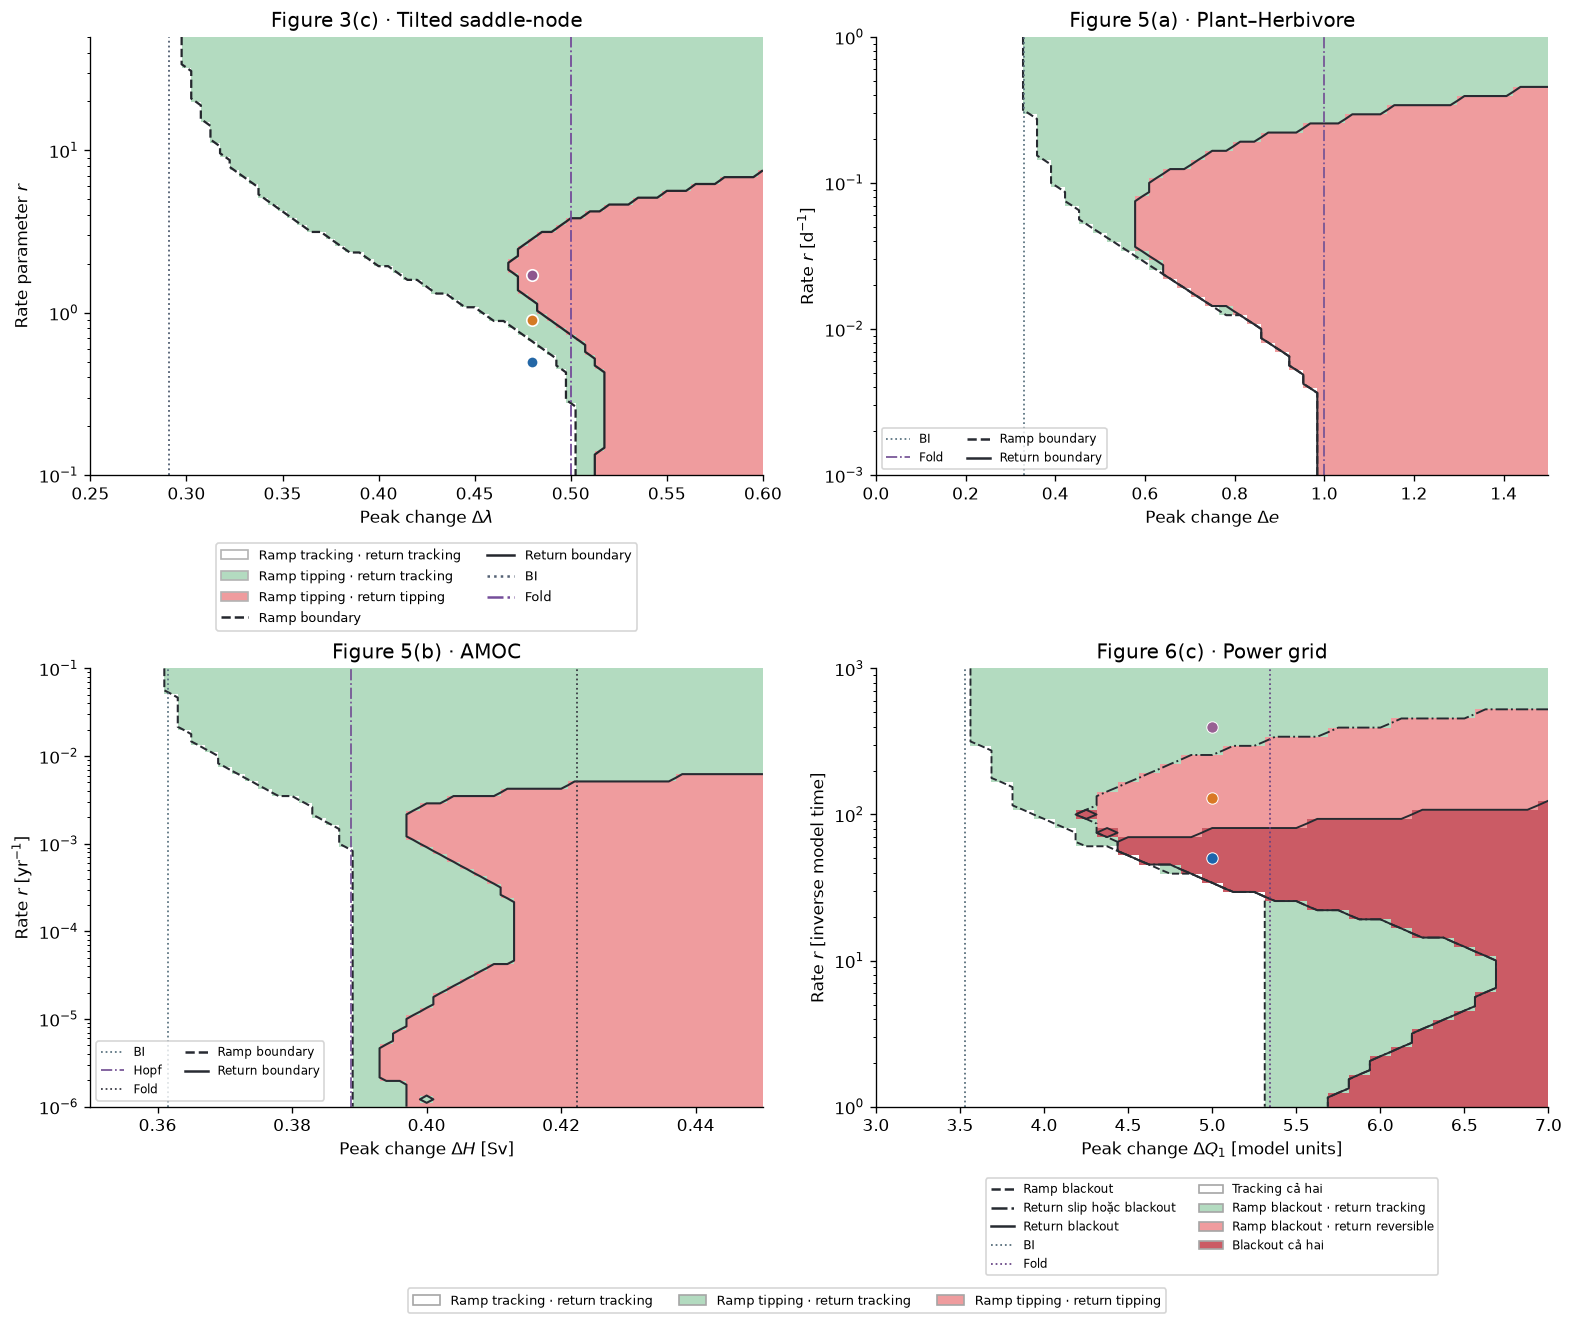

In [82]:
fig, axes = plt.subplots(2, 2, figsize=(13.0, 10.9), layout="constrained")
plot_tipping_diagram(axes[0, 0], shift_grid, rate_grid, outcomes_grid)
axes[0, 0].set_title("Figure 3(c) · Tilted saddle-node")
eco_comparison_regions = plot_application_boundary(
    axes[0, 1], eco_grid5, eco_figure5_markers,
    rate_label=r"Rate $r$ [$\mathrm{d^{-1}}$]", peak_label=r"Peak change $\Delta e$",
    title="Figure 5(a) · Plant–Herbivore",
)
amoc_comparison_regions = plot_application_boundary(
    axes[1, 0], amoc_grid5, amoc_figure5_markers,
    rate_label=r"Rate $r$ [$\mathrm{yr^{-1}}$]", peak_label=r"Peak change $\Delta H$ [Sv]",
    title="Figure 5(b) · AMOC",
)
plot_grid_diagram(axes[1, 1], grid_fine6, title="Figure 6(c) · Power grid")
application_region_legend(fig, eco_comparison_regions, amoc_comparison_regions)
plt.show()

*Hình 9.1. Bốn Tipping Diagrams.* Ở cả bốn trường hợp, một phần ramp tipping xuất hiện giữa BI và local bifurcation. Green regions là nơi return đưa hệ về tracking khi ramp tipping. Return ở plant–herbivore và AMOC có thể tạo dải tipping hữu hạn theo rate. Power grid tách recovery có phase slip thành một vùng riêng. Các contours gần ranh giới là xấp xỉ từ lưới. Plant–Herbivore và AMOC dùng chung legend màu ở dưới figure.

### 9.5. Computational Research Methodology

Workflow này được tổng hợp từ case study. Có thể quay lại phương trình, parameter path hoặc tiêu chí outcome khi numerical evidence chưa đủ.

1. **Research question.** Phát biểu hiện tượng và cơ chế cần phân biệt, chẳng hạn mất branch, basin escape hoặc recovery sau transient.
2. **Model selection.** Chọn existing model có cấu trúc và mức chi tiết đủ để kiểm tra cơ chế. Ghi rõ nguồn, phiên bản và phạm vi dùng tham số.
3. **Mathematical formulation.** Chuẩn hóa notation, units, initial conditions và miền vật lý. So equations của paper với code nguồn và residual checks.
4. **Intrinsic dynamical analysis.** Tìm equilibria, eigenvalues và bifurcations trước. Dùng phase geometry, basins hoặc invariant sets khi chúng giúp phân biệt outcomes.
5. **Potential tipping structures.** So sánh initial state với frozen basin cuối. Chọn threshold theo hệ động lực và xác định mức chắc chắn của bằng chứng.
6. **Research-driven modification.** Chọn structural parameters và forcing inputs có vai trò rõ trong câu hỏi. Chỉ thêm thành phần khi có justification hoặc cần kiểm tra một giả thuyết cụ thể.
7. **Controlled experiments.** Giữ initial condition và peak change rồi thay rate hoặc profile. Dành đủ thời gian sau peak và định nghĩa criteria trước khi đọc outcomes.
8. **Mechanism verification.** So trajectory với equilibrium branch, saddle manifold, periodic orbit hay winding. Kiểm tra lại với solver khác, bước nhỏ hơn hoặc horizon dài hơn.
9. **Systematic exploration.** Quét coarse rồi refine, cache theo tham số và solver, giữ unresolved. Bracket mọi transitions quan sát được trên lát cắt mà không giả định monotonicity.
10. **Cross-model comparison.** So điều kiện hình học, cấu trúc vùng và loại outcomes. Giữ physical units và phân biệt bằng chứng số, bằng chứng nguồn và câu hỏi cần khảo sát.

### 9.6. Kiến thức và kỹ năng đã dùng

Các mục dưới đây mô tả mức triển khai thực tế trong notebook và hướng củng cố.

| Concept | Module | Purpose | Đã triển khai và kiểm chứng | Củng cố |
|---|---|---|---|---|
| Equilibria và stability | 2, 6–8 | Xác định operating points | Residuals và eigenspectra | Equilibria nonhyperbolic |
| Jacobian và eigenvalues | 2, 6–8 | Local linearization | Giải tích và finite differences | Sensitivity và nonnormality |
| Phase line | 2–3 | Chỉ chiều drift và basin | Dấu vector field scalar | Degenerate roots |
| Nullclines và phase portraits | 6–7 | Diễn giải dòng trong 2D | Roots, streamplots, trajectories | Separatrix gần điểm đặc biệt |
| Bifurcation diagrams | 2, 7–8 | Nối branches khi đổi forcing | Analytic parameterization và roots | Pseudo-arclength continuation |
| Fold bifurcation | 2, 6–8 | Xác định mất equilibrium | Double root, turning point và eigenvalue zero | Normal form và delay scaling |
| Hopf bifurcation | 7 | Xác định onset oscillatory instability | Trace, eigenspectrum và repelling cycles | First Lyapunov coefficient |
| Basins of attraction | 3, 6–8 | Liên hệ initial condition với endpoint | Phase line, maps và frozen step | Global boundaries trong 4D |
| Invariant manifolds | 6–7 | Xấp xỉ saddle separatrix | Backward integrations kiểm tra hai phía | Continuation và sai số toàn cục |
| Periodic orbits | 7 | Xác định AMOC edge cycle | Shooting, closure và Floquet multiplier | Continuation đến homoclinic |
| Edge states | 3–4, 6–7 | Giải thích near-critical behavior | Gần unstable point, saddle và cycle | Edge tracking tổng quát |
| Non-autonomous dynamics | 4–8 | Phân biệt x(t) với moving equilibrium | Tích phân ramp và return | Pullback attractors |
| B-tipping | 4–5 | Theo dõi mất branch | Fold event và trajectory delay | Slow passage asymptotics |
| R-tipping | 4, 6–8 | Kiểm tra tipping trước bifurcation | Outcomes khác theo $r$ cùng peak | Điều kiện cần và đủ |
| Threshold Instability | 3, 7–8 | Xét initial state khi threshold di chuyển | Geometry scalar, boundary và projection tests | Thresholds trong excitable systems |
| Basin Instability | 3, 6–8 | Xác định susceptibility | Branch crossing và frozen-step brackets | Độ nhạy với initial condition |
| Tracking failure | 4, 6–8 | So actual trajectory với base | Tracking errors và basin outcomes | Time-dependent basin geometry |
| Critical rates | 5–8 | Ước lượng ranh giới outcome | Log-rate bracketing và sensitivity | Continuation ở nhiều tham số |
| Return tipping | 4 | Kiểm tra đảo chiều rời fold | Ramp giảm, hai outcomes theo rate | Asymmetric forcing |
| Safe overshoot | 5 | Kiểm tra return sau vượt fold | Lát cắt với tracking ở một khoảng rate | Scaling với overshoot duration |
| Multiple critical rates | 5–8 | Phát hiện cửa sổ theo rate | Nhiều brackets ở lát cắt cố định | Narrow-window detection |
| Reversible và irreversible tipping | 8 | Phân biệt recovery với blackout | Winding và event $V=0$ | Zero-net phase excursions |
| Numerical ODE integration | 2, 4–8 | Tính frozen và forced trajectories | Adaptive methods, event, dense output | Stiffness và tolerance control |
| Equilibrium root-finding | 2, 6–8 | Tìm branches từ balances | Roots, polynomial và parameterization | Degenerate folds |
| Stability analysis | 2, 6–8 | Tách stable/saddle/repelling | Analytic Jacobians và spectra | Global stability |
| Numerical basin mapping | 6–7 | Dựng basins theo initial states | Grid integrations và adaptive probes | Adaptive sampling gần boundary |
| Invariant structure approximation | 6–7 | Tính manifold và cycle | Backward method và shooting | Continuation gần homoclinic |
| Critical-rate estimation | 5–8 | Refine brackets từ scans | Bisection với nhãn unresolved | Error bars khi solver nhạy |
| Parameter sweeps | 5–8 | Dựng outcome regions | Coarse/fine arrays được cache | Refine theo curvature |
| Outcome classification | 5–8 | Gán nhãn theo động lực từng model | Terminal attraction, winding, collapse event | Unresolved và competing attractors |
| Tipping Diagram construction | 5–9 | So tổ hợp ramp/return | Categorical maps và contours | Lưới mịn quanh junctions |
| Numerical convergence | 4–8 | Chẩn đoán artefacts | Thay step, tolerance, horizon và resolution | Precision gần separatrix |
| Reproducibility và validation | 5–9 | Lặp lại thí nghiệm đã kiểm tra | Cache provenance, sources, clean execution | Đóng gói môi trường tính toán |

### 9.7. Methodological reflection cho physiological dynamical modeling

Với một existing physiological model, có thể áp dụng cùng workflow để kiểm tra intrinsic dynamics, chọn parameters có physiological meaning, thiết kế forcing có cơ sở, rồi khảo sát bifurcation, thresholds và critical rates. Controlled synthetic time series cho phép thay riêng state dynamics, input, quan sát và noise để đánh giá một phương pháp phân tích có nhận ra cơ chế đã biết hay không.

Latent state $\mathbf{x}(t)$ mô tả variables của mô hình. Tín hiệu đo có dạng
$$y(t)=h(\mathbf{x}(t))+\eta(t).$$
Phép đo $h$ có thể trộn hoặc che một số state variables. Noise, sampling và preprocessing cũng làm thay đổi dấu hiệu quan sát được. Một transition có cơ chế rõ trong mô hình có thể tạo tín hiệu giống một cơ chế khác sau phép đo. Để suy luận từ EEG, ECG hoặc PPG cần một observation model, so sánh các giải thích thay thế và evidence độc lập với synthetic experiments. Phần này dừng ở việc chuyển giao phương pháp cho bối cảnh nghiên cứu sau này.

### 9.8. Scientific limitations

- **Paper gốc.** Các mô hình là conceptual hoặc reduced models và forcings là ramp/return lý tưởng hóa. Section 7 tập trung các cơ chế định tính. Quantitative prediction và empirical verification cần mô hình, dữ liệu và forcing phù hợp hệ thực. [Section 7](https://doi.org/10.5194/esd-14-669-2023)
- **Reproduction.** Lưới hữu hạn có thể bỏ sót một cửa sổ rate hẹp. Finite horizon và tolerance đặc biệt quan trọng gần separatrices, Hopf và critical trajectories. Fig. 5(b) còn có wiggles nhạy số. Các basin maps chỉ kiểm tra trên miền đã lấy mẫu. Global continuation cho AMOC và basin boundary 4D của power grid chưa được xác minh. Figure 4(a–c) có sai khác rate đã ghi rõ. Power-grid contours chỉ có độ chính xác theo lưới và lát cắt đã refine. Các adaptive integrators và cách chọn initial state tạo sai khác nhỏ so với time series gốc.

## Final Notebook Validation

### Reproduction checklist

| Original figure | Module | Reproduction status | Validation method | Remaining discrepancies |
|---|---:|---|---|---|
| Figure 2 | 4 | Successfully reproduced | Năm trajectories, ba cơ chế, fold crossing và convergence dưới hai solver settings | Euler step trong mã gốc tạo sai khác theo thời gian |
| Figure 3 | 5 | Qualitatively reproduced | Khớp ba cặp outcomes tại $\Delta\lambda=0.48$, xác minh ba rate transitions ở lát cắt overshoot | Contours tính lại trên lưới. Vạch BI giải tích lệch khoảng $1.35\times10^{-4}$ so với script |
| Figure 4(a–c) | 6 | Qualitatively reproduced | Stable manifold, saddle approach và tracking/tipping ở rates ngoài critical bracket | Rate gần tới hạn $0.043156$ gần script video. $0.0453$ trong Appendix cho tipping |
| Figure 4(d–f) | 7 | Successfully reproduced | Slow/fast outcomes, shooting và Floquet check, critical trajectory đi gần cycle | Rate làm tròn $0.01645$ nằm phía tipping. Dùng bracket tính lại cho đường gần tới hạn |
| Figure 5(a) | 6 | Qualitatively reproduced | Folds và BI tính độc lập, map hai profiles và kiểm tra hai return critical rates | Boundaries là xấp xỉ từ lưới, chưa so từng điểm với workbook |
| Figure 5(b) | 7 | Partially reproduced | Ranh giới lớn và ba transitions tái lập. Hai rates cao ở lát cắt $0.410$ Sv ổn định | Wiggles ở rate thấp và cửa sổ hẹp nhạy với solver |
| Figure 6 | 8 | Qualitatively reproduced | Cả sáu outcomes qua LSODA/Radau, load-angle winding, $V=0$, BI, fold và bốn vùng | Dùng equilibrium chính xác và dừng ở event. Boundaries tính độc lập. Một số dải hẹp chỉ thấy qua refinement |

### Kiểm tra mathematical và numerical consistency

Các checks tại từng module đối chiếu equations, parameters, initial conditions và profiles với nguồn, rồi so equilibria residuals, stability, terminal outcomes và critical brackets. Để kết thúc, chạy các assertions liên kết giữa modules và xác minh metadata của cached sweeps. Các kết quả nhạy nhất nằm ở rate thấp của AMOC, đường gần tới hạn ở Figure 4 và các dải rất hẹp quanh return boundary Figure 6.

In [83]:
from importlib.metadata import version

assert np.isclose(delta_lambda_bi, 0.291053391, atol=2e-8)
assert observed_figure3 == [("tracking", "tracking"), ("tipping", "tracking"),
                            ("tipping", "tipping")]
assert len(slice_boundaries) == 3
assert eco_bi < eco_peak4 < eco_fold
assert amoc_bi < amoc_peak4 < amoc_hopf < amoc_fold
assert amoc_boundary_final["closure"] < 1e-8 and amoc_boundary_final["multiplier"] > 1
assert grid_delta_bi < grid_shift6 < grid_delta_fold
assert grid_mid_winding.tolist() == [0, 1]
assert len(grid_boundary_checks) > 0

for path, expected_name, expected_parameters, expected_results in (
    (eco_fine_file, "eco-fine", eco_parameters, eco_grid5["outcomes"]),
    (amoc_fine_file, "amoc-fine", amoc_parameters, amoc_grid5["outcomes"]),
):
    with np.load(path, allow_pickle=False) as data:
        metadata = json.loads(data["metadata"].item())
        assert metadata["model"] == expected_name
        assert metadata["parameters"] == json.loads(json.dumps(expected_parameters))
        assert metadata["scipy"] == scipy.__version__
        assert "relaxation" in metadata["settings"]
        np.testing.assert_array_equal(data["outcomes"], expected_results)

with np.load(sweep_cache_dir / fine_cache, allow_pickle=False) as data:
    np.testing.assert_array_equal(data["outcomes"], outcomes_grid)
    np.testing.assert_array_equal(data["shifts"], shift_grid)
    np.testing.assert_array_equal(data["rates"], rate_grid)

with np.load(grid_fine_file, allow_pickle=False) as data:
    metadata = json.loads(data["metadata"].item())
    assert metadata["parameters"] == grid_parameters
    assert metadata["settings"] == json.loads(json.dumps(grid_sweep_settings))
    assert metadata["numpy"] == np.__version__ and metadata["scipy"] == scipy.__version__
    np.testing.assert_array_equal(data["labels"], grid_fine6["labels"])

display(Markdown("Các kiểm tra liên kết giữa modules và cache provenance đã chạy qua."))
env_versions = ["| Thành phần | Phiên bản |", "|---|---|",
                f"| Python | {platform.python_version()} |"]
env_versions += [f"| {package} | {version(package)} |"
                 for package in ("numpy", "scipy", "matplotlib", "ipython", "ipykernel", "nbformat")]
display(Markdown("\n".join(env_versions)))

Các kiểm tra liên kết giữa modules và cache provenance đã chạy qua.

| Thành phần | Phiên bản |
|---|---|
| Python | 3.11.7 |
| numpy | 2.4.6 |
| scipy | 1.17.1 |
| matplotlib | 3.11.2 |
| ipython | 9.17.1 |
| ipykernel | 7.4.0 |
| nbformat | 5.11.1 |

### Clean execution, cache và nguồn

Notebook dùng Python 3 với NumPy, SciPy, Matplotlib và IPython. IPykernel cung cấp Jupyter kernel, còn nbformat dùng để lưu và kiểm tra notebook. Bảng trên ghi các phiên bản thực tế đã chạy. Các figures được nhúng sẵn trong outputs.

Cache nằm ở **results/ritchie_2023/** tính từ workspace root. Có thể chạy từ workspace root hoặc thư mục **Replication_Research/**. Kết quả Module 5, 6–7 và 8 dùng lần lượt các tiền tố **figure3-**, **stage3-** và **final-grid-**. Các cell sweep kiểm tra key dựa trên lưới, tham số, solver và implementation. Nếu cache vắng, cùng cell sẽ tính lại. Dữ liệu MAT/XLSX của tác giả là nguồn đối chiếu thiết kế figures. Các ODE, eigenvalues và sweeps trong notebook tính bằng Python và không cần tải dữ liệu đó lúc chạy.

Nguồn chung và mã tác giả. [PDF trong workspace](../paper/23%20Rate-induced%20tipping%20in%20natural%20and%20human%20systems.pdf) · [Bài báo](https://doi.org/10.5194/esd-14-669-2023) · [GitHub](https://github.com/hassanalkhayuon/rtippingreview) · [Zenodo](https://doi.org/10.5281/zenodo.7920243)

## Summary of Scientific and Methodological Insights

- **Hình học và động lực.** BI dự báo susceptibility từ frozen systems. Peak change, rate và profile quyết định quỹ đạo thực. Return có thể cứu tracking hoặc tạo nhiều khoảng tipping theo rate.
- **Kết quả nổi bật.** Figures 2–6 tái lập các cơ chế chính. Edge state lần lượt xuất hiện dưới dạng điểm đẩy, saddle và chu kỳ đẩy. Ở power grid, BI tại $\Delta Q_1\approx3.52849$ và fold tại $\Delta Q_1\approx5.34646$. Return $r=130$ hồi phục voltage cùng phase slip $2\pi$.
- **Phương pháp tái sử dụng.** Bắt đầu từ equations và nguồn tham số, giải frozen dynamics, kiểm tra basin, thiết kế forcing có đối chứng, rồi phân loại trajectories và refine các ranh giới đã quét.
- **Giới hạn số.** Wiggles AMOC ở rate thấp còn nhạy với solver. Các dải blackout hẹp của power grid cần refinement. Continuation và global basin geometry là hai hướng cần củng cố.